# **Capitolo 5. Integrazione dei Dataset e Analisi Congiunta**

> Questo primo e unico notebook riguarda le procedure descritte nel quinto e ultimo capitolo, in merito all'analisi congiunta dei due dataset di studio (*intero capitolo 5*).

Preliminarmente si procede con la configurazione dell'ambiente e l'acquisizione dei dati oggetto di studio.

In [ ]:
import os
import pandas as pd
import numpy as np
from IPython.display import display, HTML

while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
## Caricamento del dataset dei prodotti usati (output del notebook 3_riduzione_categorie__usato.ipynb)
display(HTML("<h3>Caricamento del dataset di input dei prodotti usati</h3>"))
file_usato = r'Circular Second Hand\Analisi\Analisi - Usato\Risultati Analisi - Usato\3_riduzione_categorie__usato_corretto.csv'
df_usato = pd.read_csv(file_usato, dtype={'ID Prodotto': str, 'Numero Articolo Catalogo': str})

nome_file_usato = file_usato.split('\\')[-1]
display(HTML(f"File <b>{nome_file_usato}</b> caricato correttamente: righe totali <b>{len(df_usato):,}</b>; colonne totali <b>{df_usato.shape[1]}</b>."))

In [ ]:
## Ispezione generale del dataset dei prodotti usati
display(HTML("<h4>Colonne del dataset dei prodotti usati</h4>"))
display(HTML(f"<code>{df_usato.columns.tolist()}</code>"))

duplicati_completi = df_usato.duplicated().sum()
id_prodotto_duplicati = df_usato['ID Prodotto'].duplicated().sum()
articoli_unici = df_usato['Numero Articolo Catalogo'].nunique()

display(HTML(f"""<ul><li>Righe interamente duplicate: <b>{duplicati_completi}</b>.</li>
        <li>Duplicati su <code>ID Prodotto</code>: <b>{id_prodotto_duplicati}</b>.</li>
        <li><code>Numero Articolo Catalogo</code> univoci: <b>{articoli_unici:,}</b> (su <b>{len(df_usato):,}</b> righe totali).</li></ul>"""))

In [ ]:
# Caricamento dei due dataset delle recensioni 
display(HTML("<h3>Caricamento dei due dataset di input delle recensioni</h3>"))

# Output del file 3_nlp_sentiment__recensioni.ipynb
file_nlp = r'Circular Second Hand\Analisi\Analisi - Recensioni\Risultati Analisi - Recensioni\3_nlp_sentiment__recensioni.csv'
df_recensioni_nlp = pd.read_csv(file_nlp, dtype={'ID Recensione': str, 'Numero Articolo Catalogo': str})

nome_file_nlp = file_nlp.split('\\')[-1]
display(HTML(f"File <b>{nome_file_nlp}</b> caricato correttamente: righe totali <b>{len(df_recensioni_nlp):,}</b>; colonne totali <b>{df_recensioni_nlp.shape[1]}</b>."))

# Output del file 1_cleaning__recensioni.ipynb
file_cleaning = r'Circular Second Hand\Analisi\Analisi - Recensioni\Risultati Analisi - Recensioni\1_cleaning__recensioni.csv'
df_recensioni_cleaning = pd.read_csv(file_cleaning, dtype={'ID Recensione': str, 'Numero Articolo Catalogo': str})

nome_file_cleaning = file_cleaning.split('\\')[-1]
display(HTML(f"File <b>{nome_file_cleaning}</b> caricato correttamente: righe totali <b>{len(df_recensioni_cleaning):,}</b>; colonne totali <b>{df_recensioni_cleaning.shape[1]}</b>."))

In [ ]:
# Controllo preliminare sulla chiave di join (ID Recensione)
id_nlp = set(df_recensioni_nlp['ID Recensione'])
id_cleaning = set(df_recensioni_cleaning['ID Recensione'])

display(HTML(f"""<ul>
        <li>ID univoci in <code>df_recensioni_nlp</code>: <b>{len(id_nlp):,}</b>.</li>
        <li>ID univoci in <code>df_recensioni_cleaning</code>: <b>{len(id_cleaning):,}</b>.</li>
        <li>ID presenti in entrambi i file: <b>{len(id_nlp & id_cleaning):,}</b>.</li>
        <li>ID presenti solo in <code>nlp</code> (non in <code>cleaning</code>): <b>{len(id_nlp - id_cleaning):,}</b>.</li>
        <li>ID presenti solo in <code>cleaning</code> (non in <code>nlp</code>): <b>{len(id_cleaning - id_nlp):,}</b>.</li></ul>"""))

dup_nlp = df_recensioni_nlp['ID Recensione'].duplicated().sum()
dup_cleaning = df_recensioni_cleaning['ID Recensione'].duplicated().sum()
display(HTML(f"Duplicati su <code>ID Recensione</code>: <b>{dup_nlp}</b> in <code>nlp</code>, <b>{dup_cleaning}</b> in <code>cleaning</code>."))

In [ ]:
# Selezione delle colonne da recuperare dal dataset di cleaning e left join
colonne_da_recuperare = ['ID Recensione', 'Data Recensione', 'Utente Recensione', 'Like', 'Risposta [redacted]']
df_cleaning_subset = df_recensioni_cleaning[colonne_da_recuperare]
df_recensioni = df_recensioni_nlp.merge(df_cleaning_subset, on='ID Recensione', how='left')

display(HTML(f"Dimensioni <code>df_recensioni</code>: <b>{df_recensioni.shape[0]:,}</b> righe, <b>{df_recensioni.shape[1]}</b> colonne."))
display(HTML(f"Colonne finali: <code>{df_recensioni.columns.tolist()}</code>"))

# Controllo di integrità post-merge
integro = len(df_recensioni) == len(df_recensioni_nlp)
display(HTML(f"Righe attese (= righe <code>df_recensioni_nlp</code>): <b>{len(df_recensioni_nlp):,}</b>. Righe ottenute: <b>{len(df_recensioni):,}</b>. Integrità righe preservata: <b>{'Sì' if integro else 'No, attenzione'}</b>."))

articoli_unici_recensioni = df_recensioni['Numero Articolo Catalogo'].nunique()
display(HTML(f"<code>Numero Articolo Catalogo</code> univoci: <b>{articoli_unici_recensioni:,}</b> (su <b>{len(df_recensioni):,}</b> righe totali).</li></ul>"))

### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# Normalizzazione: zero-padding a 8 cifre su entrambi i dataset, per garantire coerenza nel join
codici_usato_originali = df_usato['Numero Articolo Catalogo'].copy()
codici_recensioni_originali = df_recensioni['Numero Articolo Catalogo'].copy()

df_usato['Numero Articolo Catalogo'] = df_usato['Numero Articolo Catalogo'].str.zfill(8)
df_recensioni['Numero Articolo Catalogo'] = df_recensioni['Numero Articolo Catalogo'].str.zfill(8)

maschera_modificati_usato = codici_usato_originali != df_usato['Numero Articolo Catalogo']
maschera_modificati_recensioni = codici_recensioni_originali != df_recensioni['Numero Articolo Catalogo']

n_modificati_usato = maschera_modificati_usato.sum()
n_modificati_recensioni = maschera_modificati_recensioni.sum()

display(HTML(f"""<ul>
        <li>Righe modificate in <code>df_usato</code>: <b>{n_modificati_usato:,}</b> su <b>{len(df_usato):,}</b> totali.</li>
        <li>Righe modificate in <code>df_recensioni</code>: <b>{n_modificati_recensioni:,}</b> su <b>{len(df_recensioni):,}</b> totali.</li></ul>"""))

# Esempi di modifica nei dataset (se presenti)
if n_modificati_usato > 0:
    display(HTML("<h4>Esempi di correzione — df_usato</h4>"))
    esempi_usato = pd.DataFrame({'Originale': codici_usato_originali[maschera_modificati_usato], 'Corretto': df_usato.loc[maschera_modificati_usato, 'Numero Articolo Catalogo']}).drop_duplicates().head(10)
    display(esempi_usato)
else:
    display(HTML("Nessuna modifica necessaria in <code>df_usato</code>: i codici erano già uniformi a 8 cifre."))

if n_modificati_recensioni > 0:
    display(HTML("<h4>Esempi di correzione — df_recensioni</h4>"))
    esempi_recensioni = pd.DataFrame({'Originale': codici_recensioni_originali[maschera_modificati_recensioni], 'Corretto': df_recensioni.loc[maschera_modificati_recensioni, 'Numero Articolo Catalogo']}).drop_duplicates().head(10)
    display(esempi_recensioni)
else:
    display(HTML("Nessuna modifica necessaria in <code>df_recensioni</code>: i codici erano già uniformi a 8 cifre."))

,Originale,Corretto
0,438360,00438360
545,249473,00249473
714,512901,00512901
887,555226,00555226
1174,557503,00557503
2455,315175,00315175
3575,566135,00566135
5195,290778,00290778
5284,346964,00346964
5287,458697,00458697


In [ ]:
## Copertura delle recensioni sugli articoli del catalogo Usato
# Le recensioni sono state raccolte a partire dai Numero Articolo Catalogo presenti nell'usato: il confronto ha senso quindi in una sola direzione, cioè quanti articoli dell'Usato dispongono di almeno una recensione
articoli_usato = set(df_usato['Numero Articolo Catalogo'])
articoli_recensioni = set(df_recensioni['Numero Articolo Catalogo'])
articoli_con_recensioni = articoli_usato & articoli_recensioni
articoli_senza_recensioni = articoli_usato - articoli_recensioni

display(HTML(f"""<ul>
        <li>Articoli univoci nel catalogo <code>Usato</code>: <b>{len(articoli_usato):,}</b>.</li>
        <li>Articoli con almeno una recensione disponibile: <b>{len(articoli_con_recensioni):,}</b> (<b>{len(articoli_con_recensioni)/len(articoli_usato)*100:.1f}%</b>).</li>
        <li>Articoli privi di recensioni: <b>{len(articoli_senza_recensioni):,}</b> (<b>{len(articoli_senza_recensioni)/len(articoli_usato)*100:.1f}%</b>).</li></ul>"""))

## **5.1. Definizione dell'unità di analisi e profilazione della copertura**

Prima di procedere con l'analisi congiunta, stabiliamo **a quale livello interpretare le variabili** e verifichiamo **come si distribuisce la copertura delle recensioni**. 

In [ ]:
# VERIFICA DELL'INVARIANZA DELLE VARIABILI RISPETTO AL NUMERO ARTICOLO CATALOGO
display(HTML("<h4>Invarianza delle variabili rispetto all'articolo a catalogo</h4>"))

colonne_da_testare = ['Categoria Prodotto', 'Descrizione Completa', 'Disponibilità', 'Condizione Usato', 'Motivo Vendita',
                      'Nota Classificata', 'Imballaggio Presente', 'Prezzo Originale', 'Prezzo Scontato', 'Sconto',
                      'Nome Negozio', 'Designer Nome', 'Componenti Riciclate', 'Misure Standardizzata']

risultati_invarianza = []
gruppi = df_usato.groupby('Numero Articolo Catalogo')
for col in colonne_da_testare:
    if col not in df_usato.columns:
        continue
    
    valori_per_articolo = gruppi[col].nunique(dropna=True)
    n_articoli_variabili = (valori_per_articolo > 1).sum()
    risultati_invarianza.append({'Variabile': col,
            'Articoli con valori multipli': n_articoli_variabili,
            '% sul totale articoli': round(n_articoli_variabili / len(valori_per_articolo) * 100, 1),
            'Livello di analisi': 'Articolo' if n_articoli_variabili == 0 else 'Pezzo'})

tabella_invarianza = pd.DataFrame(risultati_invarianza).sort_values('Articoli con valori multipli')
display(tabella_invarianza.reset_index(drop=True))

,Variabile,Articoli con valori multipli,% sul totale articoli,Livello di analisi
0,Categoria Prodotto,0,0.0,Articolo
1,Misure Standardizzata,0,0.0,Articolo
2,Componenti Riciclate,0,0.0,Articolo
3,Designer Nome,0,0.0,Articolo
4,Descrizione Completa,93,2.8,Pezzo
5,Prezzo Originale,121,3.6,Pezzo
6,Nota Classificata,216,6.4,Pezzo
7,Imballaggio Presente,447,13.3,Pezzo
8,Disponibilità,599,17.8,Pezzo
9,Condizione Usato,846,25.1,Pezzo


In [ ]:
# Ispezione dei casi di Prezzo Originale non invariante 
articoli_prezzo_variabile = gruppi['Prezzo Originale'].nunique(dropna=True)
codici_variabili = articoli_prezzo_variabile[articoli_prezzo_variabile > 1].index

scarto_prezzo = gruppi['Prezzo Originale'].agg(['min', 'max'])
scarto_prezzo['Scarto %'] = ((scarto_prezzo['max'] - scarto_prezzo['min']) / scarto_prezzo['min'] * 100).round(1)
scarto_prezzo = scarto_prezzo.loc[codici_variabili].sort_values('Scarto %', ascending=False)

display(HTML(f"<h4>Ampiezza della variazione di Prezzo Originale sui {len(codici_variabili)} articoli non invarianti</h4>"))
display(scarto_prezzo.head(121))

,min,max,Scarto %
Numero Articolo Catalogo,,,
20000141,12.00,169.00,1308.3
50517500,20.00,230.00,1050.0
00373801,70.00,435.00,521.4
30517252,45.00,269.00,497.8
60517255,40.00,207.00,417.5
...,...,...,...
60601466,39.00,39.95,2.4
20593185,9.80,9.95,1.5
20591695,83.00,84.00,1.2


In [ ]:
# Generazione dell'HTML ispezionabile per gli articoli con Prezzo Originale non invariante
# Ordinamento: per scarto % di prezzo (decrescente), dai casi più gravi ai meno gravi
# Deduplicazione interna: una riga per ogni combinazione distinta di (Descrizione, Prezzo Originale)

from difflib import SequenceMatcher
import html

# Selezione dei 121 codici già individuati al punto precedente (df_usato, codici con Prezzo Originale non invariante)
articoli_prezzo_variabile_full = df_usato.groupby('Numero Articolo Catalogo')['Prezzo Originale'].nunique(dropna=True)
codici_121 = articoli_prezzo_variabile_full[articoli_prezzo_variabile_full > 1].index

df_prob = df_usato[df_usato['Numero Articolo Catalogo'].isin(codici_121)].copy()
df_prob['Descrizione Completa'] = df_prob['Descrizione Completa'].fillna('(descrizione mancante)')

riepilogo = df_prob.groupby('Numero Articolo Catalogo').agg(n_pezzi=('ID Prodotto', 'size'), n_descrizioni=('Descrizione Completa', 'nunique'),
                            n_prezzi=('Prezzo Originale', 'nunique'), n_negozi=('Nome Negozio', 'nunique'),
                            prezzo_min=('Prezzo Originale', 'min'), prezzo_max=('Prezzo Originale', 'max')).reset_index()

riepilogo['scarto_pct'] = ((riepilogo['prezzo_max'] - riepilogo['prezzo_min']) / riepilogo['prezzo_min'] * 100).round(1)
riepilogo = riepilogo.sort_values('scarto_pct', ascending=False).reset_index(drop=True)

COLORI = ['#fff9c4','#c8e6c9','#bbdefb','#f8bbd0','#d1c4e9','#ffe0b2', '#b2dfdb','#f0f4c3','#d7ccc8','#cfd8dc']

# Funzione per evidenziare in giallo i tratti in cui 'altra' differisce da 'riferimento'
def diff_html(riferimento, altra):
    if riferimento == altra:
        return html.escape(altra)
    matcher = SequenceMatcher(None, riferimento, altra)
    out = []
    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        pezzo = html.escape(altra[j1:j2])
        if tag == 'equal':
            out.append(pezzo)
        else:
            out.append(f'<mark style="background:#ffeb3b;padding:0 2px;">{pezzo}</mark>')
    return ''.join(out)

# Creazione della pagina HTML e dei suoi stili grafici
righe_html = ['''<!DOCTYPE html><html><head><meta charset="utf-8">
<title>Ispezione articoli con Prezzo Originale non invariante</title>
<style>
 body{font-family:-apple-system,Segoe UI,Roboto,sans-serif;max-width:1400px;margin:20px auto;padding:0 20px;color:#222;}
 h1{border-bottom:2px solid #333;padding-bottom:8px;}
 .indice{background:#f5f5f5;padding:15px;border-radius:6px;font-size:13px;}
 .indice a{display:inline-block;margin:2px 6px 2px 0;padding:3px 8px;background:#fff;border:1px solid #ddd;
           border-radius:4px;text-decoration:none;color:#1976d2;font-family:monospace;}
 .articolo{margin:35px 0;border:1px solid #ccc;border-radius:6px;padding:15px;}
 .articolo h2{margin:0 0 8px 0;font-family:monospace;color:#1a237e;}
 .meta{color:#555;font-size:13px;margin-bottom:10px;}
 .meta span{margin-right:15px;} .meta b{color:#000;}
 table{border-collapse:collapse;width:100%;font-size:12px;margin-top:5px;}
 th,td{border:1px solid #ddd;padding:6px 8px;text-align:left;vertical-align:top;}
 th{background:#eeeeee;font-weight:600;}
 td.prezzo{text-align:right;font-family:monospace;white-space:nowrap;}
 td.num{text-align:center;font-family:monospace;}
 td.desc{font-family:Georgia,serif;line-height:1.4;}
 .torna{font-size:11px;margin-top:8px;}
</style></head><body id="top">''']

righe_html.append('<h1>Ispezione degli articoli con <code>Prezzo Originale</code> non invariante</h1>')
righe_html.append(f'<p>Totale articoli: <b>{len(riepilogo)}</b>. Ordinati per scarto percentuale '
                  'di prezzo (decrescente). Per ciascun articolo è mostrata una sola riga per ogni '
                  'combinazione distinta di descrizione e prezzo originale; la colonna <code>Pezzi</code> '
                  'indica quanti record del dataset ricadono in tale combinazione.</p>')

# Indice cliccabile
righe_html.append('<div class="indice"><b>Indice rapido:</b><br>')
for _, r in riepilogo.iterrows():
    righe_html.append(f'<a href="#a_{r["Numero Articolo Catalogo"]}">'
                      f'{r["Numero Articolo Catalogo"]} '
                      f'<small>({r["scarto_pct"]:.0f}%)</small></a>')
righe_html.append('</div><p style="font-size:11px;color:#888;">'
                  'Legenda etichetta: (scarto % di prezzo).</p>')

# Sezione per ogni articolo
for _, r in riepilogo.iterrows():
    codice = r['Numero Articolo Catalogo']
    sub = df_prob[df_prob['Numero Articolo Catalogo'] == codice].copy()

    # Deduplicazione per (Descrizione, Prezzo Originale): una riga per combinazione
    dedup = sub.groupby(['Descrizione Completa', 'Prezzo Originale'], as_index=False).agg(
        pezzi=('ID Prodotto', 'size'),
        id_esempio=('ID Prodotto', 'first'),
        prezzo_scontato_esempio=('Prezzo Scontato', 'first'),
        negozi=('Nome Negozio', lambda x: ', '.join(sorted(x.dropna().unique())))).sort_values(['Prezzo Originale', 'Descrizione Completa']).reset_index(drop=True)

    # Assegnazione colore: pezzi con la stessa descrizione condividono la banda
    desc_ordine = dedup.drop_duplicates('Descrizione Completa')['Descrizione Completa'].tolist()
    desc_colore = {d: COLORI[i % len(COLORI)] for i, d in enumerate(desc_ordine)}
    desc_riferimento = desc_ordine[0]  # descrizione al prezzo più basso come riferimento per il diff

    righe_html.append(f'<div class="articolo" id="a_{codice}">')
    righe_html.append(f'<h2>{codice}</h2>')
    righe_html.append(f'<div class="meta">'
                      f'<span>Pezzi totali: <b>{r["n_pezzi"]}</b></span>'
                      f'<span>Combinazioni distinte: <b>{len(dedup)}</b></span>'
                      f'<span>Descrizioni distinte: <b>{r["n_descrizioni"]}</b></span>'
                      f'<span>Prezzi distinti: <b>{r["n_prezzi"]}</b></span>'
                      f'<span>Prezzo: <b>{r["prezzo_min"]:.2f}€ → {r["prezzo_max"]:.2f}€</b> '
                      f'(scarto {r["scarto_pct"]:.1f}%)</span></div>')

    righe_html.append('<table>')
    righe_html.append('<tr><th>Pezzi</th><th>ID Prodotto (esempio)</th>'
                      '<th>Descrizione (diff evidenziato)</th>'
                      '<th>Prezzo Orig.</th><th>Prezzo Scont.</th><th>Negozi coinvolti</th></tr>')

    for _, riga in dedup.iterrows():
        d = riga['Descrizione Completa']
        colore = desc_colore[d]
        righe_html.append(f'<tr style="background:{colore};">'
                          f'<td class="num">{riga["pezzi"]}</td>'
                          f'<td>{riga["id_esempio"]}</td>'
                          f'<td class="desc">{diff_html(desc_riferimento, d)}</td>'
                          f'<td class="prezzo">{riga["Prezzo Originale"]:.2f} €</td>'
                          f'<td class="prezzo">{riga["prezzo_scontato_esempio"]:.2f} €</td>'
                          f'<td>{html.escape(str(riga["negozi"]))}</td></tr>')
    righe_html.append('</table>')
    righe_html.append('<div class="torna"><a href="#top">↑ torna all\'indice</a></div>')
    righe_html.append('</div>')

righe_html.append('</body></html>')

# Salvataggio finale
percorso_html = r'Circular Second Hand\Analisi\Analisi - Integrazione\Risultati Analisi - Integrazione\1_ispezione_articoli_problematici.html'
with open(percorso_html, 'w', encoding='utf-8') as f:
    f.write('\n'.join(righe_html))

display(HTML(f"File generato: <code>{percorso_html}</code> ({len(riepilogo)} articoli)."))

In [ ]:
## Rimozione dell'articolo 20000141 (caso 3: codice "contenitore" con record eterogenei): le 16 righe associate vengono escluse
codici_da_rimuovere = ['20000141']
n_pezzi_pre = len(df_usato)
n_articoli_pre = df_usato['Numero Articolo Catalogo'].nunique()
df_usato = df_usato[~df_usato['Numero Articolo Catalogo'].isin(codici_da_rimuovere)].reset_index(drop=True)
n_pezzi_post = len(df_usato)
n_articoli_post = df_usato['Numero Articolo Catalogo'].nunique()

display(HTML(f"""<ul><li>Codici articolo rimossi: <b>{len(codici_da_rimuovere)}</b> ({', '.join(codici_da_rimuovere)}).</li>
    <li>Pezzi (righe) rimossi: <b>{n_pezzi_pre - n_pezzi_post}</b> su {n_pezzi_pre:,} ({(n_pezzi_pre-n_pezzi_post)/n_pezzi_pre*100:.2f}%).</li>
    <li>Dataset dopo la rimozione: <b>{n_pezzi_post:,}</b> pezzi, <b>{n_articoli_post:,}</b> codici articolo univoci.</li></ul>"""))

In [ ]:
## Rimozione dell'articolo contenitore anche dal dataset delle recensioni per coerenza analitica
n_recensioni_pre = len(df_recensioni)
df_recensioni = df_recensioni[~df_recensioni['Numero Articolo Catalogo'].isin(codici_da_rimuovere)].reset_index(drop=True)
n_recensioni_post = len(df_recensioni)

display(HTML(f"""<ul><li>Recensioni rimosse per il codice contenitore ({', '.join(codici_da_rimuovere)}): <b>{n_recensioni_pre - n_recensioni_post}</b>.</li>
    <li>Dataset <code>df_recensioni</code> aggiornato: <b>{n_recensioni_post:,}</b> righe.</li></ul>"""))

In [ ]:
# Costruzione del flag di copertura 
# Si ricava l'insieme dei codici articolo per cui esiste almeno una recensione.
articoli_recensiti = set(df_recensioni['Numero Articolo Catalogo'].unique())
df_usato['Copertura Recensioni'] = np.where(df_usato['Numero Articolo Catalogo'].isin(articoli_recensiti), 'Coperto', 'Non coperto')

# Quadro d'insieme della copertura
df_articoli = (df_usato.groupby('Numero Articolo Catalogo').agg(**{'Copertura Recensioni': ('Copertura Recensioni', 'first'),
                       'Categoria Prodotto': ('Categoria Prodotto', 'first'),
                       'Prezzo Originale': ('Prezzo Originale', 'median'),
                       'Designer Nome': ('Designer Nome', 'first'),
                       'Componenti Riciclate': ('Componenti Riciclate', 'first'),
                       'Pezzi in Stock': ('ID Prodotto', 'size')}).reset_index())

display(HTML("<h4>Quadro d'insieme della copertura</h4>"))

# Livello articolo e pezzo
cop_art = df_articoli['Copertura Recensioni'].value_counts()
cop_pezzi = df_usato['Copertura Recensioni'].value_counts()

display(HTML(f"""<table border="1" style="border-collapse:collapse; text-align:center;">
                    <tr><th>Livello</th><th>Coperti</th><th>Non coperti</th><th>Totale</th><th>% Copertura</th></tr>
                    <tr><td><b>Articoli</b></td><td>{cop_art.get('Coperto',0):,}</td><td>{cop_art.get('Non coperto',0):,}</td>
                        <td>{len(df_articoli):,}</td><td><b>{cop_art.get('Coperto',0)/len(df_articoli)*100:.1f}%</b></td></tr>
                    <tr><td><b>Pezzi in stock</b></td><td>{cop_pezzi.get('Coperto',0):,}</td><td>{cop_pezzi.get('Non coperto',0):,}</td>
                        <td>{len(df_usato):,}</td><td><b>{cop_pezzi.get('Coperto',0)/len(df_usato)*100:.1f}%</b></td></tr>
                    </table>"""))

# Confronto della profondità di stock tra i due gruppi
stock_medio = df_articoli.groupby('Copertura Recensioni')['Pezzi in Stock'].agg(['mean', 'median', 'sum'])
display(HTML("<h4>Profondità di stock per gruppo di copertura</h4>"))
display(stock_medio.round(2))

Livello,Coperti,Non coperti,Totale,% Copertura
Articoli,"1,364","2,004","3,368",40.5%
Pezzi in stock,"3,602","5,787","9,389",38.4%


,mean,median,sum
Copertura Recensioni,,,
Coperto,2.64,1.0,3602
Non coperto,2.89,2.0,5787


In [ ]:
# Distribuzione dello stock nei due gruppi
descrittive_stock = df_articoli.groupby('Copertura Recensioni')['Pezzi in Stock'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
display(HTML("<h4>Distribuzione dei pezzi in stock per gruppo di copertura</h4>"))
display(descrittive_stock.round(2))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Copertura Recensioni,,,,,,,,,,,
Coperto,1364.0,2.64,3.97,1.0,1.0,1.0,3.0,5.0,8.0,18.0,63.0
Non coperto,2004.0,2.89,4.08,1.0,1.0,2.0,3.0,6.0,9.0,19.0,64.0


-> **Copertura e macro-categoria di prodotto**

In [ ]:
from scipy.stats import chi2_contingency

# Test di indipendenza: copertura vs macro-categoria (livello articolo) 
tab_cat = pd.crosstab(df_articoli['Categoria Prodotto'], df_articoli['Copertura Recensioni'])

chi2, p_value, gdl, attese = chi2_contingency(tab_cat)
n = tab_cat.values.sum()
cramer_v = np.sqrt(chi2 / (n * (min(tab_cat.shape) - 1)))

if cramer_v < 0.10:   entita = 'trascurabile'
elif cramer_v < 0.30: entita = 'piccola'
elif cramer_v < 0.50: entita = 'media'
else: entita = 'grande'

display(HTML(f"""<h4>Test chi-quadro di indipendenza (livello articolo)</h4><ul>
    <li>Statistica χ²: <b>{chi2:.2f}</b> con <b>{gdl}</b> gradi di libertà.</li>
    <li>p-value: <b>{p_value:.3e}</b>.</li>
    <li>V di Cramér: <b>{cramer_v:.4f}</b> (entità dell'associazione: <b>{entita}</b>).</li>
    <li>Frequenze attese inferiori a 5: <b>{(attese < 5).sum()}</b> celle su {attese.size}.</li></ul>"""))

# Adjusted Standardized Residuals 
prop_riga = tab_cat.sum(axis=1) / n
prop_col  = tab_cat.sum(axis=0) / n
denom = np.sqrt(attese * np.outer(1 - prop_riga, 1 - prop_col))
residui_adj = (tab_cat - attese) / denom

sintesi_cat = pd.DataFrame({'Articoli totali': tab_cat.sum(axis=1),
            'Coperti': tab_cat.get('Coperto', 0),
            '% Copertura': (tab_cat.get('Coperto', 0) / tab_cat.sum(axis=1) * 100).round(1),
            'Residuo adj. (Coperto)': residui_adj.get('Coperto', 0).round(2)}).sort_values('% Copertura', ascending=False)

display(HTML("<h4>Copertura per macro-categoria, ordinata in senso decrescente</h4>"))
display(sintesi_cat)

n_dev_pos_05 = (sintesi_cat['Residuo adj. (Coperto)'] >  1.96).sum()
n_dev_neg_05 = (sintesi_cat['Residuo adj. (Coperto)'] < -1.96).sum()
n_dev_pos_01 = (sintesi_cat['Residuo adj. (Coperto)'] >  2.58).sum()
n_dev_neg_01 = (sintesi_cat['Residuo adj. (Coperto)'] < -2.58).sum()

display(HTML(f"""<ul>
<li>Categorie con residuo adj. &gt; +1,96 (copertura superiore alla media, α = 0,05): <b>{n_dev_pos_05}</b>; di cui &gt; +2,58 (α = 0,01): <b>{n_dev_pos_01}</b>.</li>
<li>Categorie con residuo adj. &lt; −1,96 (copertura inferiore alla media, α = 0,05): <b>{n_dev_neg_05}</b>; di cui &lt; −2,58 (α = 0,01): <b>{n_dev_neg_01}</b>.</li></ul>"""))

,Articoli totali,Coperti,% Copertura,Residuo adj. (Coperto)
Categoria Prodotto,,,,
Pulizia e Altro,16,12,75.0,2.82
Elettrodomestici,56,40,71.4,4.75
Miscelatori e rubinetteria,30,19,63.3,2.56
Articoli per la tavola e la cucina,120,75,62.5,5.00
Letti e materassi,73,45,61.6,3.72
Contenitori e scatole,45,27,60.0,2.68
Mobili e accessori per bambini e neonati,153,91,59.5,4.89
Mobili e accessori per il bagno,128,71,55.5,3.52
Mobili e accessori per ufficio,79,43,54.4,2.55


-> **Profondità informativa del sottoinsieme coperto**

In [ ]:
# Profondità informativa: numero di recensioni per articolo, per categoria
recensioni_per_articolo = df_recensioni.groupby('Numero Articolo Catalogo').size().rename('N Recensioni')
df_articoli_coperti = df_articoli[df_articoli['Copertura Recensioni'] == 'Coperto'].merge(recensioni_per_articolo, on='Numero Articolo Catalogo', how='left')
display(HTML(f"<h4>Profondità informativa complessiva (solo articoli coperti, n={len(df_articoli_coperti):,})</h4>"))
descrittive_profondita = df_articoli_coperti['N Recensioni'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
display(descrittive_profondita.round(2))

# Profondità informativa per macro-categoria
profondita_per_categoria = df_articoli_coperti.groupby('Categoria Prodotto')['N Recensioni'].agg(['count', 'median', 'mean', 'min', 'max']).round(2)
profondita_per_categoria.columns = ['Articoli coperti', 'Mediana Recensioni', 'Media Recensioni', 'Min Recensioni', 'Max Recensioni']
profondita_per_categoria = profondita_per_categoria.sort_values('Mediana Recensioni', ascending=False)
display(HTML("<h4>Profondità informativa per macro-categoria (solo articoli coperti)</h4>"))
display(profondita_per_categoria)

## Quota di articoli coperti "fragili": sostenuti da una sola recensione, quindi privi di qualunque possibilità di verifica interna della coerenza del segnale
quota_singola_recensione = (df_articoli_coperti['N Recensioni'] == 1).mean() * 100
display(HTML(f"Articoli coperti da <b>una sola recensione</b>: "
             f"<b>{(df_articoli_coperti['N Recensioni'] == 1).sum():,}</b> "
             f"({quota_singola_recensione:.1f}% del sottoinsieme coperto)."))

count    1364.00
mean       71.51
std       193.72
min         1.00
25%         5.00
50%        17.00
75%        61.00
90%       154.00
95%       316.85
99%       803.58
max      3517.00
Name: N Recensioni, dtype: float64

,Articoli coperti,Mediana Recensioni,Media Recensioni,Min Recensioni,Max Recensioni
Categoria Prodotto,,,,,
Contenitori e scatole,27,35.0,90.59,1,953
Tende e tendaggi,48,34.0,85.79,1,530
Letti e materassi,45,31.0,88.96,1,449
Mobili per organizzare la casa,218,29.0,102.46,1,1899
Decorazioni,39,28.0,95.08,1,1113
Articoli per la tavola e la cucina,75,28.0,156.56,1,1183
Tessili per la casa,141,23.0,109.50,1,2916
Ferramenta e accessori mobili,31,23.0,56.94,1,418
Illuminazione,176,18.0,51.21,1,673


## **5.2. Costruzione del profilo reputazionale aggregato**

Dopo aver integrato le due fonti, si procede con la **costruzione del profilo reputazionale a livello di modello di catalogo**, per confrontare il corpus delle recensioni con le informazioni degli oggetti second-hand. 

In [ ]:
conteggio_recensioni = df_recensioni.groupby('Numero Articolo Catalogo').size().rename('N Recensioni')

df_articoli = df_articoli.drop(columns=['N Recensioni'], errors='ignore')
df_articoli = df_articoli.merge(conteggio_recensioni, on='Numero Articolo Catalogo', how='left')
df_articoli['N Recensioni'] = df_articoli['N Recensioni'].fillna(0).astype(int)

profondita_coperti = df_articoli.loc[df_articoli['Copertura Recensioni'] == 'Coperto', 'N Recensioni']

## Definizione di due soglie discrete derivate dai quantili osservati della distribuzione di profondità
SOGLIA_AMPIA = int(np.ceil(profondita_coperti.quantile(0.25)))          # primo quartile
SOGLIA_CONSERVATIVA = int(np.ceil(profondita_coperti.quantile(0.50)))   # mediana

display(HTML(f"""<h4>Soglie di numerosità derivate dalla distribuzione di profondità</h4>
                 <ul><li>Primo quartile della profondità (soglia <b>ampia</b>): <b>{SOGLIA_AMPIA}</b> recensioni.</li>
                     <li>Mediana della profondità (soglia <b>conservativa</b>): <b>{SOGLIA_CONSERVATIVA}</b> recensioni.</li></ul>"""))

In [ ]:
# Effetto delle soglie sulla copertura analitica: articoli, pezzi in stock e volume di recensioni
soglie = {'Nessuna soglia (tutti i coperti)': 1, f'Ampia (n ≥ {SOGLIA_AMPIA})': SOGLIA_AMPIA, f'Conservativa (n ≥ {SOGLIA_CONSERVATIVA})': SOGLIA_CONSERVATIVA}

n_articoli_catalogo = len(df_articoli)
n_pezzi_catalogo = len(df_usato)
righe_effetto = []

for etichetta, soglia in soglie.items():
    selezione = df_articoli[df_articoli['N Recensioni'] >= soglia]
    codici_selezionati = set(selezione['Numero Articolo Catalogo'])
    pezzi_selezionati = df_usato['Numero Articolo Catalogo'].isin(codici_selezionati).sum()
    righe_effetto.append({'Criterio': etichetta, 
                        'Articoli': len(selezione),
                        '% su catalogo': round(len(selezione) / n_articoli_catalogo * 100, 1),
                        '% su coperti': round(len(selezione) / len(profondita_coperti) * 100, 1),
                        'Categorie rappresentate': selezione['Categoria Prodotto'].nunique(),
                        'Pezzi in stock': int(pezzi_selezionati),
                        '% pezzi su stock': round(pezzi_selezionati / n_pezzi_catalogo * 100, 1),
                        'Recensioni sottostanti': int(selezione['N Recensioni'].sum())})

tabella_effetto = pd.DataFrame(righe_effetto)
display(HTML("<h4>Effetto delle soglie sul sottoinsieme di lavoro</h4>"))
display(tabella_effetto)

,Criterio,Articoli,% su catalogo,% su coperti,Categorie rappresentate,Pezzi in stock,% pezzi su stock,Recensioni sottostanti
0,Nessuna soglia (tutti i coperti),1364,40.5,100.0,22,3602,38.4,97540
1,Ampia (n ≥ 5),1034,30.7,75.8,22,2592,27.6,96807
2,Conservativa (n ≥ 17),689,20.5,50.5,22,1646,17.5,93462


In [ ]:
# Composizione per macro-categoria dopo il filtro: verifica di quali segmenti restano rappresentati e con quale numerosità
categorie_catalogo = df_articoli.groupby('Categoria Prodotto').size().rename('Articoli a catalogo')
cat_coperti = (df_articoli[df_articoli['N Recensioni'] >= 1].groupby('Categoria Prodotto').size().rename('Coperti'))
cat_ampio = (df_articoli[df_articoli['N Recensioni'] >= SOGLIA_AMPIA].groupby('Categoria Prodotto').size().rename(f'n ≥ {SOGLIA_AMPIA}'))
cat_conservativo = (df_articoli[df_articoli['N Recensioni'] >= SOGLIA_CONSERVATIVA].groupby('Categoria Prodotto').size().rename(f'n ≥ {SOGLIA_CONSERVATIVA}'))

tenuta_categorie = (pd.concat([categorie_catalogo, cat_coperti, cat_ampio, cat_conservativo], axis=1).fillna(0).astype(int))
tenuta_categorie['% coperti che superano soglia ampia'] = (tenuta_categorie[f'n ≥ {SOGLIA_AMPIA}'] / tenuta_categorie['Coperti'].replace(0, np.nan) * 100).round(1)
tenuta_categorie = tenuta_categorie.sort_values(f'n ≥ {SOGLIA_AMPIA}', ascending=False)

display(HTML("<h4>Composizione delle macro-categorie dopo l'applicazione delle soglie di numerosità</h4>"))
display(tenuta_categorie)

,Articoli a catalogo,Coperti,n ≥ 5,n ≥ 17,% coperti che superano soglia ampia
Categoria Prodotto,,,,,
Mobili per organizzare la casa,439,218,182,139,83.5
Illuminazione,339,176,147,91,83.5
Tessili per la casa,591,141,107,77,75.9
Mobili e accessori per la cucina,558,168,102,57,60.7
Mobili e accessori per bambini e neonati,153,91,69,42,75.8
Articoli per la tavola e la cucina,120,75,62,45,82.7
Mobili e accessori per il bagno,128,71,50,29,70.4
Tende e tendaggi,188,48,40,32,83.3
Letti e materassi,73,45,38,29,84.4


In [ ]:
# Selezione delle dimensioni aggregabili
# Criterio di pertinenza: natura delle dimensioni candidate
destinazioni = pd.DataFrame([
    {'Variabile': 'Sentiment_Score_Finale',
     'Che cosa misura': 'Orientamento complessivo del giudizio, dal testo',
     'Natura': 'Valutazione complessiva',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto Generale Recensione',
     'Che cosa misura': 'Orientamento complessivo del giudizio, dalla scala',
     'Natura': 'Valutazione complessiva',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto: Come valuti la qualità del prodotto?',
     'Che cosa misura': 'Qualità costruttiva percepita',
     'Natura': 'Dimensione tematica',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto: Rapporto qualità/prezzo',
     'Che cosa misura': 'Adeguatezza del prezzo alla qualità ricevuta',
     'Natura': 'Dimensione tematica',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto: Soddisfa le mie aspettative',
     'Che cosa misura': 'Scarto tra atteso e ricevuto',
     'Natura': 'Dimensione tematica',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto: Facilità di montaggio/installazione',
     'Che cosa misura': 'Onere di assemblaggio a carico dell\'acquirente',
     'Natura': 'Dimensione tematica',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto: Estetica',
     'Che cosa misura': 'Gradimento formale del prodotto',
     'Natura': 'Dimensione tematica',
     'Esito': 'Ammessa'},
    {'Variabile': 'Voto: Aiuta a risparmiare energia e/o acqua',
     'Che cosa misura': 'Efficienza nei consumi percepita',
     'Natura': 'Dimensione tematica',
     'Esito': 'Da verificare'},
    {'Variabile': 'Voto: Aiuta a ridurre/differenziare i rifiuti',
     'Che cosa misura': 'Contributo percepito alla riduzione dei rifiuti',
     'Natura': 'Dimensione tematica',
     'Esito': 'Da verificare'},
    {'Variabile': 'Raccomandato',
     'Che cosa misura': 'Disponibilità a raccomandare l\'acquisto',
     'Natura': 'Valutazione complessiva',
     'Esito': 'Esclusa (attendibilità)'},
    {'Variabile': 'Gap_Coerenza',
     'Che cosa misura': 'Divergenza tra contenuto testuale e voto assegnato',
     'Natura': 'Diagnostica del feedback',
     'Esito': 'Esclusa (pertinenza)'}])

display(HTML("<h4>Natura delle dimensioni candidate</h4>"))
display(destinazioni.style.hide(axis='index'))

Variabile,Che cosa misura,Natura,Esito
Sentiment_Score_Finale,"Orientamento complessivo del giudizio, dal testo",Valutazione complessiva,Ammessa
Voto Generale Recensione,"Orientamento complessivo del giudizio, dalla scala",Valutazione complessiva,Ammessa
Voto: Come valuti la qualità del prodotto?,Qualità costruttiva percepita,Dimensione tematica,Ammessa
Voto: Rapporto qualità/prezzo,Adeguatezza del prezzo alla qualità ricevuta,Dimensione tematica,Ammessa
Voto: Soddisfa le mie aspettative,Scarto tra atteso e ricevuto,Dimensione tematica,Ammessa
Voto: Facilità di montaggio/installazione,Onere di assemblaggio a carico dell'acquirente,Dimensione tematica,Ammessa
Voto: Estetica,Gradimento formale del prodotto,Dimensione tematica,Ammessa
Voto: Aiuta a risparmiare energia e/o acqua,Efficienza nei consumi percepita,Dimensione tematica,Da verificare
Voto: Aiuta a ridurre/differenziare i rifiuti,Contributo percepito alla riduzione dei rifiuti,Dimensione tematica,Da verificare
Raccomandato,Disponibilità a raccomandare l'acquisto,Valutazione complessiva,Esclusa (attendibilità)


In [22]:
# Criterio di aggregabilità
# (a) La struttura dei valori mancanti dipende dalla categoria di prodotto?
codici_ampio = set(df_articoli.loc[df_articoli['N Recensioni'] >= SOGLIA_AMPIA, 'Numero Articolo Catalogo'])
df_rec_lavoro = df_recensioni[df_recensioni['Numero Articolo Catalogo'].isin(codici_ampio)].copy()
df_rec_lavoro = df_rec_lavoro.merge(df_articoli[['Numero Articolo Catalogo', 'Categoria Prodotto']], on='Numero Articolo Catalogo', how='left')

voti = [c for c in df_recensioni.columns if c.startswith('Voto: ')]

copertura_cat = (df_rec_lavoro.assign(**{c: df_rec_lavoro[c].notna() for c in voti}).groupby('Categoria Prodotto')[voti].mean().mul(100).round(1))

numerosita_cat = df_rec_lavoro.groupby('Categoria Prodotto').agg(**{'Articoli': ('Numero Articolo Catalogo', 'nunique'), 'Recensioni': ('Numero Articolo Catalogo', 'size')})

copertura_cat = numerosita_cat.join(copertura_cat).sort_values('Articoli', ascending=False)
copertura_cat.columns = [c.replace('Voto: ', '') for c in copertura_cat.columns]

display(HTML("<h4>Copertura dei voti tematici per macro-categoria (%)</h4>"))
display(copertura_cat)

,Articoli,Recensioni,Estetica,Facilità di montaggio/installazione,Come valuti la qualità del prodotto?,Rapporto qualità/prezzo,Soddisfa le mie aspettative,Aiuta a risparmiare energia e/o acqua,Aiuta a ridurre/differenziare i rifiuti
Categoria Prodotto,,,,,,,,,
Mobili per organizzare la casa,182,22261,97.9,94.0,97.8,97.9,97.5,0.0,0.0
Illuminazione,147,8945,97.8,91.7,97.8,98.0,97.3,42.7,0.0
Tessili per la casa,107,15369,97.0,51.9,97.1,97.4,95.2,0.0,0.0
Mobili e accessori per la cucina,102,8504,97.0,89.6,97.1,97.2,96.5,0.0,0.2
Mobili e accessori per bambini e neonati,69,2356,97.5,79.8,97.7,97.9,96.8,9.7,0.0
Articoli per la tavola e la cucina,62,11712,97.3,50.9,97.4,97.5,95.4,0.0,13.8
Mobili e accessori per il bagno,50,2061,97.3,70.2,97.2,97.4,95.7,1.3,0.0
Tende e tendaggi,40,4100,97.8,57.0,97.6,98.0,96.4,0.0,0.0
Letti e materassi,38,3984,96.7,72.0,96.9,97.2,96.3,0.0,0.0


In [23]:
# (b) Per quanti articoli ciascuna variabile risulta effettivamente stimabile?
variabili_verifica = ['Sentiment_Score_Finale', 'Voto Generale Recensione'] + voti
n_articoli_lavoro = df_rec_lavoro['Numero Articolo Catalogo'].nunique()

righe = []
for col in variabili_verifica:
    validi = df_rec_lavoro.groupby('Numero Articolo Catalogo')[col].count()
    righe.append({'Variabile': col.replace('Voto: ', '').replace('Sentiment_Score_Finale', 'Sentiment'),
                  'Articoli con ≥1 valore': int((validi >= 1).sum()),
                  f'Articoli con ≥{SOGLIA_AMPIA} valori': int((validi >= SOGLIA_AMPIA).sum()),
                  '% articoli aggregabili': round((validi >= SOGLIA_AMPIA).sum() / n_articoli_lavoro * 100, 1),
                  'Mediana valori per articolo': int(validi.median())})

tabella_aggregabilita = (pd.DataFrame(righe).sort_values('% articoli aggregabili', ascending=False).reset_index(drop=True))
display(HTML(f"<h4>Aggregabilità a livello di articolo ({n_articoli_lavoro:,} articoli nel sottoinsieme di lavoro)</h4>"))
display(tabella_aggregabilita)

,Variabile,Articoli con ≥1 valore,Articoli con ≥5 valori,% articoli aggregabili,Mediana valori per articolo
0,Sentiment,1034,1034,100.0,29
1,Voto Generale Recensione,1034,1034,100.0,29
2,Come valuti la qualità del prodotto?,1034,1025,99.1,28
3,Rapporto qualità/prezzo,1034,1025,99.1,28
4,Estetica,1034,1023,98.9,28
5,Soddisfa le mie aspettative,1034,1021,98.7,28
6,Facilità di montaggio/installazione,956,889,86.0,22
7,Aiuta a risparmiare energia e/o acqua,155,134,13.0,0
8,Aiuta a ridurre/differenziare i rifiuti,8,8,0.8,0


In [ ]:
# COSTRUZIONE DELLA TABELLA DEI PROFILI
# Dimensioni ammesse, con le denominazioni adottate nel profilo
DIMENSIONI = {'Sentiment_Score_Finale': 'Sentiment',
              'Voto Generale Recensione': 'Voto Generale',
              'Voto: Come valuti la qualità del prodotto?': 'Qualità',
              'Voto: Rapporto qualità/prezzo': 'Qualità/Prezzo',
              'Voto: Estetica': 'Estetica',
              'Voto: Soddisfa le mie aspettative': 'Aspettative',
              'Voto: Facilità di montaggio/installazione': 'Montaggio'}

g = df_rec_lavoro.groupby('Numero Articolo Catalogo')

# Medie per articolo e numerosità sottostanti
medie = g[list(DIMENSIONI)].mean().rename(columns=DIMENSIONI).round(3)
numerosita = (g[list(DIMENSIONI)].count().rename(columns={k: f'n {v}' for k, v in DIMENSIONI.items()}))

profili = pd.concat([medie, numerosita], axis=1)

# Aggancio degli attributi invarianti a livello di articolo 
profili = (df_articoli.loc[df_articoli['Numero Articolo Catalogo'].isin(codici_ampio), ['Numero Articolo Catalogo', 'Categoria Prodotto', 'N Recensioni']].merge(profili, left_on='Numero Articolo Catalogo', right_index=True, how='left').reset_index(drop=True))

# Ordinamento delle colonne: identificativi, medie, numerosità
col_id = ['Numero Articolo Catalogo', 'Categoria Prodotto', 'N Recensioni']
col_medie = list(DIMENSIONI.values())
col_n = [f'n {v}' for v in DIMENSIONI.values()]
profili = profili[col_id + col_medie + col_n]

display(HTML(f"<h4>Profilo reputazionale a livello di articolo ({len(profili):,} articoli × {len(col_medie)} dimensioni)</h4>"))
display(profili.head(10))

# Estensione del criterio di numerosità minima alle singole dimensioni: le stime fondate su meno di SOGLIA_AMPIA osservazioni valide vengono invalidate.
for dim in col_medie:
    mask = profili[f'n {dim}'] < SOGLIA_AMPIA
    if mask.any():
        profili.loc[mask, dim] = np.nan
        print(f'{dim}: {mask.sum()} stime invalidate per numerosità insufficiente')

# Controlli di integrità
print('Articoli nel profilo:', len(profili))
print('Corrispondenza con il sottoinsieme di lavoro:', len(profili) == len(codici_ampio))
print('Codici coincidenti:', set(profili['Numero Articolo Catalogo']) == codici_ampio)
print('Chiave univoca:', profili['Numero Articolo Catalogo'].is_unique)
print('\nStime mancanti per dimensione:')
display(profili[col_medie].isna().sum().rename('Articoli privi di stima').to_frame().T)

,Numero Articolo Catalogo,Categoria Prodotto,N Recensioni,Sentiment,Voto Generale,Qualità,Qualità/Prezzo,Estetica,Aspettative,Montaggio,n Sentiment,n Voto Generale,n Qualità,n Qualità/Prezzo,n Estetica,n Aspettative,n Montaggio
0,00102065,"Divani, poltrone e accessori",129,0.875,4.388,4.299,4.378,4.160,4.338,4.549,129,129,127,127,125,77,51
1,00110640,Illuminazione,211,0.836,4.455,4.312,4.625,4.407,4.615,4.829,211,211,208,208,209,208,205
2,00160866,Letti e materassi,276,0.772,4.504,4.393,4.403,4.592,4.510,4.181,276,276,267,268,267,263,259
3,00190689,Mobili e accessori per bambini e neonati,56,0.829,4.804,4.625,4.589,4.696,4.732,4.935,56,56,56,56,56,56,31
4,00246196,Tavoli e sedie,357,0.814,4.434,4.275,4.598,4.386,4.546,4.670,356,357,353,353,352,350,342
5,00251135,Mobili e accessori per ufficio,177,0.848,4.582,4.210,4.597,4.426,4.600,4.727,177,177,176,176,176,175,172
6,00285036,Mobili e accessori per la cucina,96,0.654,4.323,4.290,4.213,4.333,4.359,4.154,96,96,93,94,93,92,91
7,00287295,Articoli per la tavola e la cucina,825,0.636,4.250,4.184,4.329,4.332,4.205,4.665,821,825,797,799,794,779,391
8,00290778,Mobili e accessori per bambini e neonati,89,0.882,4.697,4.534,4.341,4.535,4.625,4.702,88,89,88,88,86,88,57
9,00291848,Mobili per organizzare la casa,77,0.912,4.545,4.316,4.500,4.605,4.632,4.554,77,77,76,76,76,76,74


Qualità: 9 stime invalidate per numerosità insufficiente
Qualità/Prezzo: 9 stime invalidate per numerosità insufficiente
Estetica: 11 stime invalidate per numerosità insufficiente
Aspettative: 13 stime invalidate per numerosità insufficiente
Montaggio: 145 stime invalidate per numerosità insufficiente
Articoli nel profilo: 1034
Corrispondenza con il sottoinsieme di lavoro: True
Codici coincidenti: True
Chiave univoca: True

Stime mancanti per dimensione:


,Sentiment,Voto Generale,Qualità,Qualità/Prezzo,Estetica,Aspettative,Montaggio
Articoli privi di stima,0,0,9,9,11,13,145


In [ ]:
# LETTURA ESPLORATIVA DEI PROFILI
# Ciascun indicatore differenzia effettivamente i modelli?
righe = []
for dim in col_medie:
    s = profili[dim].dropna()
    scala_min, scala_max = (-1, 1) if dim == 'Sentiment' else (1, 5)
    ampiezza = scala_max - scala_min
    iqr = s.quantile(0.75) - s.quantile(0.25)
    righe.append({'Dimensione': dim,
                'Articoli': len(s),
                'Media': round(s.mean(), 3),
                'Min': round(s.min(), 3),
                'Q1': round(s.quantile(0.25), 3),
                'Mediana': round(s.median(), 3),
                'Q3': round(s.quantile(0.75), 3),
                'Max': round(s.max(), 3),
                'IQR': round(iqr, 3),
                'IQR / ampiezza scala (%)': round(iqr / ampiezza * 100, 1),
                'Estensione / ampiezza scala (%)': round((s.max() - s.min()) / ampiezza * 100, 1)})

distribuzioni = pd.DataFrame(righe)
display(HTML("<h4>Distribuzione degli indicatori del profilo</h4>"))
display(distribuzioni)

,Dimensione,Articoli,Media,Min,Q1,Mediana,Q3,Max,IQR,IQR / ampiezza scala (%),Estensione / ampiezza scala (%)
0,Sentiment,1034,0.733,-0.748,0.653,0.783,0.879,0.998,0.226,11.3,87.3
1,Voto Generale,1034,4.414,1.750,4.278,4.500,4.646,5.000,0.368,9.2,81.2
2,Qualità,1025,4.306,1.562,4.167,4.363,4.534,5.000,0.367,9.2,85.9
3,Qualità/Prezzo,1025,4.344,1.733,4.209,4.400,4.571,5.000,0.362,9.1,81.7
4,Estetica,1023,4.510,2.571,4.408,4.542,4.674,5.000,0.266,6.6,60.7
5,Aspettative,1021,4.422,1.750,4.328,4.501,4.662,5.000,0.334,8.3,81.2
6,Montaggio,889,4.486,2.500,4.294,4.571,4.750,5.000,0.456,11.4,62.5


In [ ]:
# Le sette dimensioni misurano aspetti distinti o un unico orientamento?
corr = profili[col_medie].corr(method='spearman').round(2)

display(HTML("<h4>Correlazioni di rango tra le dimensioni del profilo</h4>"))
display(corr.style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1).format(precision=2))

# Grado medio di associazione di ciascuna dimensione con le restanti
# Si usa il valore assoluto perché l'autonomia dipende dalla forza dell'associazione, non dal segno (una dimensione fortemente anti-correlata con le altre non è "autonoma").
autonomia = (corr.abs().where(~np.eye(len(corr), dtype=bool)).mean().sort_values().round(3).rename('Correlazione media assoluta con le altre dimensioni').to_frame())
display(HTML("<h4>Grado di autonomia delle singole dimensioni</h4>"))
display(autonomia)

# Quante dimensioni indipendenti sono effettivamente presenti?
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X = profili[col_medie].dropna()
Xs = StandardScaler().fit_transform(X)
pca = PCA().fit(Xs)

display(HTML(f"<h4>Struttura di correlazione ({len(X):,} articoli con profilo completo)</h4>"))
display(pd.DataFrame({'Componente': [f'PC{i+1}' for i in range(len(col_medie))],
                      '% varianza spiegata': (pca.explained_variance_ratio_ * 100).round(1),
                      '% cumulata': (pca.explained_variance_ratio_.cumsum() * 100).round(1)}))

display(HTML("<h4>Saturazioni sulle prime due componenti</h4>"))
display(pd.DataFrame(pca.components_[:2].T.round(2), index=col_medie, columns=['PC1', 'PC2']))

,Sentiment,Voto Generale,Qualità,Qualità/Prezzo,Estetica,Aspettative,Montaggio
Sentiment,1.00,0.79,0.63,0.61,0.54,0.73,0.47
Voto Generale,0.79,1.00,0.82,0.72,0.64,0.87,0.54
Qualità,0.63,0.82,1.00,0.72,0.62,0.77,0.55
Qualità/Prezzo,0.61,0.72,0.72,1.00,0.49,0.73,0.47
Estetica,0.54,0.64,0.62,0.49,1.00,0.63,0.37
Aspettative,0.73,0.87,0.77,0.73,0.63,1.00,0.54
Montaggio,0.47,0.54,0.55,0.47,0.37,0.54,1.00


,Correlazione media assoluta con le altre dimensioni
Montaggio,0.490
Estetica,0.548
Qualità/Prezzo,0.623
Sentiment,0.628
Qualità,0.685
Aspettative,0.712
Voto Generale,0.730


,Componente,% varianza spiegata,% cumulata
0,PC1,76.6,76.6
1,PC2,7.9,84.5
2,PC3,6.0,90.6
3,PC4,4.1,94.6
4,PC5,2.6,97.3
5,PC6,1.8,99.0
6,PC7,1.0,100.0


,PC1,PC2
Sentiment,0.38,-0.08
Voto Generale,0.41,-0.09
Qualità,0.40,-0.03
Qualità/Prezzo,0.39,-0.02
Estetica,0.34,-0.45
Aspettative,0.41,-0.08
Montaggio,0.31,0.88


In [27]:
# Quali segmenti dell'offerta poggiano su modelli meno favorevolmente valutati?
# Si adotta la mediana quale misura di posizione, in ragione dell'asimmetria delle distribuzioni rilevata al primo punto di tale lettura esplorativa.
DIM_SINTESI = ['Voto Generale', 'Sentiment', 'Qualità/Prezzo', 'Estetica', 'Montaggio']

sintesi_cat = profili.groupby('Categoria Prodotto').agg(**{'Articoli': ('Numero Articolo Catalogo', 'size'), 'Recensioni': ('N Recensioni', 'sum'), **{d: (d, 'median') for d in DIM_SINTESI}, 'n Montaggio': ('Montaggio', 'count')}).round(3)
sintesi_cat = sintesi_cat.sort_values('Voto Generale')

display(HTML("<h4>Profilo reputazionale per macro-categoria (valori mediani)</h4>"))
display(sintesi_cat.style.background_gradient(cmap='RdYlGn', subset=DIM_SINTESI).format(precision=3))

# Scarto di ciascuna categoria rispetto alla mediana generale del sottoinsieme
mediane_gen = profili[DIM_SINTESI].median()
scarti = (sintesi_cat[DIM_SINTESI] - mediane_gen).round(3)
scarti.insert(0, 'Articoli', sintesi_cat['Articoli'])

display(HTML("<h4>Scostamento dalla mediana generale del sottoinsieme di lavoro</h4>"))
display(scarti.style.background_gradient(cmap='RdYlGn', subset=DIM_SINTESI, vmin=-0.4, vmax=0.4).format(precision=3))

print('Mediane generali di riferimento:')
display(mediane_gen.round(3).to_frame('Mediana').T)

,Articoli,Recensioni,Voto Generale,Sentiment,Qualità/Prezzo,Estetica,Montaggio,n Montaggio
Categoria Prodotto,,,,,,,,
Elettrodomestici,25,680,4.000,0.527,4.000,4.191,4.100,21
Miscelatori e rubinetteria,12,309,4.162,0.580,4.105,4.595,4.302,12
Elettronica,8,378,4.310,0.760,4.316,4.556,4.700,5
Illuminazione Smart Home,13,247,4.318,0.538,4.200,4.478,4.458,12
Tende e tendaggi,40,4100,4.338,0.720,4.442,4.472,4.594,31
Mobili e accessori per il bagno,50,2061,4.359,0.682,4.312,4.466,4.562,45
"Divani, poltrone e accessori",9,241,4.364,0.790,4.000,4.556,4.700,8
Mobili e accessori per la cucina,102,8504,4.414,0.738,4.397,4.500,4.400,94
Mobili per organizzare la casa,182,22261,4.444,0.746,4.354,4.492,4.429,169


,Articoli,Voto Generale,Sentiment,Qualità/Prezzo,Estetica,Montaggio
Categoria Prodotto,,,,,,
Elettrodomestici,25,-0.500,-0.256,-0.400,-0.351,-0.471
Miscelatori e rubinetteria,12,-0.338,-0.203,-0.295,0.053,-0.269
Elettronica,8,-0.190,-0.023,-0.084,0.014,0.129
Illuminazione Smart Home,13,-0.182,-0.245,-0.200,-0.064,-0.113
Tende e tendaggi,40,-0.162,-0.063,0.042,-0.070,0.023
Mobili e accessori per il bagno,50,-0.141,-0.101,-0.088,-0.076,-0.009
"Divani, poltrone e accessori",9,-0.136,0.007,-0.400,0.014,0.129
Mobili e accessori per la cucina,102,-0.086,-0.045,-0.003,-0.042,-0.171
Mobili per organizzare la casa,182,-0.056,-0.037,-0.046,-0.050,-0.142


Mediane generali di riferimento:


,Voto Generale,Sentiment,Qualità/Prezzo,Estetica,Montaggio
Mediana,4.5,0.783,4.4,4.542,4.571


In [ ]:
# Verifica di robustezza: ricostruzione sul sottoinsieme conservativo
# Ricostruzione del profilo con la soglia conservativa (n ≥ SOGLIA_CONSERVATIVA)
codici_cons = set(df_articoli.loc[df_articoli['N Recensioni'] >= SOGLIA_CONSERVATIVA, 'Numero Articolo Catalogo'])
df_rec_cons = df_recensioni[df_recensioni['Numero Articolo Catalogo'].isin(codici_cons)].copy()
df_rec_cons = df_rec_cons.merge(df_articoli[['Numero Articolo Catalogo', 'Categoria Prodotto']], on='Numero Articolo Catalogo', how='left')

g_cons = df_rec_cons.groupby('Numero Articolo Catalogo')
medie_cons = g_cons[list(DIMENSIONI)].mean().rename(columns=DIMENSIONI).round(3)
num_cons = g_cons[list(DIMENSIONI)].count().rename(columns={k: f'n {v}' for k, v in DIMENSIONI.items()})

profili_cons = pd.concat([medie_cons, num_cons], axis=1)
for dim in col_medie:
    profili_cons.loc[profili_cons[f'n {dim}'] < SOGLIA_AMPIA, dim] = np.nan

profili_cons = (df_articoli.loc[df_articoli['Numero Articolo Catalogo'].isin(codici_cons), ['Numero Articolo Catalogo', 'Categoria Prodotto', 'N Recensioni']].merge(profili_cons, left_on='Numero Articolo Catalogo', right_index=True, how='left').reset_index(drop=True))

print(f'Sottoinsieme ampio: {len(profili):,} articoli')
print(f'Sottoinsieme conservativo: {len(profili_cons):,} articoli ({len(profili_cons)/len(profili)*100:.1f}% del primo)')

# (a) Stabilità delle stime individuali
comune = profili.merge(profili_cons[['Numero Articolo Catalogo'] + col_medie], on='Numero Articolo Catalogo', suffixes=('', ' _cons'))

righe = []
for dim in col_medie:
    d = comune[[dim, f'{dim} _cons']].dropna()
    righe.append({'Dimensione': dim,
                  'Articoli confrontati': len(d),
                  'Scarto medio assoluto': round((d[dim] - d[f'{dim} _cons']).abs().mean(), 4),
                  'Scarto massimo': round((d[dim] - d[f'{dim} _cons']).abs().max(), 4),
                  'Correlazione di rango': round(d[dim].corr(d[f'{dim} _cons'], method='spearman'), 4)})

display(HTML("<h4>Stabilità delle stime sugli articoli comuni ai due sottoinsiemi</h4>"))
display(pd.DataFrame(righe))

# (b) Tenuta della struttura di correlazione 
autonomia_cons = (profili_cons[col_medie].corr(method='spearman').abs().where(~np.eye(len(col_medie), dtype=bool)).mean().round(3))
confronto_autonomia = pd.DataFrame({'Sottoinsieme ampio': autonomia['Correlazione media assoluta con le altre dimensioni'], 'Sottoinsieme conservativo': autonomia_cons})
confronto_autonomia['Scarto'] = (confronto_autonomia['Sottoinsieme conservativo'] - confronto_autonomia['Sottoinsieme ampio']).round(3)
display(HTML("<h4>Grado di autonomia delle dimensioni: confronto tra sottoinsiemi</h4>"))
display(confronto_autonomia.sort_values('Sottoinsieme ampio'))

# (c) Persistenza dell'ordinamento tra macro-categorie 
cat_cons = profili_cons.groupby('Categoria Prodotto').agg(**{'Articoli (cons.)': ('Numero Articolo Catalogo', 'size'), 'Voto Generale (cons.)': ('Voto Generale', 'median')}).round(3)
confronto_cat = (sintesi_cat[['Articoli', 'Voto Generale']].rename(columns={'Articoli': 'Articoli (ampio)', 'Voto Generale': 'Voto Generale (ampio)'}).join(cat_cons, how='outer'))
confronto_cat['Rango (ampio)'] = confronto_cat['Voto Generale (ampio)'].rank()
confronto_cat['Rango (cons.)'] = confronto_cat['Voto Generale (cons.)'].rank()
confronto_cat['Scarto di rango'] = (confronto_cat['Rango (cons.)'] - confronto_cat['Rango (ampio)'])

display(HTML("<h4>Ordinamento delle macro-categorie: confronto tra sottoinsiemi</h4>"))
display(confronto_cat.sort_values('Voto Generale (ampio)'))

rho = confronto_cat[['Voto Generale (ampio)', 'Voto Generale (cons.)']].dropna()
print(f"\nCorrelazione di rango tra i due ordinamenti: {rho.iloc[:, 0].corr(rho.iloc[:, 1], method='spearman'):.4f} (su {len(rho)} categorie)")

Sottoinsieme ampio: 1,034 articoli
Sottoinsieme conservativo: 689 articoli (66.6% del primo)


,Dimensione,Articoli confrontati,Scarto medio assoluto,Scarto massimo,Correlazione di rango
0,Sentiment,689,0.0,0.0,1.0
1,Voto Generale,689,0.0,0.0,1.0
2,Qualità,689,0.0,0.0,1.0
3,Qualità/Prezzo,689,0.0,0.0,1.0
4,Estetica,689,0.0,0.0,1.0
5,Aspettative,689,0.0,0.0,1.0
6,Montaggio,642,0.0,0.0,1.0


,Sottoinsieme ampio,Sottoinsieme conservativo,Scarto
Montaggio,0.490,0.451,-0.039
Estetica,0.548,0.509,-0.039
Qualità/Prezzo,0.623,0.606,-0.017
Sentiment,0.628,0.623,-0.005
Qualità,0.685,0.657,-0.028
Aspettative,0.712,0.711,-0.001
Voto Generale,0.730,0.725,-0.005


,Articoli (ampio),Voto Generale (ampio),Articoli (cons.),Voto Generale (cons.),Rango (ampio),Rango (cons.),Scarto di rango
Categoria Prodotto,,,,,,,
Elettrodomestici,25,4.000,10,4.100,1.0,1.0,0.0
Miscelatori e rubinetteria,12,4.162,6,4.366,2.0,4.0,2.0
Elettronica,8,4.310,4,4.478,3.0,12.0,9.0
Illuminazione Smart Home,13,4.318,8,4.217,4.0,2.0,-2.0
Tende e tendaggi,40,4.338,32,4.398,5.0,6.0,1.0
Mobili e accessori per il bagno,50,4.359,29,4.412,6.0,8.0,2.0
"Divani, poltrone e accessori",9,4.364,4,4.341,7.0,3.0,-4.0
Mobili e accessori per la cucina,102,4.414,57,4.389,8.0,5.0,-3.0
Mobili per organizzare la casa,182,4.444,139,4.465,9.0,11.0,2.0



Correlazione di rango tra i due ordinamenti: 0.8701 (su 22 categorie)


In [ ]:
# Integrazione delle fonti e classi reputazionali
# Classi reputazionali sui quartili del Voto Generale, a livello articolo (non pezzo, per non far pesare lo stock nella determinazione delle soglie)
ETICHETTE = ['Reputazione relativa inferiore', 'Medio-inferiore', 'Medio-superiore', 'Reputazione relativa superiore']
profili['Classe Reputazionale'] = pd.qcut(profili['Voto Generale'], q=4, labels=ETICHETTE)
soglie_q = profili['Voto Generale'].quantile([0, .25, .5, .75, 1]).round(3)
display(HTML("<h4>Soglie dei quartili (Voto Generale)</h4>"))
display(soglie_q.to_frame('Voto Generale').T)

# Aggancio uno-a-molti al catalogo dell'usato: ogni pezzo eredita il profilo del suo articolo
COL_PROFILO = ['Numero Articolo Catalogo', 'N Recensioni', 'Classe Reputazionale'] + col_medie
df_congiunto = df_usato[df_usato['Numero Articolo Catalogo'].isin(codici_ampio)].merge(profili[COL_PROFILO], on='Numero Articolo Catalogo', how='left')

# Controlli di integrità essenziali
n_pezzi_attesi = df_usato['Numero Articolo Catalogo'].isin(codici_ampio).sum()
print(f'Pezzi nel dataset congiunto: {len(df_congiunto):,} (attesi: {n_pezzi_attesi:,})')
print(f'ID Prodotto univoci: {df_congiunto["ID Prodotto"].is_unique}')
print(f'Pezzi privi di profilo: {df_congiunto["Voto Generale"].isna().sum()}')  # Voto Generale è sempre valorizzato: un NaN qui segnala un problema di aggancio

# Distribuzione dei pezzi tra le classi
distrib = (df_congiunto.groupby('Classe Reputazionale', observed=True).agg(**{'Pezzi': ('ID Prodotto', 'size'), 'Articoli': ('Numero Articolo Catalogo', 'nunique'), 'Categorie': ('Categoria Prodotto', 'nunique')}))
distrib['% pezzi'] = (distrib['Pezzi'] / len(df_congiunto) * 100).round(1)
distrib['Pezzi per articolo'] = (distrib['Pezzi'] / distrib['Articoli']).round(2)

display(HTML("<h4>Distribuzione dei pezzi tra le classi reputazionali</h4>"))
display(distrib)

,0.00,0.25,0.50,0.75,1.00
Voto Generale,1.75,4.278,4.5,4.646,5.0


Pezzi nel dataset congiunto: 2,592 (attesi: 2,592)
ID Prodotto univoci: True
Pezzi privi di profilo: 0


,Pezzi,Articoli,Categorie,% pezzi,Pezzi per articolo
Classe Reputazionale,,,,,
Reputazione relativa inferiore,683,261,19,26.4,2.62
Medio-inferiore,726,270,20,28.0,2.69
Medio-superiore,594,244,21,22.9,2.43
Reputazione relativa superiore,589,259,22,22.7,2.27


## **5.3. Reputazione del modello e caratteristiche del pezzo restituito**

Entrando nel vivo dell’analisi congiunta, si verifica se le classi reputazionali, definite sopra, presentino una relazione con due caratteristiche dell'oggetto usato: la **causale di vendita**, quale motivo di ingresso nel canale secondario, e la **condizione** fisica con cui l’oggetto vi compare.

-> **Reputazione e motivo di vendita**

,Pezzi
Motivo Vendita,
Reso cliente,941
Danneggiato,646
Prodotto fuori produzione,471
Esposizione,295
Prodotto imballato,126
Imballaggio mancante,49
Seconda scelta,49
Non specificato,9
Incompleto,6


Pezzi complessivamente osservati: 2.592


,Pezzi_totali,Non_specificato,Percentuale_non_specificato
Classe reputazionale,,,
Reputazione relativa inferiore,683,1,0.1%
Medio-inferiore,726,6,0.8%
Medio-superiore,594,1,0.2%
Reputazione relativa superiore,589,1,0.2%


Pezzi esclusi per causale non specificata: 9 (0.3%).
Pezzi inclusi nell’analisi delle causali specificate: 2.583.


Motivo Vendita,Reso cliente,Danneggiato,Prodotto fuori produzione,Esposizione,Prodotto imballato,Imballaggio mancante,Seconda scelta,Incompleto,Totale classe
Classe reputazionale,,,,,,,,,
Reputazione relativa inferiore,258 (37.8%),160 (23.5%),121 (17.7%),75 (11.0%),33 (4.8%),17 (2.5%),17 (2.5%),1 (0.1%),"682 (100,0%)"
Medio-inferiore,286 (39.7%),163 (22.6%),142 (19.7%),74 (10.3%),31 (4.3%),7 (1.0%),16 (2.2%),1 (0.1%),"720 (100,0%)"
Medio-superiore,194 (32.7%),178 (30.0%),114 (19.2%),64 (10.8%),20 (3.4%),10 (1.7%),13 (2.2%),0 (0.0%),"593 (100,0%)"
Reputazione relativa superiore,203 (34.5%),145 (24.7%),94 (16.0%),82 (13.9%),42 (7.1%),15 (2.6%),3 (0.5%),4 (0.7%),"588 (100,0%)"


,Classe inferiore (%),Medio-inferiore (%),Medio-superiore (%),Classe superiore (%),Δ estremi (pp),Escursione complessiva (pp),Minimo nella classe,Massimo nella classe
Motivo Vendita,,,,,,,,
Danneggiato,23.5,22.6,30.0,24.7,+1.20,7.38,Medio-inferiore,Medio-superiore
Reso cliente,37.8,39.7,32.7,34.5,-3.31,7.01,Medio-superiore,Medio-inferiore
Prodotto imballato,4.8,4.3,3.4,7.1,+2.30,3.77,Medio-superiore,Reputazione relativa superiore
Prodotto fuori produzione,17.7,19.7,19.2,16.0,-1.76,3.74,Reputazione relativa superiore,Medio-inferiore
Esposizione,11.0,10.3,10.8,13.9,+2.95,3.67,Medio-inferiore,Reputazione relativa superiore
Seconda scelta,2.5,2.2,2.2,0.5,-1.98,1.98,Reputazione relativa superiore,Reputazione relativa inferiore
Imballaggio mancante,2.5,1.0,1.7,2.6,+0.06,1.58,Medio-inferiore,Reputazione relativa superiore
Incompleto,0.1,0.1,0.0,0.7,+0.53,0.68,Medio-superiore,Reputazione relativa superiore


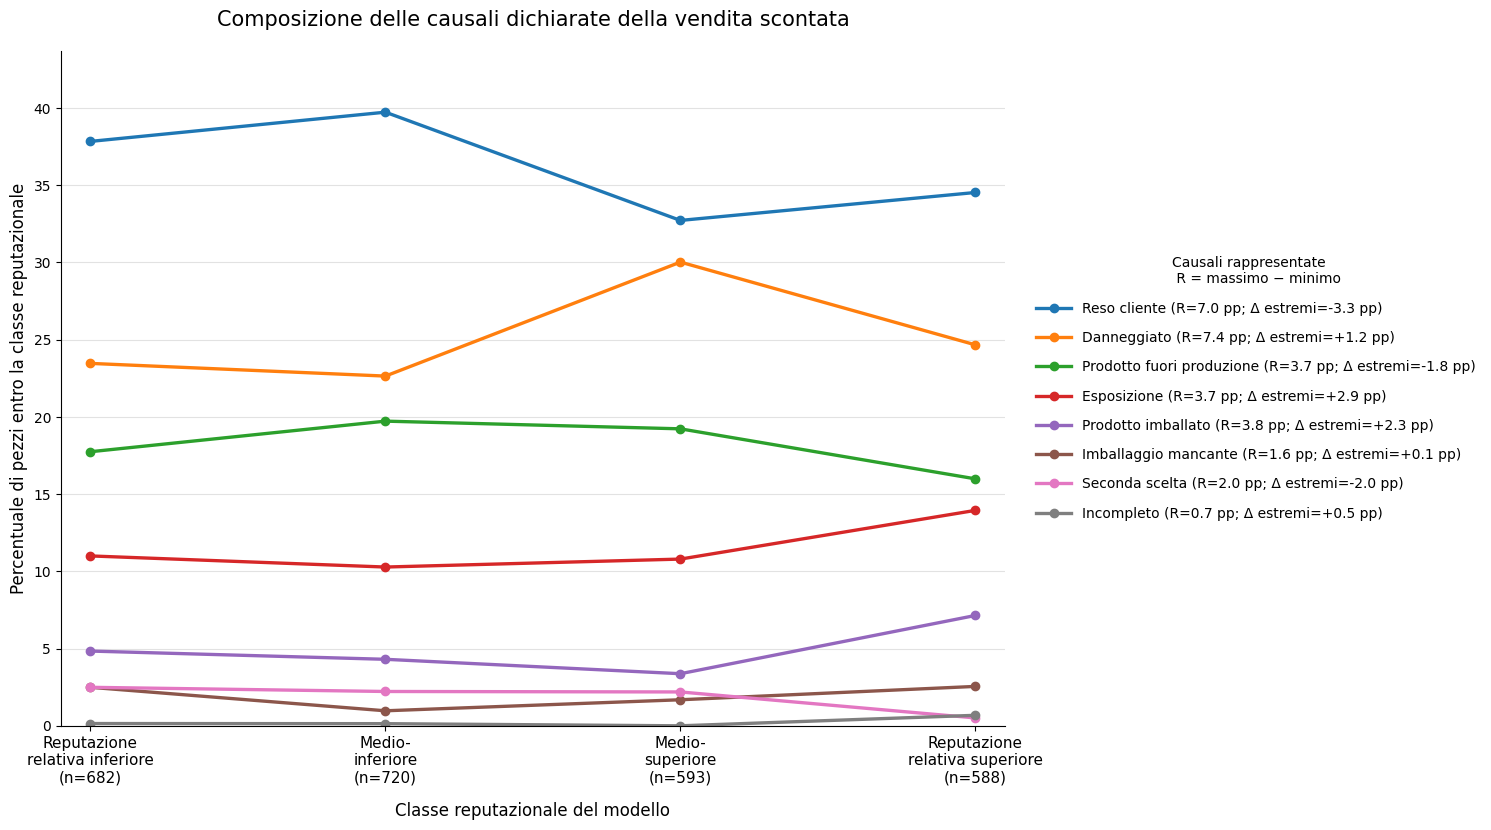

In [ ]:
# REPUTAZIONE E CAUSALE DICHIARATA DELLA VENDITA SCONTATA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ORDINE_CLASSI = ['Reputazione relativa inferiore', 'Medio-inferiore', 'Medio-superiore', 'Reputazione relativa superiore']

# ---------------------------------------------------------------
# Preparazione e controllo dei dati
dati = df_congiunto.copy()

def formatta_intero_italiano(x):
    return f'{int(x):,}'.replace(',', '.')

# Uniformazione della variabile Motivo Vendita: NaN e stringhe vuote vengono identificati come "Non specificato".
dati['Motivo Vendita'] = (dati['Motivo Vendita'].astype('string').str.strip().replace('', pd.NA).fillna('Non specificato'))

# Distribuzione preliminare del Motivo Vendita
distribuzione_motivo = (dati['Motivo Vendita'].value_counts(dropna=False).rename_axis('Motivo Vendita').to_frame(name='Pezzi'))
display(HTML('<h4>Distribuzione dei pezzi per Motivo Vendita</h4> <p>La categoria "Non specificato" identifica i casi nei quali la causale non è disponibile.</p>'))
display(distribuzione_motivo.style.format({'Pezzi': formatta_intero_italiano}))
print(f'Pezzi complessivamente osservati: {formatta_intero_italiano(len(dati))}')

# Controllo della causale non specificata per classe
dati['Causale non specificata'] = (dati['Motivo Vendita'].eq('Non specificato'))
riepilogo_non_specificato = (dati.groupby('Classe Reputazionale', observed=False).agg(Pezzi_totali=('Motivo Vendita', 'size'), Non_specificato=('Causale non specificata', 'sum')).reindex(ORDINE_CLASSI))
riepilogo_non_specificato['Percentuale_non_specificato'] = (riepilogo_non_specificato['Non_specificato'].div(riepilogo_non_specificato['Pezzi_totali']).mul(100))
riepilogo_non_specificato.index.name = 'Classe reputazionale'

display(HTML('<h4>Causale non specificata per classe reputazionale</h4> <p>La percentuale è calcolata sul totale dei pezzi appartenenti a ciascuna classe.</p>'))
display(riepilogo_non_specificato.style.format({'Pezzi_totali': formatta_intero_italiano,'Non_specificato': formatta_intero_italiano,'Percentuale_non_specificato': '{:.1f}%'}))
n_non_specificato = int(dati['Causale non specificata'].sum())

percentuale_non_specificato = (n_non_specificato / len(dati) * 100 if len(dati) > 0 else np.nan)
print(f'Pezzi esclusi per causale non specificata: {formatta_intero_italiano(n_non_specificato)} ({percentuale_non_specificato:.1f}%).')

# Definizione del campione analitico
# "Non specificato" rappresenta un valore mancante e non una causale sostantiva: viene quindi escluso dall'analisi
dati = (dati.loc[~dati['Causale non specificata']].drop(columns='Causale non specificata').copy())
print(f'Pezzi inclusi nell’analisi delle causali specificate: {formatta_intero_italiano(len(dati))}.')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Frequenze e composizioni percentuali
cont_n = (pd.crosstab(dati['Classe Reputazionale'],dati['Motivo Vendita']).reindex(ORDINE_CLASSI).fillna(0).astype(int))
classi_assenti = cont_n.index[cont_n.sum(axis=1).eq(0)].tolist()

if classi_assenti:
    raise ValueError(f'Classi reputazionali prive di osservazioni: {classi_assenti}')

ordine_motivi = (cont_n.sum(axis=0).sort_values(ascending=False).index)
cont_n = cont_n[ordine_motivi]

# Percentuali calcolate entro ciascuna classe reputazionale
cont_pct = cont_n.div(cont_n.sum(axis=1), axis=0) * 100
assert np.allclose(cont_pct.sum(axis=1), 100)
n_per_classe = cont_n.sum(axis=1)
tabella_n_pct = pd.DataFrame(index=cont_n.index,columns=cont_n.columns,dtype=object)

for classe in cont_n.index:
    for motivo in cont_n.columns:
        n = cont_n.loc[classe, motivo]
        pct = cont_pct.loc[classe, motivo]
        tabella_n_pct.loc[classe, motivo] = (f'{formatta_intero_italiano(n)} ({pct:.1f}%)')

tabella_n_pct['Totale classe'] = [f'{formatta_intero_italiano(n)} (100,0%)' for n in n_per_classe]
tabella_n_pct.index.name = 'Classe reputazionale'
display(HTML('<h4>Composizione del Motivo Vendita per classe reputazionale</h4> <p>Valori espressi come frequenza assoluta e percentuale entro la classe.</p>'))
display(tabella_n_pct)
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Indicatori di variazione
classe_inferiore = ORDINE_CLASSI[0]
classe_superiore = ORDINE_CLASSI[-1]

# Differenza dotata di segno tra le due classi estreme
delta_estremi = (cont_pct.loc[classe_superiore] - cont_pct.loc[classe_inferiore])

# Escursione complessiva tra tutte e quattro le classi
escursione_complessiva = (cont_pct.max(axis=0) - cont_pct.min(axis=0))

# Classe in cui ciascuna causale raggiunge minimo e massimo
classe_minimo = cont_pct.idxmin(axis=0)
classe_massimo = cont_pct.idxmax(axis=0)

tabella_variazione = pd.DataFrame({'Classe inferiore (%)': cont_pct.loc[classe_inferiore],
                                    'Medio-inferiore (%)': cont_pct.loc[ORDINE_CLASSI[1]],
                                    'Medio-superiore (%)': cont_pct.loc[ORDINE_CLASSI[2]],
                                    'Classe superiore (%)': cont_pct.loc[classe_superiore],
                                    'Δ estremi (pp)': delta_estremi,
                                    'Escursione complessiva (pp)': escursione_complessiva,
                                    'Minimo nella classe': classe_minimo,
                                    'Massimo nella classe': classe_massimo})

tabella_variazione = (tabella_variazione.sort_values('Escursione complessiva (pp)',ascending=False))
display(HTML('<h4>Variazione delle causali tra le classi reputazionali</h4>'))
display(tabella_variazione.style.format({'Classe inferiore (%)': '{:.1f}','Medio-inferiore (%)': '{:.1f}','Medio-superiore (%)': '{:.1f}','Classe superiore (%)': '{:.1f}','Δ estremi (pp)': '{:+.2f}','Escursione complessiva (pp)': '{:.2f}'}))
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Ordinamento e colori delle causali
motivi_rappresentati = cont_pct.columns.tolist()
cmap = plt.get_cmap('tab10')
colori = {motivo: cmap(i % cmap.N) for i, motivo in enumerate(motivi_rappresentati)}
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Slope chart completo
fig, ax = plt.subplots(figsize=(16, 9))
x = np.arange(len(ORDINE_CLASSI))

for motivo in motivi_rappresentati:
    esc = escursione_complessiva[motivo]
    delta = delta_estremi[motivo]
    ax.plot(x,cont_pct[motivo].to_numpy(),marker='o',linewidth=2.4,markersize=6,color=colori[motivo],label=(f'{motivo} (R={esc:.1f} pp; Δ estremi={delta:+.1f} pp)'), zorder=2)

etichette_classi = [('Reputazione\nrelativa inferiore\n'
                        f'(n={formatta_intero_italiano(n_per_classe.iloc[0])})'),
                    ('Medio-\ninferiore\n'
                        f'(n={formatta_intero_italiano(n_per_classe.iloc[1])})'),
                    ('Medio-\nsuperiore\n'
                        f'(n={formatta_intero_italiano(n_per_classe.iloc[2])})'),
                    ('Reputazione\nrelativa superiore\n'
                        f'(n={formatta_intero_italiano(n_per_classe.iloc[3])})')]

ax.set_xticks(x)
ax.set_xticklabels(etichette_classi, fontsize=11)
ax.set_ylabel('Percentuale di pezzi entro la classe reputazionale', fontsize=12)
ax.set_xlabel('Classe reputazionale del modello', fontsize=12, labelpad=12)
ax.set_title('Composizione delle causali dichiarate della vendita scontata', fontsize=15, pad=18)
massimo_osservato = cont_pct.to_numpy().max()
ax.set_ylim(0, massimo_osservato * 1.10)
ax.set_xlim(-0.10, len(ORDINE_CLASSI) - 0.90)
ax.grid(axis='y',color='#E2E2E2',linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='y',labelsize=10)
ax.legend(title=('Causali rappresentate\n R = massimo − minimo'),loc='center left',bbox_to_anchor=(1.02, 0.5),frameon=False,fontsize=10,title_fontsize=10,labelspacing=1.1,handlelength=2.5)
fig.subplots_adjust(left=0.09,right=0.68,top=0.90,bottom=0.15)
plt.show()
# ---------------------------------------------------------------

Pezzi esclusi perché privi di Voto Generale: 0
Pezzi inclusi nella classificazione reputazionale: 2,592

Numerosità delle fasce reputazionali assolute


,Articoli,Pezzi,Pezzi per articolo,Percentuale articoli,Percentuale pezzi
Fascia reputazionale,,,,,
Negativa,4,7,1.75,0.4%,0.3%
Neutra,31,124,4.00,3.0%,4.8%
Positiva,999,"2,461",2.46,96.6%,94.9%



Distribuzione del Voto Generale nelle fasce


,Articoli,Minimo,Mediana,Media,Massimo
Fascia reputazionale,,,,,
Negativa,4,1.75,1.90,1.97,2.33
Neutra,31,2.59,3.25,3.19,3.48
Positiva,999,3.50,4.50,4.46,5.00



Pezzi esclusi dall’analisi delle causali per causale non specificata: 9 (0.3%)
Pezzi inclusi nell’analisi delle causali specificate: 2,583

Composizione del Motivo Vendita per fascia reputazionale assoluta


Fascia reputazionale,Negativa,Neutra,Positiva,Totale
Motivo Vendita,,,,
Reso cliente,4 (57.1%),39 (31.5%),898 (36.6%),941
Danneggiato,2 (28.6%),21 (16.9%),623 (25.4%),646
Prodotto fuori produzione,1 (14.3%),30 (24.2%),440 (17.9%),471
Esposizione,0 (0.0%),18 (14.5%),277 (11.3%),295
Prodotto imballato,0 (0.0%),10 (8.1%),116 (4.7%),126
Imballaggio mancante,0 (0.0%),5 (4.0%),44 (1.8%),49
Seconda scelta,0 (0.0%),0 (0.0%),49 (2.0%),49
Incompleto,0 (0.0%),1 (0.8%),5 (0.2%),6


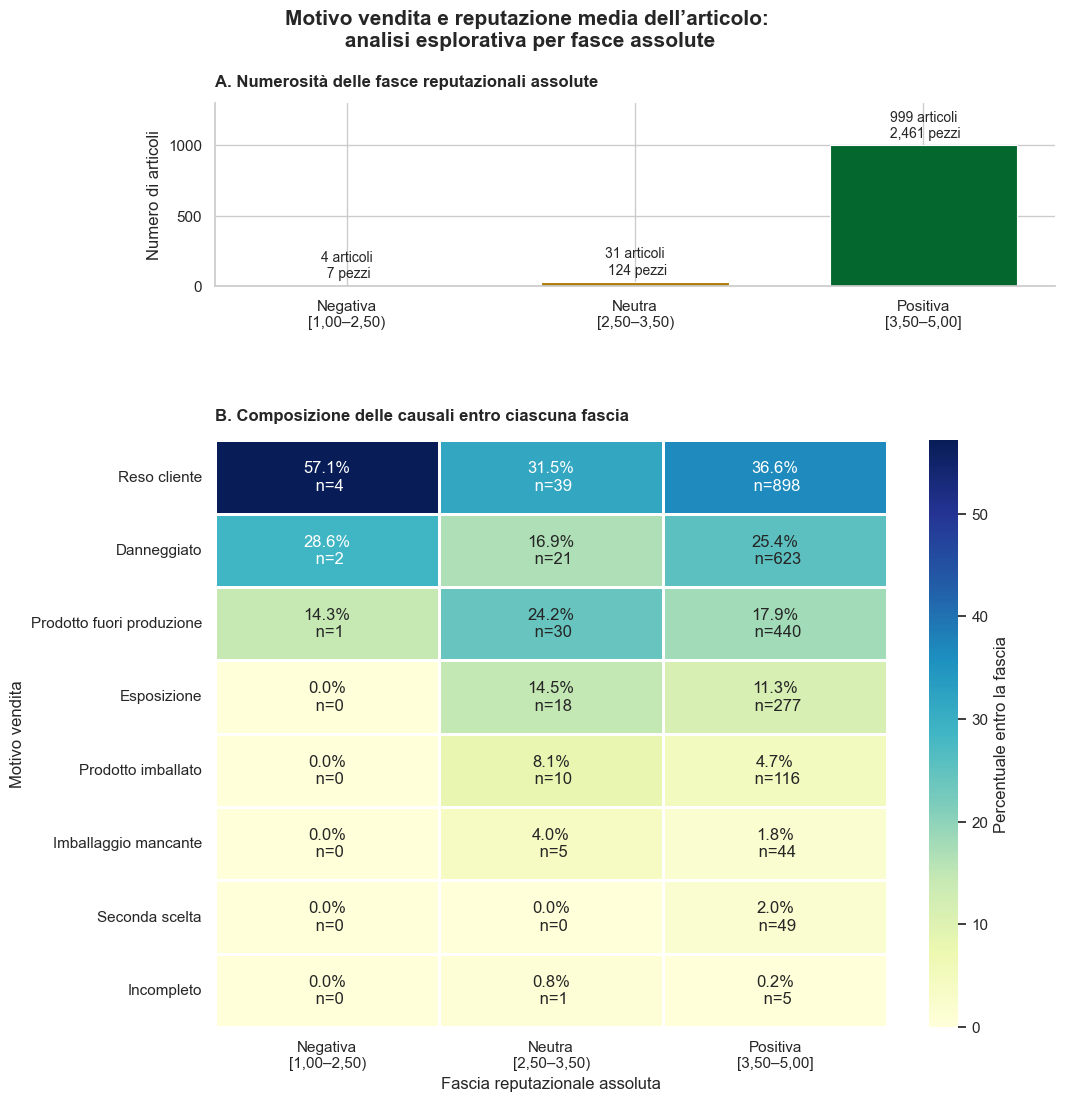

In [ ]:
# Altra lettura: analisi esplorativa aggiuntiva per fasce reputazionali assolute
# - Negativa: [1,00 – 2,50)
# - Neutra:   [2,50 – 3,50)
# - Positiva: [3,50 – 5,00]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

COLONNA_ARTICOLO = 'Numero Articolo Catalogo'
COLONNA_VOTO = 'Voto Generale'
COLONNA_CAUSALE = 'Motivo Vendita'
COLONNA_FASCIA = 'Fascia Reputazionale Assoluta'
ORDINE_FASCE = ['Negativa','Neutra','Positiva']
ETICHETTE_FASCE = {'Negativa': 'Negativa\n[1,00–2,50)','Neutra': 'Neutra\n[2,50–3,50)','Positiva': 'Positiva\n[3,50–5,00]'}
ORDINE_CAUSALI = ['Reso cliente','Danneggiato','Prodotto fuori produzione','Esposizione','Prodotto imballato','Imballaggio mancante','Seconda scelta','Incompleto']
COLORI_FASCE = [ "#810606",  "#AF7C0D",  "#03672E"]

# ---------------------------------------------------------------
# Preparazione del dataset
dati_fasce = df_congiunto.copy()
colonne_richieste = [COLONNA_ARTICOLO,COLONNA_VOTO,COLONNA_CAUSALE]
colonne_mancanti = [colonna for colonna in colonne_richieste if colonna not in dati_fasce.columns]

if colonne_mancanti:
    raise KeyError('Nel DataFrame df_congiunto mancano le seguenti colonne: ' + ', '.join(colonne_mancanti))

dati_fasce[COLONNA_VOTO] = pd.to_numeric(dati_fasce[COLONNA_VOTO], errors='coerce')
voti_fuori_scala = (dati_fasce[COLONNA_VOTO].notna() & ~dati_fasce[COLONNA_VOTO].between(1, 5))

if voti_fuori_scala.any():
    valori_problematici = sorted(dati_fasce.loc[voti_fuori_scala, COLONNA_VOTO].unique())
    raise ValueError('Sono presenti valori del Voto Generale esterni alla scala 1–5: {valori_problematici}')

voti_per_articolo = (dati_fasce.dropna(subset=[COLONNA_ARTICOLO, COLONNA_VOTO]).groupby(COLONNA_ARTICOLO)[COLONNA_VOTO].nunique())
articoli_con_voti_incoerenti = voti_per_articolo[voti_per_articolo > 1]

if not articoli_con_voti_incoerenti.empty:
    raise ValueError('Alcuni articoli presentano più di un Voto Generale. Controllare la costruzione di df_congiunto.')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Costruzione delle tre fasce assolute
dati_fasce[COLONNA_FASCIA] = pd.cut(dati_fasce[COLONNA_VOTO],bins=[-np.inf, 2.5, 3.5, np.inf],labels=ORDINE_FASCE,right=False,ordered=True)
n_pezzi_senza_voto = dati_fasce[COLONNA_FASCIA].isna().sum()
print(f'Pezzi esclusi perché privi di Voto Generale: {n_pezzi_senza_voto:,}')

dati_con_fascia = dati_fasce.loc[dati_fasce[COLONNA_FASCIA].notna()].copy()
print(f'Pezzi inclusi nella classificazione reputazionale: {len(dati_con_fascia):,}')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Numerosità di articoli e pezzi per fascia
articoli_univoci = (dati_con_fascia[[COLONNA_ARTICOLO,COLONNA_VOTO,COLONNA_FASCIA]].drop_duplicates(subset=COLONNA_ARTICOLO))
n_articoli = (articoli_univoci[COLONNA_FASCIA].value_counts(sort=False).reindex(ORDINE_FASCE, fill_value=0).astype(int))
n_pezzi = (dati_con_fascia[COLONNA_FASCIA].value_counts(sort=False).reindex(ORDINE_FASCE, fill_value=0).astype(int))
riepilogo_fasce = pd.DataFrame({'Articoli': n_articoli,'Pezzi': n_pezzi})
riepilogo_fasce['Pezzi per articolo'] = (riepilogo_fasce['Pezzi'].div(riepilogo_fasce['Articoli'].replace(0, np.nan)))
riepilogo_fasce['Percentuale articoli'] = (riepilogo_fasce['Articoli'].div(riepilogo_fasce['Articoli'].sum()).mul(100))
riepilogo_fasce['Percentuale pezzi'] = (riepilogo_fasce['Pezzi'].div(riepilogo_fasce['Pezzi'].sum()).mul(100))
riepilogo_fasce.index.name = 'Fascia reputazionale'

print('\nNumerosità delle fasce reputazionali assolute')
display(riepilogo_fasce.style.format({'Articoli': '{:,.0f}','Pezzi': '{:,.0f}','Pezzi per articolo': '{:.2f}','Percentuale articoli': '{:.1f}%','Percentuale pezzi': '{:.1f}%'}))
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Statistiche del Voto Generale nelle tre fasce
riepilogo_voti = (articoli_univoci.groupby(COLONNA_FASCIA,observed=False)[COLONNA_VOTO].agg(Articoli='size',Minimo='min',Mediana='median',Media='mean',Massimo='max').reindex(ORDINE_FASCE))
riepilogo_voti.index.name = 'Fascia reputazionale'

print('\nDistribuzione del Voto Generale nelle fasce')
display(riepilogo_voti.style.format({'Articoli': '{:,.0f}','Minimo': '{:.2f}','Mediana': '{:.2f}','Media': '{:.2f}','Massimo': '{:.2f}'}))
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Esclusione delle causali non specificate
causale_normalizzata = (dati_con_fascia[COLONNA_CAUSALE].astype('string').str.strip())
causale_non_specificata = (causale_normalizzata.isna() | causale_normalizzata.eq('') | causale_normalizzata.str.casefold().eq('non specificato'.casefold()))
n_causali_non_specificate = causale_non_specificata.sum()
percentuale_non_specificata = (n_causali_non_specificate / len(dati_con_fascia) * 100 if len(dati_con_fascia) > 0 else np.nan)

print(f'\nPezzi esclusi dall’analisi delle causali per causale non specificata: {n_causali_non_specificate:,} ({percentuale_non_specificata:.1f}%)')
dati_causali = dati_con_fascia.loc[~causale_non_specificata].copy()

dati_causali[COLONNA_CAUSALE] = (dati_causali[COLONNA_CAUSALE].astype('string').str.strip())
print(f'Pezzi inclusi nell’analisi delle causali specificate: {len(dati_causali):,}')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Frequenze assolute e percentuali delle causali per fascia
cont_n = (pd.crosstab(dati_causali[COLONNA_CAUSALE],dati_causali[COLONNA_FASCIA]).reindex(index=ORDINE_CAUSALI,columns=ORDINE_FASCE,fill_value=0).astype(int))
cont_n.index.name = 'Motivo Vendita'
cont_n.columns.name = 'Fascia reputazionale'

totali_causali_fascia = cont_n.sum(axis=0)
cont_pct = (cont_n.div(totali_causali_fascia.replace(0, np.nan),axis=1).mul(100))
cont_pct.index.name = 'Motivo Vendita'
cont_pct.columns.name = 'Fascia reputazionale'

# Tabella combinata: frequenza assoluta e percentuale
tabella_combinata = cont_n.copy().astype(object)

for causale in ORDINE_CAUSALI:
    for fascia in ORDINE_FASCE:
        frequenza = cont_n.loc[causale, fascia]
        percentuale = cont_pct.loc[causale, fascia]
        if pd.isna(percentuale):
            tabella_combinata.loc[causale, fascia] = (f'{frequenza:,} (n.d.)')
        else:
            tabella_combinata.loc[causale, fascia] = (f'{frequenza:,} ({percentuale:.1f}%)')

tabella_combinata['Totale'] = cont_n.sum(axis=1).map(lambda valore: f'{valore:,}')

print('\nComposizione del Motivo Vendita per fascia reputazionale assoluta')
display(tabella_combinata)
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Annotazioni per la heatmap
annotazioni = cont_pct.copy().astype(object)

for causale in ORDINE_CAUSALI:
    for fascia in ORDINE_FASCE:

        frequenza = cont_n.loc[causale, fascia]
        percentuale = cont_pct.loc[causale, fascia]

        if pd.isna(percentuale):
            annotazioni.loc[causale, fascia] = 'n.d.'
        else:
            annotazioni.loc[causale, fascia] = (f'{percentuale:.1f}%\n n={frequenza:,}')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Figure
sns.set_theme(style='whitegrid',context='notebook')
fig = plt.figure(figsize=(12, 11))
griglia = fig.add_gridspec(nrows=2,ncols=1,height_ratios=[1, 3.2],hspace=0.40)

# Pannello A: numerosità degli articoli
ax1 = fig.add_subplot(griglia[0])
posizioni = np.arange(len(ORDINE_FASCE))
barre = ax1.bar(posizioni,n_articoli.values,color=COLORI_FASCE,width=0.65,edgecolor='white',linewidth=0.8)
massimo_articoli = max(n_articoli.max(), 1)

for barra, fascia in zip(barre, ORDINE_FASCE):
    ax1.text(barra.get_x() + barra.get_width() / 2,barra.get_height() + massimo_articoli * 0.035,(f'{n_articoli.loc[fascia]:,} articoli\n {n_pezzi.loc[fascia]:,} pezzi'),ha='center',va='bottom',fontsize=10)

ax1.set_xticks(posizioni,[ETICHETTE_FASCE[fascia] for fascia in ORDINE_FASCE])
ax1.set_ylabel('Numero di articoli')
ax1.set_xlabel('')
ax1.set_title('A. Numerosità delle fasce reputazionali assolute',loc='left',fontweight='bold',pad=12)
ax1.set_ylim(0,massimo_articoli * 1.30)
ax1.spines[['top', 'right']].set_visible(False)

# Pannello B: heatmap della composizione delle causali
ax2 = fig.add_subplot(griglia[1])
valori_finiti = cont_pct.to_numpy(dtype=float)
valori_finiti = valori_finiti[np.isfinite(valori_finiti)]

if valori_finiti.size == 0:
    massimo_percentuale = 1
else:
    massimo_percentuale = valori_finiti.max()

sns.heatmap(cont_pct,annot=annotazioni,fmt='',cmap='YlGnBu',vmin=0,vmax=massimo_percentuale,linewidths=0.8,linecolor='white',mask=cont_pct.isna(),cbar_kws={'label': 'Percentuale entro la fascia'},ax=ax2)
ax2.set_xticklabels([ETICHETTE_FASCE[fascia] for fascia in ORDINE_FASCE],rotation=0)
ax2.set_yticklabels(ax2.get_yticklabels(),rotation=0)
ax2.set_xlabel('Fascia reputazionale assoluta')
ax2.set_ylabel('Motivo vendita')
ax2.set_title('B. Composizione delle causali entro ciascuna fascia',loc='left',fontweight='bold',pad=14)
fig.suptitle('Motivo vendita e reputazione media dell’articolo:\n analisi esplorativa per fasce assolute',fontsize=15,fontweight='bold',y=0.995)
plt.subplots_adjust(top=0.91,bottom=0.07,left=0.24,right=0.94)
plt.show()
# ---------------------------------------------------------------

-> **Reputazione e condizione dell'usato**

In [ ]:
# ---------------------------------------------------------------
# Distribuzione generale della Condizione Usato (indipendente dalla classe)

dist_generale = df_congiunto['Condizione Usato'].value_counts(dropna=False)

tabella_generale = pd.DataFrame({'Pezzi': dist_generale, '% sul totale': (dist_generale / len(df_congiunto) * 100).round(1)})
tabella_generale.index.name = 'Condizione Usato'
tabella_generale = tabella_generale.rename(index={np.nan: 'Valore mancante (NaN)'})

display(HTML("<h4>Distribuzione generale della Condizione Usato</h4>"))
display(tabella_generale)
print(f'Totale pezzi: {len(df_congiunto):,}'.replace(',', '.'))
print(f'Modalità distinte osservate: {df_congiunto["Condizione Usato"].nunique(dropna=True)}')
# ---------------------------------------------------------------

,Pezzi,% sul totale
Condizione Usato,,
Come nuovo,1071,41.3
Nuovissimo,791,30.5
Buono,613,23.6
Valore mancante (NaN),49,1.9
Discreto,38,1.5
Seconda scelta,16,0.6
Pezzi mancanti,14,0.5


Totale pezzi: 2.592
Modalità distinte osservate: 6


Condizione Usato,Discreto,Buono,Come nuovo,Nuovissimo,Pezzi mancanti,Seconda scelta
Classe reputazionale,,,,,,
Reputazione relativa inferiore,7 (1.0%),184 (27.5%),263 (39.3%),215 (32.1%),1 (0.1%),0 (0.0%)
Medio-inferiore,7 (1.0%),158 (22.0%),301 (41.9%),236 (32.8%),7 (1.0%),10 (1.4%)
Medio-superiore,10 (1.7%),128 (22.3%),244 (42.4%),185 (32.2%),4 (0.7%),4 (0.7%)
Reputazione relativa superiore,14 (2.4%),143 (24.7%),263 (45.4%),155 (26.8%),2 (0.3%),2 (0.3%)


Pezzi esclusi (condizione mancante): 49 (1.9%).


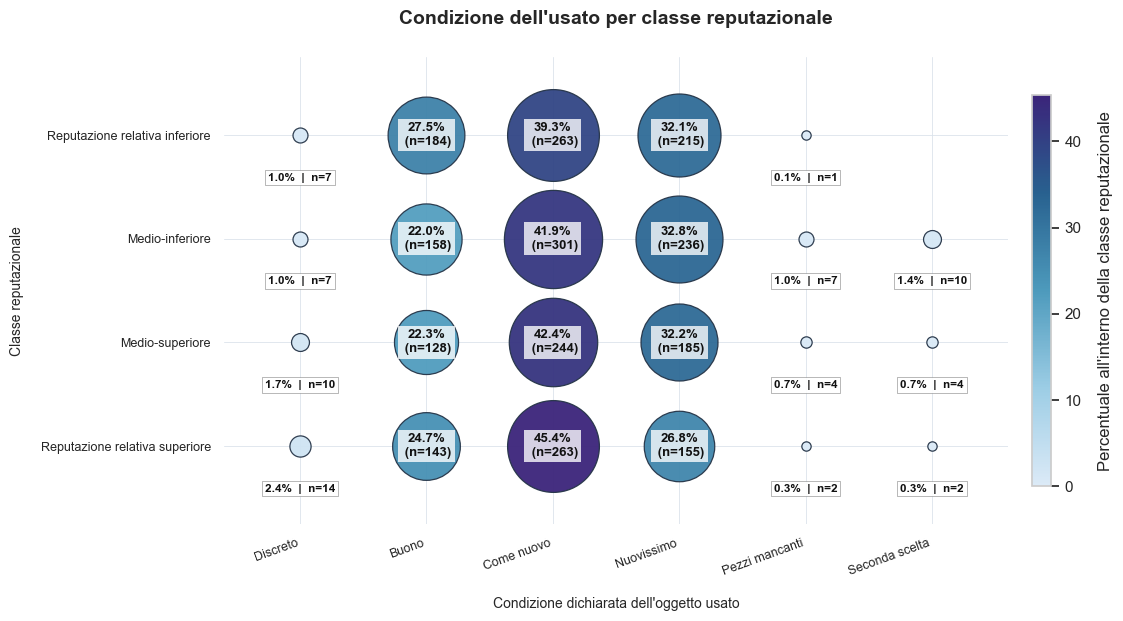

In [ ]:
# CONDIZIONE USATO PER CLASSE REPUTAZIONALE
import matplotlib.pyplot as plt

ORDINE_CLASSI = ['Reputazione relativa inferiore', 'Medio-inferiore', 'Medio-superiore', 'Reputazione relativa superiore']
ORDINE_CONDIZIONE = ['Discreto', 'Buono', 'Come nuovo', 'Nuovissimo', 'Pezzi mancanti', 'Seconda scelta']

# ---------------------------------------------------------------
# Composizione per classe reputazionale
dati = df_congiunto.dropna(subset=['Condizione Usato', 'Classe Reputazionale']).copy()
n_esclusi = len(df_congiunto) - len(dati)

cont_n = (pd.crosstab(dati['Classe Reputazionale'], dati['Condizione Usato']).reindex(index=ORDINE_CLASSI, columns=ORDINE_CONDIZIONE, fill_value=0).astype(int))
cont_pct = cont_n.div(cont_n.sum(axis=1), axis=0) * 100

tabella_combinata = pd.DataFrame(index=cont_n.index, columns=cont_n.columns, dtype=object)

for classe in cont_n.index:
    for cond in cont_n.columns:
        n_val, pct_val = cont_n.loc[classe, cond], cont_pct.loc[classe, cond]
        tabella_combinata.loc[classe, cond] = f'{n_val:,} ({pct_val:.1f}%)'.replace(',', '.')

tabella_combinata.index.name = 'Classe reputazionale'
display(HTML("<h4>Composizione della Condizione Usato per classe reputazionale (solo condizioni dichiarate)</h4>"))
display(tabella_combinata)
print(f'Pezzi esclusi (condizione mancante): {n_esclusi} ({n_esclusi/len(df_congiunto)*100:.1f}%).')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Bubble heatmap: Condizione dell'usato per classe reputazionale
# Colore = percentuale / Dimensione = numerosità assoluta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(12, 7))
n_classi = len(ORDINE_CLASSI)
n_cond = len(ORDINE_CONDIZIONE)
cmap = LinearSegmentedColormap.from_list('blu_viola', [ '#DCEAF7', '#9CCDE5', '#4D9ABC', '#28618F', '#3B247A'])
valore_massimo_pct = cont_pct.to_numpy(dtype=float).max()
norm = Normalize(vmin=0,vmax=valore_massimo_pct)
max_n = cont_n.to_numpy(dtype=float).max()

AREA_MINIMA = 45
AREA_MASSIMA = 5000

for i, classe in enumerate(ORDINE_CLASSI):
    for j, condizione in enumerate(ORDINE_CONDIZIONE):
        n_val = cont_n.loc[classe, condizione]
        pct_val = cont_pct.loc[classe, condizione]

        if pd.isna(n_val):
            n_val = 0
        if pd.isna(pct_val):
            pct_val = 0
        if n_val <= 0:
            continue

        # Area proporzionale a n, con dimensione minima leggibile
        area = max(AREA_MINIMA, AREA_MASSIMA * (n_val / max_n))
        colore = cmap(norm(pct_val))
        ax.scatter(j,i,s=area,color=colore,edgecolor='#253447',linewidth=0.9,alpha=0.95,zorder=3)

        # Etichette
        if n_val >= 20:
            # Cerchi grandi
            testo = (f'{pct_val:.1f}%\n (n={n_val:,})').replace(',', '.')
            ax.text(j,i,testo,ha='center',va='center',fontsize=9.5,fontweight='bold',color='#111111',zorder=5,bbox=dict(facecolor='white',edgecolor='none',alpha=0.78,pad=2.5))
        else:
            # Cerchi piccoli
            testo_piccolo = (f'{pct_val:.1f}%  |  n={n_val:,}').replace(',', '.')
            ax.annotate(testo_piccolo,xy=(j, i),xytext=(0, -27),textcoords='offset points',ha='center',va='top',fontsize=8.5,fontweight='bold',color='#111111',zorder=6,bbox=dict(facecolor='white',edgecolor='#777777',linewidth=0.4,alpha=0.92,pad=2))

# Assi
ax.set_xticks(range(n_cond))
ax.set_xticklabels(ORDINE_CONDIZIONE,rotation=20,ha='right',fontsize=9)
ax.set_yticks(range(n_classi))
ax.set_yticklabels(ORDINE_CLASSI,fontsize=9)
ax.set_xlim(-0.6, n_cond - 0.4)
ax.set_ylim(-0.75, n_classi - 0.25)
ax.invert_yaxis()

# Griglia 
ax.set_axisbelow(True)
ax.grid(axis='both',color='#D9E1EA',linewidth=0.7,alpha=0.8)

# Titoli e descrizioni
ax.set_xlabel("Condizione dichiarata dell'oggetto usato",labelpad=14,fontsize=10)
ax.set_ylabel("Classe reputazionale",labelpad=12,fontsize=10)
ax.set_title("Condizione dell'usato per classe reputazionale",fontsize=14,fontweight='bold',pad=24)

# Barra dei colori
sm = plt.cm.ScalarMappable(cmap=cmap,norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm,ax=ax,pad=0.025,shrink=0.84)
cbar.set_label("Percentuale all'interno della classe reputazionale", rotation=90, labelpad=12)

# Aspetto finale
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()
# ---------------------------------------------------------------

,Articoli,Pezzi
Gruppo reputazionale,,
Reputazione relativa inferiore,261,669
Resto del catalogo reputazionale,760,1844


,Reputazione inferiore (n),Reputazione inferiore (%),Resto del catalogo (n),Resto del catalogo (%),Differenza (p.p.)
Condizione Usato,,,,,
Discreto,7,1.0,31,1.7,-0.6
Buono,184,27.5,429,23.3,4.2
Come nuovo,263,39.3,808,43.8,-4.5
Nuovissimo,215,32.1,576,31.2,0.9
Totale,669,100.0,1844,100.0,0.0


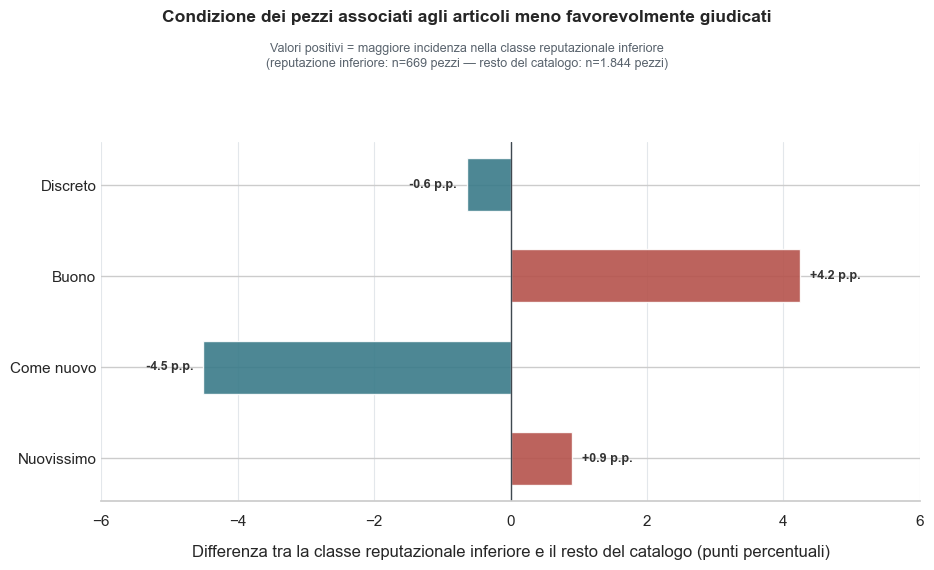

In [ ]:
# Approfondimento: classe reputazionale inferiore e resto del catalogo

# ---------------------------------------------------------------
# Classe reputazionale inferiore vs resto del catalogo

ORDINE_CONDIZIONE_ORDINALE = ['Discreto', 'Buono', 'Come nuovo', 'Nuovissimo']
ORDINE_GRUPPI = ['Reputazione relativa inferiore', 'Resto del catalogo reputazionale']

dati_binari = (df_congiunto.dropna(subset=['Classe Reputazionale','Condizione Usato']).copy())
dati_binari['Gruppo reputazionale'] = np.where(dati_binari['Classe Reputazionale'].eq('Reputazione relativa inferiore'),'Reputazione relativa inferiore','Resto del catalogo reputazionale')
dati_ord = dati_binari[dati_binari['Condizione Usato'].isin(ORDINE_CONDIZIONE_ORDINALE)].copy()

# Numerosità complessive dei gruppi
numerosita = (dati_ord.groupby('Gruppo reputazionale', observed=True).agg(Articoli=('Numero Articolo Catalogo', 'nunique'),Pezzi=('ID Prodotto', 'size')).reindex(ORDINE_GRUPPI))
display(HTML("<h4>Numerosità dei due gruppi a confronto</h4>"))
display(numerosita)

# Frequenze assolute e percentuali congiunte
confronto_n = (pd.crosstab(dati_ord['Gruppo reputazionale'],dati_ord['Condizione Usato']).reindex(index=ORDINE_GRUPPI,columns=ORDINE_CONDIZIONE_ORDINALE,fill_value=0))

# Percentuali calcolate separatamente all'interno dei gruppi
confronto_pct = (confronto_n.div(confronto_n.sum(axis=1), axis=0).mul(100))
differenze_pp = (confronto_pct.loc['Reputazione relativa inferiore'] - confronto_pct.loc['Resto del catalogo reputazionale'])

# Tabella con frequenze e percentuali affiancate
tabella_confronto = pd.DataFrame({'Reputazione inferiore (n)': confronto_n.loc['Reputazione relativa inferiore'],
                                  'Reputazione inferiore (%)': confronto_pct.loc['Reputazione relativa inferiore'],
                                  'Resto del catalogo (n)': confronto_n.loc['Resto del catalogo reputazionale'],
                                  'Resto del catalogo (%)': confronto_pct.loc['Resto del catalogo reputazionale'],
                                  'Differenza (p.p.)': differenze_pp})

# Riga totale: esplicita i denominatori dei due gruppi
tabella_confronto.loc['Totale'] = [confronto_n.loc['Reputazione relativa inferiore'].sum(),100.0,confronto_n.loc['Resto del catalogo reputazionale'].sum(),100.0,0.0]

# Formattazione separata per conteggi e misure percentuali
tabella_confronto[['Reputazione inferiore (n)','Resto del catalogo (n)']] = tabella_confronto[['Reputazione inferiore (n)','Resto del catalogo (n)']].astype(int)
tabella_confronto[['Reputazione inferiore (%)', 'Resto del catalogo (%)', 'Differenza (p.p.)']] = tabella_confronto[['Reputazione inferiore (%)', 'Resto del catalogo (%)', 'Differenza (p.p.)']].round(1)
tabella_confronto.index.name = 'Condizione Usato'

display(HTML("<h4>Confronto tra reputazione inferiore e resto del catalogo</h4>"))
display(tabella_confronto)

# Grafico: differenze nella composizione della condizione
n_inf = numerosita.loc['Reputazione relativa inferiore','Pezzi']
n_resto = numerosita.loc['Resto del catalogo reputazionale','Pezzi']

fig, ax = plt.subplots(figsize=(9.5, 5.8))

# Rosso: maggiore incidenza nella reputazione inferiore
# Blu: maggiore incidenza nel resto del catalogo
# Grigio: differenza nulla
colori = ['#B5524B' if valore > 0 else '#397A89' if valore < 0 else '#8A9299' for valore in differenze_pp]

y = np.arange(len(ORDINE_CONDIZIONE_ORDINALE))
ax.barh(y,differenze_pp,color=colori,height=0.58,alpha=0.90)
ax.axvline(0,color='#3F4850',linewidth=1)

for i, valore in enumerate(differenze_pp):
    ax.text(valore + (0.15 if valore >= 0 else -0.15), i, f'{valore:+.1f} p.p.', ha='left' if valore >= 0 else 'right', va='center', fontsize=9, fontweight='bold', color='#333333')

ax.set_yticks(y)
ax.set_yticklabels(ORDINE_CONDIZIONE_ORDINALE)
ax.invert_yaxis()
ax.set_xlabel('Differenza tra la classe reputazionale inferiore e il resto del catalogo (punti percentuali)', labelpad=12)
fig.suptitle('Condizione dei pezzi associati agli articoli meno favorevolmente giudicati',fontsize=12.5,fontweight='bold',y=0.98)
fig.text(0.5,0.90,('Valori positivi = maggiore incidenza nella classe reputazionale inferiore\n'f'(reputazione inferiore: n={n_inf:,} pezzi — 'f'resto del catalogo: n={n_resto:,} pezzi)').replace(',', '.'),ha='center', va='center', fontsize=9, color='#59636D')
ax.grid(axis='x',color='#DCE2E7',linewidth=0.8,alpha=0.8)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
limite = max(np.ceil(np.abs(differenze_pp).max()) + 1,3)
ax.set_xlim(-limite, limite)
plt.tight_layout(rect=[0, 0, 1, 0.84])
plt.show()
# ---------------------------------------------------------------

Articoli aggregati: 1.012
Articoli con moda non univoca: 126 (12,5%)
Articoli con un solo pezzo nelle condizioni considerate: 547
Articoli omogenei sull’intero stock osservato: 722


,count,mean,std,min,25%,50%,75%,max
Quota modale,1012.0,0.884,0.202,0.333,0.75,1.0,1.0,1.0
Copertura condizioni principali,1012.0,0.989,0.071,0.111,1.00,1.0,1.0,1.0
N pezzi principali,1012.0,2.457,3.457,1.000,1.00,1.0,3.0,56.0
N pezzi totali,1012.0,2.505,3.514,1.000,1.00,1.0,3.0,57.0


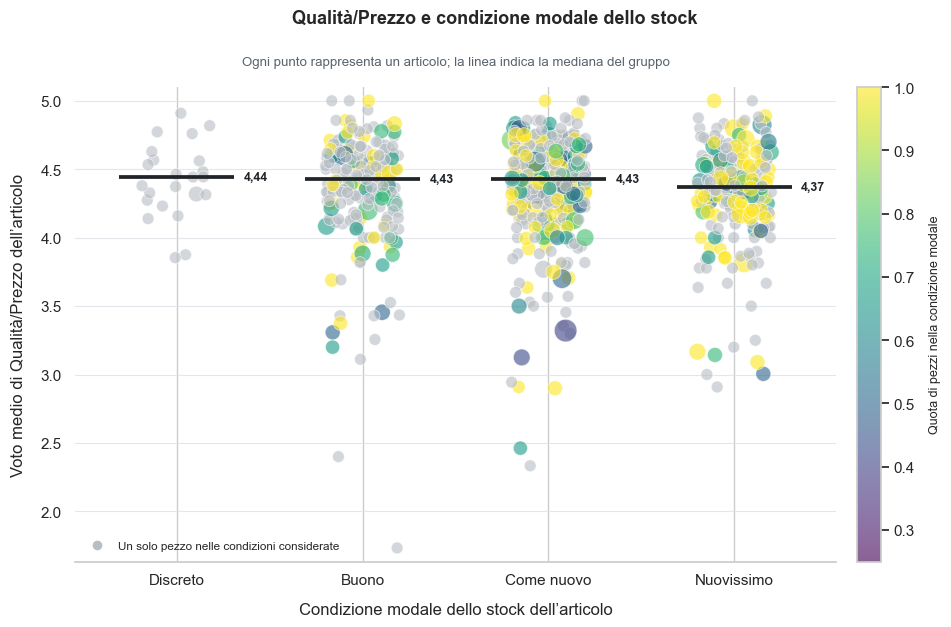

In [ ]:
# Qualità/Prezzo e condizione modale dello stock a livello di articolo

# ---------------------------------------------------------------
# Qualità/Prezzo per condizione modale
# Unità di analisi: livello articolo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

COL_ARTICOLO = 'Numero Articolo Catalogo'
COL_PEZZO = 'ID Prodotto'
COL_CONDIZIONE = 'Condizione Usato'
COL_QP = 'Qualità/Prezzo'
ORDINE_CONDIZIONI = ['Discreto','Buono','Come nuovo','Nuovissimo']

# Preparazione e controlli
base = df_congiunto[[COL_ARTICOLO, COL_PEZZO, COL_CONDIZIONE, COL_QP]].copy()
base[COL_QP] = pd.to_numeric(base[COL_QP],errors='coerce')
base = base.dropna(subset=[COL_ARTICOLO,COL_PEZZO,COL_QP]).copy()

# Ogni ID deve rappresentare un solo pezzo
if base[COL_PEZZO].duplicated().any():
    duplicati = (base.loc[base[COL_PEZZO].duplicated(False), COL_PEZZO].unique().tolist())
    raise ValueError(f"Sono presenti ID Prodotto duplicati. Controllare la cardinalità del merge. Esempi: {duplicati[:10]}")

# Qualità/Prezzo deve essere invariabile nell'articolo
n_qp = (base.groupby(COL_ARTICOLO, observed=True)[COL_QP].nunique())

if n_qp.gt(1).any():
    problematici = n_qp[n_qp.gt(1)].index.tolist()
    raise ValueError(f"Alcuni articoli presentano più valori di Qualità/Prezzo. Esempi: {problematici[:10]}")

# Numero complessivo di pezzi, comprese le condizioni non utilizzate nel confronto
n_pezzi_totali = (base.groupby(COL_ARTICOLO, observed=True)[COL_PEZZO].nunique().rename('N pezzi totali'))
qp_articolo = (base.groupby(COL_ARTICOLO, observed=True)[COL_QP].first().rename('Qualità/Prezzo'))

# Sottoinsieme delle condizioni principali
dati_principali = base[base[COL_CONDIZIONE].isin(ORDINE_CONDIZIONI)].copy()
frequenze = (dati_principali.groupby([COL_ARTICOLO, COL_CONDIZIONE],observed=True)[COL_PEZZO].nunique().rename('N condizione').reset_index())
n_pezzi_principali = (frequenze.groupby(COL_ARTICOLO, observed=True)['N condizione'].sum().rename('N pezzi principali'))
frequenza_massima = (frequenze.groupby(COL_ARTICOLO, observed=True)['N condizione'].max().rename('Frequenza modale'))

# Individuazione di tutte le modalità che raggiungono il massimo
candidate_mode = frequenze.merge(frequenza_massima.reset_index(),on=COL_ARTICOLO,how='inner')
candidate_mode = candidate_mode[candidate_mode['N condizione'].eq(candidate_mode['Frequenza modale'])].copy()
informazioni_moda = (candidate_mode.groupby(COL_ARTICOLO, observed=True).agg(Numero_mode=(COL_CONDIZIONE, 'size'),Condizione_modale=(COL_CONDIZIONE, 'first')))

# Dataset finale: una riga per articolo
per_articolo = pd.concat([qp_articolo,n_pezzi_totali,n_pezzi_principali,frequenza_massima,informazioni_moda],axis=1,join='inner').reset_index()
per_articolo['Moda univoca'] = (per_articolo['Numero_mode'].eq(1))

# Nei pareggi la condizione non viene assegnata
per_articolo.loc[ ~per_articolo['Moda univoca'], 'Condizione_modale'] = pd.NA
per_articolo['Quota modale'] = (per_articolo['Frequenza modale'].div(per_articolo['N pezzi principali']))

# Quanto le condizioni rappresentano lo stock totale
per_articolo['Copertura condizioni principali'] = (per_articolo['N pezzi principali'].div(per_articolo['N pezzi totali']))

if per_articolo[COL_ARTICOLO].duplicated().any():
    raise ValueError("L'aggregazione non ha prodotto una sola riga per articolo.")

# Diagnostica
n_articoli = len(per_articolo)
n_pareggi = (~per_articolo['Moda univoca']).sum()
n_singoli = per_articolo['N pezzi principali'].eq(1).sum()

# Purezza = 1 e copertura = 1: tutti i pezzi dell'articolo condividono la stessa condizione principale.
omogenei_completi = (per_articolo['Quota modale'].eq(1) & per_articolo['Copertura condizioni principali'].eq(1)).sum()

print(f'Articoli aggregati: {n_articoli:,}'.replace(',', '.'))
print(f'Articoli con moda non univoca: {n_pareggi:,} ({n_pareggi / n_articoli * 100:.1f}%)'.replace(',', 'X').replace('.', ',').replace('X', '.'))
print(f'Articoli con un solo pezzo nelle condizioni considerate: {n_singoli:,}'.replace(',', '.'))
print(f'Articoli omogenei sull’intero stock osservato: {omogenei_completi:,}'.replace(',', '.'))
display(HTML("<h4>Aggregazione a livello di articolo</h4>"))
display(per_articolo[['Quota modale','Copertura condizioni principali','N pezzi principali','N pezzi totali']].describe().round(3).T)

# Dati rappresentabili: solo moda univoca
dati_plot = per_articolo[per_articolo['Moda univoca']].copy()
dati_plot['Condizione_modale'] = pd.Categorical(dati_plot['Condizione_modale'],categories=ORDINE_CONDIZIONI,ordered=True)
x_pos = { condizione: posizione for posizione, condizione in enumerate(ORDINE_CONDIZIONI)}
rng = np.random.default_rng(42)
dati_plot['x'] = (dati_plot['Condizione_modale'] .map(x_pos) .astype(float) + rng.uniform(-0.20, 0.20, len(dati_plot)))

# La scala radice quadrata limita la dominanza grafica degli articoli con stock molto numeroso.
dati_plot['Dimensione punto'] = (28 + 45 * np.sqrt(dati_plot['N pezzi totali']))

# La quota modale dei singoli pezzi vale 1 per costruzione: vengono visualizzati in grigio anziché sulla scala cromatica.
dati_plot['Quota colore'] = (dati_plot['Quota modale'].mask(dati_plot['N pezzi principali'].eq(1)))
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Bubble strip plot
fig, ax = plt.subplots(figsize=(10.5, 6.5))

cmap = plt.colormaps['viridis'].copy()
cmap.set_bad('#B8BEC4')
sc = ax.scatter(dati_plot['x'],dati_plot['Qualità/Prezzo'],s=dati_plot['Dimensione punto'],c=dati_plot['Quota colore'],cmap=cmap,vmin=0.25,vmax=1,alpha=0.62,edgecolors='white',linewidths=0.6,plotnonfinite=True,zorder=3)
mediane = (dati_plot.groupby('Condizione_modale',observed=False)['Qualità/Prezzo'].median().reindex(ORDINE_CONDIZIONI))

for condizione, mediana in mediane.dropna().items():
    posizione = x_pos[condizione]
    ax.hlines(y=mediana,xmin=posizione - 0.31,xmax=posizione + 0.31,color='#202428',linewidth=2.7,zorder=5)
    ax.annotate(f'{mediana:.2f}'.replace('.', ','),xy=(posizione + 0.33, mediana),xytext=(4, 0),textcoords='offset points',ha='left',va='center',fontsize=9,fontweight='bold',color='#202428')

ax.set_xticks(range(len(ORDINE_CONDIZIONI)))
ax.set_xticklabels(ORDINE_CONDIZIONI)
ax.set_xlim(-0.55,len(ORDINE_CONDIZIONI) - 0.45)
margine_y = 0.10
ax.set_ylim(dati_plot['Qualità/Prezzo'].min() - margine_y,dati_plot['Qualità/Prezzo'].max() + margine_y)
ax.set_xlabel('Condizione modale dello stock dell’articolo', labelpad=11)
ax.set_ylabel('Voto medio di Qualità/Prezzo dell’articolo', labelpad=11)
ax.grid(axis='y',color='#DDE2E6',linewidth=0.8,alpha=0.8,zorder=0)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='x', length=0, pad=8)
cbar = fig.colorbar(sc,ax=ax,pad=0.025,fraction=0.045)
cbar.set_label('Quota di pezzi nella condizione modale',fontsize=9,labelpad=10)

simbolo_singolo = Line2D([0],[0],marker='o',linestyle='none',markerfacecolor='#B8BEC4',markeredgecolor='white',markersize=8,label='Un solo pezzo nelle condizioni considerate')
ax.legend(handles=[simbolo_singolo],loc='lower left',frameon=False,fontsize=8.5)

fig.suptitle('Qualità/Prezzo e condizione modale dello stock',fontsize=13,fontweight='bold',y=0.98)
ax.set_title(('Ogni punto rappresenta un articolo; la linea indica la mediana del gruppo'),fontsize=9.5,color='#59636D',pad=16)
fig.subplots_adjust(left=0.10,right=0.88,top=0.86,bottom=0.13)
plt.show()
# ---------------------------------------------------------------

## **5.4. Analisi predittiva dello sconto**

-> **Definizione dei modelli e impostazione della validazione predittiva**

In [ ]:
# ---------------------------------------------------------------
# Definizione del campione e dei predittori
import numpy as np
import pandas as pd
from IPython.display import display, HTML

mod = df_congiunto.copy().reset_index(drop=True)

COL_ARTICOLO = 'Numero Articolo Catalogo'
COL_PEZZO = 'ID Prodotto'
COL_TARGET = 'Sconto'

# Dimensioni reputazionali selezionate in precedenza
REP = ['Voto Generale', 'Qualità/Prezzo', 'Estetica', 'Montaggio']

# Predittori numerici del Modello A
NUM_A = ['Prezzo Originale', 'Disponibilità']

# Predittori categoriali del Modello A
CAT_A = ['Categoria Prodotto', 'Condizione Usato', 'Motivo Vendita', 'Imballaggio Presente', 'Nome Negozio']

# Tutte le colonne necessarie per costruire l'analisi e controlli
colonne_necessarie = ([COL_ARTICOLO, COL_PEZZO, COL_TARGET] + NUM_A + CAT_A + REP + ['N Recensioni'])
colonne_assenti = sorted(set(colonne_necessarie) - set(mod.columns))

if colonne_assenti:
    raise KeyError(f'Nel dataset mancano le seguenti colonne necessarie: {colonne_assenti}')

if mod[[COL_ARTICOLO, COL_PEZZO]].isna().any().any():
    raise ValueError('Sono presenti valori mancanti nelle chiavi identificative.')

if not mod[COL_PEZZO].is_unique:
    duplicati = (mod.loc[mod[COL_PEZZO].duplicated(keep=False), COL_PEZZO].unique().tolist())
    raise ValueError(f'ID Prodotto non univoco: controllare il merge. Esempi: {duplicati[:10]}')

for colonna in [COL_TARGET] + NUM_A:
    if not pd.api.types.is_numeric_dtype(mod[colonna]):
        raise TypeError(f'La colonna {colonna} non presenta un formato numerico.')

if mod[COL_TARGET].isna().any():
    raise ValueError('La variabile Sconto contiene valori mancanti.')

if not np.isfinite(mod[COL_TARGET]).all():
    raise ValueError('La variabile Sconto contiene valori non finiti.')

if not mod[COL_TARGET].between(0, 100).all():
    raise ValueError('Sono presenti valori di Sconto esterni all’intervallo 0–100.')

if mod['Prezzo Originale'].isna().any():
    raise ValueError('Prezzo Originale contiene valori mancanti.')

if (mod['Prezzo Originale'] <= 0).any():
    raise ValueError('Prezzo Originale contiene valori nulli o negativi.')

if mod['Disponibilità'].isna().any():
    raise ValueError('Disponibilità contiene valori mancanti.')

if (mod['Disponibilità'] <= 0).any():
    raise ValueError('Disponibilità contiene valori nulli o negativi.')

if not np.allclose(mod['Disponibilità'], np.round(mod['Disponibilità'])):
    raise ValueError('Disponibilità contiene valori non interi.')

# Le variabili reputazionali e N Recensioni sono definite a livello di articolo e devono essere replicate coerentemente
VARIABILI_ARTICOLO = ['N Recensioni'] + REP

controlli_articolo = (mod.groupby(COL_ARTICOLO, observed=True)[VARIABILI_ARTICOLO].nunique(dropna=False))
problemi_articolo = controlli_articolo[(controlli_articolo > 1).any(axis=1)]

if not problemi_articolo.empty:
    raise ValueError(f'Alcuni articoli presentano valori incoerenti nelle variabili definite a livello di articolo. Esempi: {problemi_articolo.index.tolist()[:10]}')

# Sintesi del campione
n_pezzi = len(mod)
n_articoli = mod[COL_ARTICOLO].nunique()
print(f'Esemplari nel campione iniziale: {n_pezzi:,}')
print(f'Articoli distinti: {n_articoli:,}')
print(f'ID Prodotto univoci: {mod[COL_PEZZO].is_unique}')
print(f'Intervallo dello sconto: {mod[COL_TARGET].min():.1f}% – {mod[COL_TARGET].max():.1f}%')
print(f'Intervallo della disponibilità: {mod["Disponibilità"].min():.0f} – {mod["Disponibilità"].max():.0f}')
# ---------------------------------------------------------------

Esemplari nel campione iniziale: 2,592
Articoli distinti: 1,034
ID Prodotto univoci: True
Intervallo dello sconto: 0.0% – 80.0%
Intervallo della disponibilità: 1 – 17


In [ ]:
# Esemplari con sconto pari a 0%
sconto_zero = mod.loc[mod[COL_TARGET].eq(0), [COL_ARTICOLO, COL_PEZZO, COL_TARGET, 'Prezzo Originale', 'Disponibilità', 'Categoria Prodotto', 'Condizione Usato', 'Nome Negozio']]
print(f'Esemplari con sconto allo 0%: {len(sconto_zero):,}.')
display(sconto_zero.head(20))

Esemplari con sconto allo 0%: 1.


,Numero Articolo Catalogo,ID Prodotto,Sconto,Prezzo Originale,Disponibilità,Categoria Prodotto,Condizione Usato,Nome Negozio
1258,30564366,3352230,0.0,15.0,1,Illuminazione,Buono,Pisa


In [ ]:
# ---------------------------------------------------------------
# Impatto delle mancanze reputazionali sul campione
profilo_rep_articolo = (mod.groupby(COL_ARTICOLO, observed=True)[REP].agg(lambda serie: serie.iloc[0]))
missing_rep_articolo = profilo_rep_articolo.isna()
tab_missing = pd.DataFrame({'Articoli con stima disponibile': (~missing_rep_articolo).sum(),
                            'Articoli senza stima': missing_rep_articolo.sum(),
                            '% articoli senza stima': (missing_rep_articolo.mean() * 100).round(1)})

display(HTML('<h4>Disponibilità delle dimensioni reputazionali</h4>'))
display(tab_missing)

def descrivi_pattern(riga):
    dimensioni_mancanti = [dimensione for dimensione in REP if riga[dimensione]]
    if not dimensioni_mancanti:
        return 'Profilo completo'
    return 'Manca: ' + ', '.join(dimensioni_mancanti)

pattern_articolo = missing_rep_articolo.apply(descrivi_pattern, axis=1)
pezzi_per_articolo = (mod.groupby(COL_ARTICOLO, observed=True).size().rename('Pezzi'))
tab_pattern = (pd.DataFrame({'Pattern': pattern_articolo, 'Pezzi': pezzi_per_articolo}).groupby('Pattern', observed=True).agg(Articoli=('Pezzi', 'size'),Pezzi=('Pezzi', 'sum')).sort_values('Articoli', ascending=False))
tab_pattern['% articoli'] = (tab_pattern['Articoli'] / tab_pattern['Articoli'].sum() * 100).round(1)
tab_pattern['% pezzi'] = (tab_pattern['Pezzi'] / tab_pattern['Pezzi'].sum() * 100).round(1)

display(HTML('<h4>Configurazioni delle mancanze reputazionali</h4>'))
display(tab_pattern)

profilo_diagnostico = (mod.groupby(COL_ARTICOLO, observed=True).agg(Pezzi=(COL_PEZZO, 'size'), N_recensioni=('N Recensioni', 'first'), Prezzo_originale_medio=('Prezzo Originale', 'mean'), Sconto_medio=('Sconto', 'mean')))
profilo_diagnostico['Profilo completo'] = (~missing_rep_articolo.any(axis=1))
confronto_completezza = (profilo_diagnostico.groupby('Profilo completo', observed=True).agg(Articoli=('Pezzi', 'size'),Pezzi=('Pezzi', 'sum'),Recensioni_mediane=('N_recensioni', 'median'),Prezzo_originale_mediano=('Prezzo_originale_medio','median'),Sconto_medio=('Sconto_medio', 'mean'),Sconto_mediano=('Sconto_medio', 'median')).rename(index={False: 'Profilo incompleto', True: 'Profilo completo'}))
confronto_completezza['% articoli'] = (confronto_completezza['Articoli'] / confronto_completezza['Articoli'].sum() * 100).round(1)
confronto_completezza['% pezzi'] = (confronto_completezza['Pezzi'] / confronto_completezza['Pezzi'].sum() * 100).round(1)

display(HTML('<h4>Impatto dell’esclusione dei profili incompleti</h4>'))
display(confronto_completezza.round(2))
# ---------------------------------------------------------------

,Articoli con stima disponibile,Articoli senza stima,% articoli senza stima
Voto Generale,1034,0,0.0
Qualità/Prezzo,1025,9,0.9
Estetica,1023,11,1.1
Montaggio,889,145,14.0


,Articoli,Pezzi,% articoli,% pezzi
Pattern,,,,
Profilo completo,889,2276,86.0,87.8
Manca: Montaggio,133,282,12.9,10.9
"Manca: Qualità/Prezzo, Estetica, Montaggio",8,27,0.8,1.0
"Manca: Estetica, Montaggio",3,6,0.3,0.2
"Manca: Qualità/Prezzo, Montaggio",1,1,0.1,0.0


,Articoli,Pezzi,Recensioni_mediane,Prezzo_originale_mediano,Sconto_medio,Sconto_mediano,% articoli,% pezzi
Profilo completo,,,,,,,,
Profilo incompleto,145,316,10.0,25.0,37.62,36.0,14.0,12.2
Profilo completo,889,2276,37.0,25.0,38.45,37.5,86.0,87.8


In [39]:
# ---------------------------------------------------------------
# Costruzione delle matrici analitiche

# Modello A (soli attributi dell'offerta) e modello B (stessi attributi più reputazione)
X_A = mod[NUM_A + CAT_A].copy()
X_B = mod[NUM_A + CAT_A + REP].copy()

# Variabile risposta
y = mod[COL_TARGET].copy()

# Gruppi usati esclusivamente per la validazione
gruppi = mod[COL_ARTICOLO].copy()

# A, B, risposta e gruppi devono riferirsi esattamente alle stesse righe e nello stesso ordine
indici_allineati = (X_A.index.equals(X_B.index) and X_A.index.equals(y.index) and X_A.index.equals(gruppi.index))

if not indici_allineati:
    raise ValueError('X_A, X_B, y e gruppi non presentano indici allineati.')

if len(X_A) != len(X_B):
    raise ValueError('Il Modello A e il Modello B non utilizzano lo stesso campione.')

# Missing presenti nel campione modellato
missing_modelli = pd.DataFrame({'Valori mancanti': X_B.isna().sum(), '% sul campione': (X_B.isna().mean() * 100).round(2)})
missing_modelli = missing_modelli[missing_modelli['Valori mancanti'] > 0]

print(f'Esemplari nel campione analitico: {len(mod):,}.')
print(f'Articoli distinti: {gruppi.nunique():,}.')
print(f'Predittori originari del Modello A: {X_A.shape[1]},')
print(f'Predittori originari del Modello B: {X_B.shape[1]}.')
print(f'Dimensioni reputazionali aggiuntive: {len(REP)}.')
print(f'Articoli con almeno una dimensione reputazionale mancante: {missing_rep_articolo.any(axis=1).sum():,}.')
print(f'Pezzi con almeno una dimensione reputazionale mancante: {X_B[REP].isna().any(axis=1).sum():,}.')

display(HTML('<h4>Valori mancanti nei predittori del campione analitico</h4>'))
display(missing_modelli)
# ---------------------------------------------------------------

Esemplari nel campione analitico: 2,592.
Articoli distinti: 1,034.
Predittori originari del Modello A: 7,
Predittori originari del Modello B: 11.
Dimensioni reputazionali aggiuntive: 4.
Articoli con almeno una dimensione reputazionale mancante: 145.
Pezzi con almeno una dimensione reputazionale mancante: 316.


,Valori mancanti,% sul campione
Condizione Usato,49,1.89
Qualità/Prezzo,28,1.08
Estetica,33,1.27
Montaggio,316,12.19


In [40]:
# ---------------------------------------------------------------
# Pre-processing dei predittori

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# La seguente funzione costruisce il pre-processing del modello A o del modello B
def crea_preprocessore(includi_reputazione=False, indicatori_reputazione=True):

    trasformazioni = [('numeriche_offerta', 'passthrough', NUM_A),
        ('categoriali_offerta', Pipeline([('imputazione', SimpleImputer(strategy='constant', fill_value='Non specificato')), 
                                          ('codifica',OneHotEncoder(handle_unknown='ignore', sparse_output=True))]), CAT_A)]
    
    if includi_reputazione:
        trasformazioni.append(('reputazione', SimpleImputer(strategy='median', add_indicator=indicatori_reputazione), REP))

    return ColumnTransformer(transformers=trasformazioni, remainder='drop', verbose_feature_names_out=False)
# ---------------------------------------------------------------

In [41]:
# ---------------------------------------------------------------
# Pipeline comune ai tre tentativi
import copy
from time import perf_counter

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
SEME_PARTIZIONE = RANDOM_STATE
N_BLOCCHI_ESTERNI = 5

# Costruisce, senza adattarla, la pipeline completa di uno dei due modelli
def crea_modello(includi_reputazione=False, indicatori_reputazione=True, random_state=RANDOM_STATE, n_estimators=200,):
    foresta = RandomForestRegressor(n_estimators=n_estimators, criterion='squared_error', bootstrap=True, random_state=random_state, n_jobs=1,)

    return Pipeline([('preprocessing', crea_preprocessore(includi_reputazione=includi_reputazione, indicatori_reputazione=indicatori_reputazione,)),
                     ('random_forest', foresta),])

# Calcola le metriche non ponderate: ogni pezzo riceve un peso unitario
def calcola_metriche(y_vero, y_predetto):
    return {'MAE': mean_absolute_error(y_vero, y_predetto), 'RMSE': np.sqrt(mean_squared_error(y_vero, y_predetto)), 'R2': r2_score(y_vero, y_predetto),}
# ---------------------------------------------------------------

In [42]:
# ---------------------------------------------------------------
# Funzioni comuni per partizioni, ricerca e validazione annidata

def dimensione_spazio(spazio_parametri):
    return int(np.prod([len(valori) for valori in spazio_parametri.values()]))

def costruisci_group_kfold(n_splits, shuffle, random_state):
    if shuffle:
        return GroupKFold(n_splits=n_splits,shuffle=True,random_state=random_state,)
    return GroupKFold(n_splits=n_splits)

def costruisci_splits_esterni(configurazione):
    cv_esterno = costruisci_group_kfold(n_splits=N_BLOCCHI_ESTERNI,shuffle=configurazione['shuffle_esterno'],random_state=configurazione['random_state'],)
    splits = list(cv_esterno.split(X=X_A, y=y, groups=gruppi))

    righe_blocchi = []
    copertura = np.zeros(len(y), dtype=int)

    for blocco, (idx_stima, idx_verifica) in enumerate(splits, start=1):
        articoli_stima = set(gruppi.iloc[idx_stima])
        articoli_verifica = set(gruppi.iloc[idx_verifica])
        articoli_condivisi = articoli_stima & articoli_verifica

        if articoli_condivisi:
            raise ValueError(f'Contaminazione nel blocco {blocco}: {len(articoli_condivisi)} articoli condivisi.')

        copertura[idx_verifica] += 1
        righe_blocchi.append({'Blocco': blocco, 'Esemplari stima': len(idx_stima), 'Esemplari verifica': len(idx_verifica), 
                              'Articoli stima': len(articoli_stima), 'Articoli verifica': len(articoli_verifica), 'Sconto medio stima': y.iloc[idx_stima].mean(), 
                              'Sconto medio verifica': y.iloc[idx_verifica].mean(), 'Dev.std sconto verifica': y.iloc[idx_verifica].std(),})

    if not np.all(copertura == 1):
        raise ValueError('Ogni esemplare deve comparire esattamente una volta negli insiemi esterni di verifica.')

    return splits, pd.DataFrame(righe_blocchi).set_index('Blocco')


def prepara_ricerca(modello_base, configurazione, random_state):
    cv_interno = costruisci_group_kfold(n_splits=configurazione['n_blocchi_interni'],shuffle=configurazione['shuffle_interno'],random_state=random_state,)

    argomenti_comuni = {'estimator': modello_base, 'scoring': 'neg_mean_absolute_error', 'cv': cv_interno, 'refit': False, 'n_jobs': -1, 'return_train_score': False, 'error_score': 'raise',}

    if configurazione['metodo_ricerca'] == 'random':
        return RandomizedSearchCV(param_distributions=configurazione['spazio_parametri'],n_iter=configurazione['n_configurazioni'],random_state=random_state,**argomenti_comuni,)

    if configurazione['metodo_ricerca'] == 'grid':
        return GridSearchCV(param_grid=configurazione['spazio_parametri'],**argomenti_comuni,)

    raise ValueError('Metodo di ricerca non riconosciuto.')


def riepiloga_costo(configurazione):
    spazio = dimensione_spazio(configurazione['spazio_parametri'])

    if (configurazione['metodo_ricerca'] == 'random' and configurazione['n_configurazioni'] > spazio):
        raise ValueError('Il numero di configurazioni richieste supera la dimensione dello spazio.')
    
    configurazioni_valutate = (configurazione['n_configurazioni'] if configurazione['metodo_ricerca'] == 'random' else spazio)
    foreste_ricerca = (N_BLOCCHI_ESTERNI * 2 * configurazioni_valutate * configurazione['n_blocchi_interni'])
    foreste_finali = N_BLOCCHI_ESTERNI * 2
    alberi_totali = (foreste_ricerca * configurazione['n_alberi_ricerca'] + foreste_finali * configurazione['n_alberi_finale'])

    print(f'Combinazioni disponibili: {spazio:,}')
    print(f'Configurazioni valutate per ricerca: {configurazioni_valutate:,}')
    print(f'Foreste provvisorie da stimare: {foreste_ricerca:,}')
    print(f'Foreste definitive da stimare: {foreste_finali:,}')
    print(f'Alberi complessivi previsti: {alberi_totali:,}')

# Esegue un intero tentativo e restituisce tutti gli oggetti prodotti
def esegui_tentativo(configurazione):
    splits_esterni_tentativo, tab_blocchi_esterni = costruisci_splits_esterni(configurazione)
    modello_A_ricerca = crea_modello(includi_reputazione=False,n_estimators=configurazione['n_alberi_ricerca'],)
    modello_B_ricerca = crea_modello(includi_reputazione=True,n_estimators=configurazione['n_alberi_ricerca'],)

    for nome_modello, modello_base in {'Modello A': modello_A_ricerca,'Modello B': modello_B_ricerca,}.items():
        n_alberi_pipeline = modello_base.get_params()['random_forest__n_estimators']

        if n_alberi_pipeline != configurazione['n_alberi_ricerca']:
            raise ValueError(f'{nome_modello}: la pipeline contiene {n_alberi_pipeline} alberi anziché {configurazione["n_alberi_ricerca"]}.')

    specifiche = [('Modello A', X_A, modello_A_ricerca, False),('Modello B', X_B, modello_B_ricerca, True),]
    predizioni = {'Baseline': np.full(len(y), np.nan),'Modello A': np.full(len(y), np.nan),'Modello B': np.full(len(y), np.nan),}
    blocchi_oof = np.full(len(y), -1, dtype=int)
    righe_risultati = []
    righe_selezioni = []
    parametri_per_fold = {}

    inizio_totale = perf_counter()

    for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni_tentativo,start=1,):
        y_stima = y.iloc[idx_stima]
        y_verifica = y.iloc[idx_verifica]
        gruppi_stima = gruppi.iloc[idx_stima]

        if np.any(blocchi_oof[idx_verifica] != -1):
            raise ValueError(f'Alcune righe del blocco {blocco} erano già state usate in verifica.')
        
        blocchi_oof[idx_verifica] = blocco

        pred_baseline = np.full(len(idx_verifica), y_stima.mean(), dtype=float)
        predizioni['Baseline'][idx_verifica] = pred_baseline
        righe_risultati.append({'Blocco': blocco, 'Modello': 'Baseline', 'N verifica': len(idx_verifica), **calcola_metriche(y_verifica, pred_baseline),})

        if configurazione['random_state_per_fold']:
            seme_modello = configurazione['random_state'] + blocco
        else:
            seme_modello = configurazione['random_state']

        for nome_modello, X_completo, modello_base, include_rep in specifiche:
            X_stima = X_completo.iloc[idx_stima]
            X_verifica = X_completo.iloc[idx_verifica]
            inizio_modello = perf_counter()

            print(f'{configurazione["nome_breve"]} — blocco {blocco}/{N_BLOCCHI_ESTERNI} — {nome_modello}: ricerca interna...', flush=True,)

            modello_provvisorio = clone(modello_base).set_params(random_forest__random_state=seme_modello)
            ricerca = prepara_ricerca(modello_base=modello_provvisorio,configurazione=configurazione,random_state=seme_modello,)
            ricerca.fit(X_stima, y_stima, groups=gruppi_stima)

            migliori = ricerca.best_params_.copy()
            parametri_per_fold[(nome_modello, blocco)] = migliori
            parametri_brevi = {nome.replace('random_forest__', ''): valore for nome, valore in migliori.items()}

            righe_selezioni.append({'Blocco': blocco, 'Modello': nome_modello, 'MAE interno': -ricerca.best_score_,
                                    'Dev.std MAE interno': ricerca.cv_results_['std_test_score'][ricerca.best_index_], **parametri_brevi,})

            fit_finale = crea_modello(includi_reputazione=include_rep,indicatori_reputazione=True,random_state=seme_modello,n_estimators=configurazione['n_alberi_finale'],)
            fit_finale.set_params(**migliori)
            fit_finale.set_params(random_forest__n_jobs=-1)
            fit_finale.fit(X_stima, y_stima)

            pred = fit_finale.predict(X_verifica)
            predizioni[nome_modello][idx_verifica] = pred
            righe_risultati.append({'Blocco': blocco, 'Modello': nome_modello, 'N verifica': len(idx_verifica), **calcola_metriche(y_verifica, pred),})

            durata_minuti = (perf_counter() - inizio_modello) / 60
            print(f'{nome_modello} completato; MAE interno migliore = {-ricerca.best_score_:.4f}; tempo = {durata_minuti:.1f} minuti.', flush=True,)

    durata_totale = (perf_counter() - inizio_totale) / 60

    for nome_modello, valori in predizioni.items():
        if np.isnan(valori).any() or not np.isfinite(valori).all():
            raise ValueError(f'Previsioni OOF non valide per {nome_modello}.')

    if not np.all(blocchi_oof > 0):
        raise ValueError('Copertura incompleta dei test fold esterni.')

    previsioni_tabella = pd.DataFrame({'Blocco': blocchi_oof, 'Numero Articolo Catalogo': gruppi.to_numpy(), 'Sconto osservato': y.to_numpy(),
                                       'Predizione baseline': predizioni['Baseline'], 'Predizione Modello A': predizioni['Modello A'], 'Predizione Modello B': predizioni['Modello B'],}, index=y.index)

    return {'configurazione': copy.deepcopy(configurazione), 'splits_esterni': splits_esterni_tentativo, 'tabella_blocchi_esterni': tab_blocchi_esterni,
            'predizioni_oof': predizioni, 'blocco_oof': blocchi_oof, 'previsioni_oof': previsioni_tabella, 'risultati_cv': pd.DataFrame(righe_risultati), 
            'selezioni_cv': pd.DataFrame(righe_selezioni), 'migliori_parametri': parametri_per_fold, 
            'modello_A_base': modello_A_ricerca, 'modello_B_base': modello_B_ricerca, 'durata_minuti': durata_totale,}
# ---------------------------------------------------------------


In [ ]:
# ---------------------------------------------------------------
# Tabelle comuni ai tre tentativi

def costruisci_tabelle_risultato(risultato):
    ordine_modelli = ['Baseline', 'Modello A', 'Modello B']
    selezioni = risultato['selezioni_cv'].copy()
    selezioni['max_depth'] = selezioni['max_depth'].map(lambda valore: 'Nessun limite' if pd.isna(valore) else int(valore))

    colonne_parametri = ['Blocco', 'Modello', 'min_samples_leaf', 'max_depth','max_features', 'max_samples', 'MAE interno','Dev.std MAE interno',]
    tabella_iperparametri = (selezioni[colonne_parametri].sort_values(['Blocco', 'Modello']).set_index(['Blocco', 'Modello']))

    metriche_oof = pd.DataFrame({nome: calcola_metriche(y, pred) for nome, pred in risultato['predizioni_oof'].items()}).T.reindex(ordine_modelli)
    metriche_oof['Riduzione MAE vs baseline (%)'] = (1 - metriche_oof['MAE'] / metriche_oof.loc['Baseline', 'MAE']) * 100
    metriche_oof['Riduzione RMSE vs baseline (%)'] = (1 - metriche_oof['RMSE'] / metriche_oof.loc['Baseline', 'RMSE']) * 100

    delta_oof = pd.Series({'Delta MAE': ( metriche_oof.loc['Modello A', 'MAE'] - metriche_oof.loc['Modello B', 'MAE']),
                           'Delta RMSE': ( metriche_oof.loc['Modello A', 'RMSE'] - metriche_oof.loc['Modello B', 'RMSE']),
                           'Delta R2': ( metriche_oof.loc['Modello B', 'R2'] - metriche_oof.loc['Modello A', 'R2']),})

    risultati_cv = risultato['risultati_cv']
    tabella_blocchi = risultati_cv.pivot(index='Blocco',columns='Modello',values=['MAE', 'RMSE', 'R2'],).reindex(columns=pd.MultiIndex.from_product([['MAE', 'RMSE', 'R2'], ordine_modelli,]))

    sintesi_cv = (risultati_cv.groupby('Modello', observed=True)[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).reindex(ordine_modelli))
    sintesi_cv.columns = [f'{metrica} — {statistica}' for metrica, statistica in sintesi_cv.columns]

    ris_A = (risultati_cv[risultati_cv['Modello'] == 'Modello A'].set_index('Blocco').sort_index())
    ris_B = (risultati_cv[risultati_cv['Modello'] == 'Modello B'].set_index('Blocco').sort_index())
    differenze_AB = pd.DataFrame({'Delta MAE': ris_A['MAE'] - ris_B['MAE'],'Delta RMSE': ris_A['RMSE'] - ris_B['RMSE'],'Delta R2': ris_B['R2'] - ris_A['R2'],})
    sintesi_differenze_AB = pd.DataFrame({'Media': differenze_AB.mean(),'Dev.std': differenze_AB.std(ddof=1),'Fold con miglioramento': (differenze_AB > 0).sum(),})

    return {'ordine_modelli': ordine_modelli, 'tabella_iperparametri': tabella_iperparametri, 'metriche_oof': metriche_oof, 'delta_oof': delta_oof, 
            'tabella_blocchi': tabella_blocchi, 'sintesi_cv': sintesi_cv, 'differenze_AB': differenze_AB, 'sintesi_differenze_AB': sintesi_differenze_AB,}


def mostra_risultato(risultato):
    tabelle = costruisci_tabelle_risultato(risultato)
    nome = risultato['configurazione']['nome_esteso']

    display(HTML(f'<h3>{nome}</h3>'))
    display(HTML('<h4>Composizione dei fold esterni</h4>'))
    display(risultato['tabella_blocchi_esterni'].round(3))
    display(HTML('<h4>Iperparametri selezionati nei training fold</h4>'))
    display(tabelle['tabella_iperparametri'].round(4))
    display(HTML('<h4>Prestazioni complessive OOF</h4>'))
    display(tabelle['metriche_oof'].round(4))
    display(HTML('<h4>Contributo incrementale della reputazione</h4>'))
    display(tabelle['delta_oof'].to_frame('Miglioramento del Modello B').round(4))
    display(HTML('<h4>Prestazioni nei singoli fold esterni</h4>'))
    display(tabelle['tabella_blocchi'].round(4))
    display(HTML('<h4>Stabilità delle prestazioni tra i fold</h4>'))
    display(tabelle['sintesi_cv'].round(4))
    display(HTML('<h4>Differenze A/B nei singoli fold</h4>'))
    display(tabelle['differenze_AB'].round(4))
    display(HTML('<h4>Stabilità del miglioramento del Modello B</h4>'))
    display(tabelle['sintesi_differenze_AB'].round(4))
    print(f'Tempo complessivo: {risultato["durata_minuti"]:.1f} minuti.')

    risultato.update(tabelle)
    return risultato
# ---------------------------------------------------------------

In [ ]:
# ---------------------------------------------------------------
# Controllo dell'imputazione reputazionale

from sklearn.base import clone

configurazione_controllo = {'shuffle_esterno': True,'random_state': RANDOM_STATE,}
splits_controllo, _ = costruisci_splits_esterni(configurazione_controllo)
righe_imputazione = []

for blocco, (idx_stima, idx_verifica) in enumerate(splits_controllo, start=1):
    preprocessore_controllo = clone(crea_preprocessore(includi_reputazione=True,indicatori_reputazione=True,))
    preprocessore_controllo.fit(X_B.iloc[idx_stima])
    imputer_rep = preprocessore_controllo.named_transformers_['reputazione']
    mediane_pipeline = imputer_rep.statistics_
    mediane_attese = X_B.iloc[idx_stima][REP].median().to_numpy()

    if not np.allclose(mediane_pipeline, mediane_attese, equal_nan=True):
        raise ValueError(f'Imputazione non coerente nel blocco {blocco}.')

    for variabile, mediana in zip(REP, mediane_pipeline):
        righe_imputazione.append({'Blocco': blocco, 'Variabile': variabile, 'Mediana training': mediana,
                                  'Missing training': X_B.iloc[idx_stima][variabile].isna().sum(), 'Missing verifica': X_B.iloc[idx_verifica][variabile].isna().sum(),})

tab_imputazione = pd.DataFrame(righe_imputazione)
display(HTML('<h4>Mediane reputazionali apprese nei training fold</h4>'))
display(tab_imputazione.pivot(index='Blocco',columns='Variabile',values='Mediana training',).round(3))
print('Le mediane sono state calcolate esclusivamente nei rispettivi training fold.')
# ---------------------------------------------------------------

Variabile,Estetica,Montaggio,Qualità/Prezzo,Voto Generale
Blocco,,,,
1,4.534,4.556,4.394,4.472
2,4.531,4.564,4.389,4.455
3,4.538,4.571,4.382,4.485
4,4.529,4.571,4.396,4.477
5,4.536,4.556,4.389,4.477


Le mediane sono state calcolate esclusivamente nei rispettivi training fold.


-> **Confronto tra le specificazioni e definizione del modello finale**

In [45]:
# ---------------------------------------------------------------
# Primo tentativo: 10 configurazioni casuali × 3 fold interni
CONFIG_10X3 = {'nome_breve': '10×3', 'nome_esteso': 'Primo tentativo — 10 configurazioni × 3 fold interni', 'metodo_ricerca': 'random',
               'spazio_parametri': {'random_forest__min_samples_leaf': [2, 5, 10, 20],
                                    'random_forest__max_depth': [None, 10, 20],
                                    'random_forest__max_features': [0.50, 0.75, 1.00],
                                    'random_forest__max_samples': [0.75, 1.00],},
                'n_configurazioni': 10, 'n_blocchi_interni': 3, 'n_alberi_ricerca': 200, 'n_alberi_finale': 600,
                'shuffle_esterno': True, 'shuffle_interno': True, 'random_state': RANDOM_STATE, 'random_state_per_fold': True,}

riepiloga_costo(CONFIG_10X3)
# ---------------------------------------------------------------


Combinazioni disponibili: 72
Configurazioni valutate per ricerca: 10
Foreste provvisorie da stimare: 300
Foreste definitive da stimare: 10
Alberi complessivi previsti: 66,000


In [46]:
# ---------------------------------------------------------------
# Esecuzione e visualizzazione del primo tentativo
risultato_10x3 = esegui_tentativo(CONFIG_10X3)
risultato_10x3 = mostra_risultato(risultato_10x3)
# ---------------------------------------------------------------

10×3 — blocco 1/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.1248; tempo = 0.1 minuti.
10×3 — blocco 1/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.1819; tempo = 0.1 minuti.
10×3 — blocco 2/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.4120; tempo = 0.1 minuti.
10×3 — blocco 2/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.3781; tempo = 0.1 minuti.
10×3 — blocco 3/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.3585; tempo = 0.1 minuti.
10×3 — blocco 3/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.4683; tempo = 0.1 minuti.
10×3 — blocco 4/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.5477; tempo = 0.1 minuti.
10×3 — blocco 4/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.3845; tempo = 0.1 minuti.
10×3 — blocco 5/

,Esemplari stima,Esemplari verifica,Articoli stima,Articoli verifica,Sconto medio stima,Sconto medio verifica,Dev.std sconto verifica
Blocco,,,,,,,
1,2058,534,827,207,39.042,39.022,9.678
2,2082,510,827,207,38.981,39.269,9.378
3,2074,518,827,207,39.475,37.286,8.714
4,2153,439,827,207,38.869,39.868,10.159
5,2001,591,828,206,38.821,39.772,10.585


min_samples_leaf      max_depth  max_features  max_samples  \
Blocco Modello                                                                 
1      Modello A                 2             20           0.5         1.00   
       Modello B                 2             20           0.5         1.00   
2      Modello A                 2  Nessun limite           0.5         0.75   
       Modello B                 2  Nessun limite           0.5         0.75   
3      Modello A                 2             20           0.5         1.00   
       Modello B                 2             20           0.5         1.00   
4      Modello A                10             10           0.5         0.75   
       Modello B                 2  Nessun limite           1.0         1.00   
5      Modello A                 5  Nessun limite           0.5         1.00   
       Modello B                 5  Nessun limite           0.5         1.00   

                  MAE interno  Dev.std MAE interno  
Blocco Modello                                      
1      Modello A       6.1248               0.4686  
       Modello B       6.1819               0.3732  
2      Modello A       6.4120               0.3274  
       Modello B       6.3781               0.3572  
3      Modello A       6.3585               0.6431  
       Modello B       6.4683               0.4901  
4      Modello A       6.5477               0.2800  
       Modello B       6.3845               0.3140  
5      Modello A       6.2822               0.3010  
       Modello B       6.3176               0.1323

,MAE,RMSE,R2,Riduzione MAE vs baseline (%),Riduzione RMSE vs baseline (%)
Baseline,6.8483,9.7963,-0.0051,0.0000,0.0000
Modello A,6.3692,9.2954,0.0951,6.9954,5.1124
Modello B,6.3403,9.1436,0.1244,7.4171,6.6623


,Miglioramento del Modello B
Delta MAE,0.0289
Delta RMSE,0.1518
Delta R2,0.0293


MAE                         RMSE                           R2  \
       Baseline Modello A Modello B Baseline Modello A Modello B Baseline   
Blocco                                                                      
1        6.4880    5.9821    5.8773   9.6685    8.9679    8.9287  -0.0000   
2        6.8834    6.1711    5.9361   9.3735    8.8131    8.4279  -0.0009   
3        6.4382    6.3960    6.3294   8.9763    8.8368    8.5562  -0.0633   
4        6.6640    6.3615    6.5306  10.1966    9.5215    9.5914  -0.0097   
5        7.6398    6.8722    6.9758  10.6186   10.1723   10.0424  -0.0081   

                            
       Modello A Modello B  
Blocco                      
1         0.1397    0.1472  
2         0.1152    0.1908  
3        -0.0305    0.0339  
4         0.1196    0.1066  
5         0.0749    0.0984

,MAE — mean,MAE — std,RMSE — mean,RMSE — std,R2 — mean,R2 — std
Modello,,,,,,
Baseline,6.8227,0.4890,9.7667,0.6518,-0.0164,0.0265
Modello A,6.3566,0.3324,9.2623,0.5841,0.0838,0.0681
Modello B,6.3298,0.4520,9.1093,0.6903,0.1154,0.0585


,Delta MAE,Delta RMSE,Delta R2
Blocco,,,
1,0.1048,0.0393,0.0075
2,0.2350,0.3852,0.0757
3,0.0666,0.2806,0.0644
4,-0.1691,-0.0699,-0.0130
5,-0.1036,0.1300,0.0235


,Media,Dev.std,Fold con miglioramento
Delta MAE,0.0267,0.1631,3
Delta RMSE,0.1530,0.1826,4
Delta R2,0.0316,0.0376,4


Tempo complessivo: 0.9 minuti.


In [47]:
# ---------------------------------------------------------------
# Secondo tentativo: 20 configurazioni casuali × 4 fold interni
CONFIG_20X4 = {'nome_breve': '20×4', 'nome_esteso': 'Secondo tentativo — 20 configurazioni × 4 fold interni', 'metodo_ricerca': 'random',
               'spazio_parametri': {'random_forest__min_samples_leaf': [1, 2, 5, 10, 20],
                                    'random_forest__max_depth': [None, 8, 12, 20],
                                    'random_forest__max_features': [0.25, 0.35, 0.50, 0.75, 1.00],
                                    'random_forest__max_samples': [0.70, 0.85, 1.00],},
                'n_configurazioni': 20, 'n_blocchi_interni': 4, 'n_alberi_ricerca': 200, 'n_alberi_finale': 600,
                'shuffle_esterno': True, 'shuffle_interno': True, 'random_state': RANDOM_STATE, 'random_state_per_fold': True,}

riepiloga_costo(CONFIG_20X4)
# ---------------------------------------------------------------


Combinazioni disponibili: 300
Configurazioni valutate per ricerca: 20
Foreste provvisorie da stimare: 800
Foreste definitive da stimare: 10
Alberi complessivi previsti: 166,000


In [ ]:
# ---------------------------------------------------------------
# Esecuzione e visualizzazione del secondo tentativo
risultato_20x4 = esegui_tentativo(CONFIG_20X4)
risultato_20x4 = mostra_risultato(risultato_20x4)
# ---------------------------------------------------------------

20×4 — blocco 1/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.1120; tempo = 0.1 minuti.
20×4 — blocco 1/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.1536; tempo = 0.2 minuti.
20×4 — blocco 2/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.0407; tempo = 0.1 minuti.
20×4 — blocco 2/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.1956; tempo = 0.2 minuti.
20×4 — blocco 3/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.1535; tempo = 0.1 minuti.
20×4 — blocco 3/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.2896; tempo = 0.2 minuti.
20×4 — blocco 4/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.2539; tempo = 0.1 minuti.
20×4 — blocco 4/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.1878; tempo = 0.2 minuti.
20×4 — blocco 5/

,Esemplari stima,Esemplari verifica,Articoli stima,Articoli verifica,Sconto medio stima,Sconto medio verifica,Dev.std sconto verifica
Blocco,,,,,,,
1,2058,534,827,207,39.042,39.022,9.678
2,2082,510,827,207,38.981,39.269,9.378
3,2074,518,827,207,39.475,37.286,8.714
4,2153,439,827,207,38.869,39.868,10.159
5,2001,591,828,206,38.821,39.772,10.585


min_samples_leaf      max_depth  max_features  max_samples  \
Blocco Modello                                                                 
1      Modello A                 2             20          0.35         0.70   
       Modello B                 1             12          0.25         0.70   
2      Modello A                 2             12          0.25         1.00   
       Modello B                 2             12          0.25         1.00   
3      Modello A                 2             20          0.35         0.70   
       Modello B                 1  Nessun limite          0.25         0.70   
4      Modello A                 1  Nessun limite          0.25         0.85   
       Modello B                 1  Nessun limite          0.25         0.85   
5      Modello A                 1  Nessun limite          0.25         1.00   
       Modello B                 1  Nessun limite          0.25         1.00   

                  MAE interno  Dev.std MAE interno  
Blocco Modello                                      
1      Modello A       6.1120               0.2853  
       Modello B       6.1536               0.1541  
2      Modello A       6.0407               0.3164  
       Modello B       6.1956               0.3840  
3      Modello A       6.1535               0.2763  
       Modello B       6.2896               0.2601  
4      Modello A       6.2539               0.6762  
       Modello B       6.1878               0.4765  
5      Modello A       6.0157               0.3981  
       Modello B       6.1478               0.2313

,MAE,RMSE,R2,Riduzione MAE vs baseline (%),Riduzione RMSE vs baseline (%)
Baseline,6.8483,9.7963,-0.0051,0.0000,0.0000
Modello A,6.3297,9.2008,0.1134,7.5725,6.0783
Modello B,6.2712,9.0724,0.1380,8.4260,7.3889


,Miglioramento del Modello B
Delta MAE,0.0584
Delta RMSE,0.1284
Delta R2,0.0246


MAE                         RMSE                           R2  \
       Baseline Modello A Modello B Baseline Modello A Modello B Baseline   
Blocco                                                                      
1        6.4880    5.9872    5.8102   9.6685    8.9694    8.8841  -0.0000   
2        6.8834    6.0409    5.9936   9.3735    8.6496    8.5655  -0.0009   
3        6.4382    6.2684    6.1842   8.9763    8.6631    8.4574  -0.0633   
4        6.6640    6.2847    6.4518  10.1966    9.3563    9.5534  -0.0097   
5        7.6398    6.9756    6.8696  10.6186   10.1598    9.7917  -0.0081   

                            
       Modello A Modello B  
Blocco                      
1         0.1394    0.1557  
2         0.1477    0.1642  
3         0.0096    0.0561  
4         0.1498    0.1137  
5         0.0772    0.1428

,MAE — mean,MAE — std,RMSE — mean,RMSE — std,R2 — mean,R2 — std
Modello,,,,,,
Baseline,6.8227,0.4890,9.7667,0.6518,-0.0164,0.0265
Modello A,6.3113,0.3943,9.1597,0.6289,0.1047,0.0610
Modello B,6.2619,0.4145,9.0504,0.5952,0.1265,0.0438


,Delta MAE,Delta RMSE,Delta R2
Blocco,,,
1,0.1770,0.0854,0.0163
2,0.0473,0.0841,0.0165
3,0.0842,0.2057,0.0465
4,-0.1671,-0.1971,-0.0362
5,0.1060,0.3681,0.0657


,Media,Dev.std,Fold con miglioramento
Delta MAE,0.0495,0.1300,4
Delta RMSE,0.1092,0.2070,4
Delta R2,0.0217,0.0386,4


Tempo complessivo: 1.6 minuti.


In [ ]:
# ---------------------------------------------------------------
# Terzo tentativo: ricerca esaustiva su 700 configurazioni
CONFIG_700X4 = {'nome_breve': '700×4', 'nome_esteso': 'Terzo tentativo — ricerca esaustiva, 700 configurazioni × 4 fold', 'metodo_ricerca': 'grid',
                'spazio_parametri': {'random_forest__min_samples_leaf': [1, 2, 5, 10, 20],
                                     'random_forest__max_depth': [None, 8, 12, 20, 30],
                                     'random_forest__max_features': [0.10, 0.15, 0.25, 0.35, 0.50, 0.75, 1.00],
                                     'random_forest__max_samples': [0.60, 0.70, 0.85, 1.00],}, 
                'n_configurazioni': 700, 'n_blocchi_interni': 4, 'n_alberi_ricerca': 200, 'n_alberi_finale': 1000, 
                'shuffle_esterno': True, 'shuffle_interno': True, 'random_state': RANDOM_STATE, 'random_state_per_fold': True,}

riepiloga_costo(CONFIG_700X4)
# ---------------------------------------------------------------

Combinazioni disponibili: 700
Configurazioni valutate per ricerca: 700
Foreste provvisorie da stimare: 28,000
Foreste definitive da stimare: 10
Alberi complessivi previsti: 5,610,000


In [ ]:
# ---------------------------------------------------------------
# Esecuzione e visualizzazione del terzo tentativo
risultato_700x4 = esegui_tentativo(CONFIG_700X4)
risultato_700x4 = mostra_risultato(risultato_700x4)

# Da questo punto in avanti tutti i nomi usati nelle analisi di robustezza fanno riferimento esclusivamente alla terza esecuzione.
risultato_definitivo = risultato_700x4
splits_esterni = risultato_definitivo['splits_esterni']
predizioni_oof = risultato_definitivo['predizioni_oof']
blocco_oof = risultato_definitivo['blocco_oof']
previsioni_oof = risultato_definitivo['previsioni_oof']
risultati_cv = risultato_definitivo['risultati_cv']
selezioni_cv = risultato_definitivo['selezioni_cv']
migliori_parametri = risultato_definitivo['migliori_parametri']
modello_A_base = risultato_definitivo['modello_A_base']
modello_B_base = risultato_definitivo['modello_B_base']

ordine_modelli = risultato_definitivo['ordine_modelli']
tabella_iperparametri = risultato_definitivo['tabella_iperparametri']
metriche_oof = risultato_definitivo['metriche_oof']
delta_oof = risultato_definitivo['delta_oof']
tabella_blocchi = risultato_definitivo['tabella_blocchi']
sintesi_cv = risultato_definitivo['sintesi_cv']
differenze_AB = risultato_definitivo['differenze_AB']
sintesi_differenze_AB = risultato_definitivo['sintesi_differenze_AB']

pred_oof_baseline = predizioni_oof['Baseline']
pred_oof_A = predizioni_oof['Modello A']
pred_oof_B = predizioni_oof['Modello B']

SPAZIO_PARAMETRI_RF = CONFIG_700X4['spazio_parametri']
N_BLOCCHI_INTERNI = CONFIG_700X4['n_blocchi_interni']
N_CONFIGURAZIONI = CONFIG_700X4['n_configurazioni']
N_ALBERI_RICERCA = CONFIG_700X4['n_alberi_ricerca']
N_ALBERI_FINALE = CONFIG_700X4['n_alberi_finale']

# Compatibilità con le analisi successive: usa la griglia definitiva.
def crea_ricerca_interna(modello_base, random_state=RANDOM_STATE):
    return prepara_ricerca(modello_base=modello_base,configurazione=CONFIG_700X4,random_state=random_state,)

print('Riferimento per le analisi successive: terzo tentativo, griglia esaustiva 700×4.')
# ---------------------------------------------------------------

700×4 — blocco 1/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.0419; tempo = 2.8 minuti.
700×4 — blocco 1/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.1053; tempo = 4.8 minuti.
700×4 — blocco 2/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 5.9494; tempo = 3.4 minuti.
700×4 — blocco 2/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.0958; tempo = 4.6 minuti.
700×4 — blocco 3/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.1190; tempo = 3.0 minuti.
700×4 — blocco 3/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.2501; tempo = 4.6 minuti.
700×4 — blocco 4/5 — Modello A: ricerca interna...
Modello A completato; MAE interno migliore = 6.0955; tempo = 3.1 minuti.
700×4 — blocco 4/5 — Modello B: ricerca interna...
Modello B completato; MAE interno migliore = 6.1255; tempo = 4.7 minuti.
700×4 — 

,Esemplari stima,Esemplari verifica,Articoli stima,Articoli verifica,Sconto medio stima,Sconto medio verifica,Dev.std sconto verifica
Blocco,,,,,,,
1,2058,534,827,207,39.042,39.022,9.678
2,2082,510,827,207,38.981,39.269,9.378
3,2074,518,827,207,39.475,37.286,8.714
4,2153,439,827,207,38.869,39.868,10.159
5,2001,591,828,206,38.821,39.772,10.585


min_samples_leaf      max_depth  max_features  max_samples  \
Blocco Modello                                                                 
1      Modello A                 1             20          0.10         0.60   
       Modello B                 1             20          0.50         0.60   
2      Modello A                 1             20          0.15         0.70   
       Modello B                 1             30          0.10         0.85   
3      Modello A                 1             20          0.75         0.60   
       Modello B                 1             20          0.10         1.00   
4      Modello A                 1             20          0.10         0.85   
       Modello B                 1             20          0.15         0.85   
5      Modello A                 1  Nessun limite          0.15         0.60   
       Modello B                 1  Nessun limite          0.10         1.00   

                  MAE interno  Dev.std MAE interno  
Blocco Modello                                      
1      Modello A       6.0419               0.2878  
       Modello B       6.1053               0.1431  
2      Modello A       5.9494               0.3218  
       Modello B       6.0958               0.4128  
3      Modello A       6.1190               0.3890  
       Modello B       6.2501               0.2881  
4      Modello A       6.0955               0.6004  
       Modello B       6.1255               0.5201  
5      Modello A       5.9254               0.3501  
       Modello B       6.0960               0.2399

,MAE,RMSE,R2,Riduzione MAE vs baseline (%),Riduzione RMSE vs baseline (%)
Baseline,6.8483,9.7963,-0.0051,0.0000,0.0000
Modello A,6.3182,9.1466,0.1238,7.7404,6.6316
Modello B,6.2189,8.9847,0.1545,9.1904,8.2841


,Miglioramento del Modello B
Delta MAE,0.0993
Delta RMSE,0.1619
Delta R2,0.0307


MAE                         RMSE                           R2  \
       Baseline Modello A Modello B Baseline Modello A Modello B Baseline   
Blocco                                                                      
1        6.4880    5.9234    5.8426   9.6685    8.8525    8.8823  -0.0000   
2        6.8834    6.0755    6.1064   9.3735    8.6610    8.6449  -0.0009   
3        6.4382    6.5354    6.0108   8.9763    9.0281    8.2548  -0.0633   
4        6.6640    6.1593    6.3726  10.1966    9.3711    9.4980  -0.0097   
5        7.6398    6.8120    6.7243  10.6186    9.7318    9.5672  -0.0081   

                            
       Modello A Modello B  
Blocco                      
1         0.1617    0.1560  
2         0.1455    0.1486  
3        -0.0756    0.1008  
4         0.1472    0.1239  
5         0.1533    0.1817

,MAE — mean,MAE — std,RMSE — mean,RMSE — std,R2 — mean,R2 — std
Modello,,,,,,
Baseline,6.8227,0.4890,9.7667,0.6518,-0.0164,0.0265
Modello A,6.3011,0.3639,9.1289,0.4265,0.1064,0.1019
Modello B,6.2113,0.3451,8.9695,0.5613,0.1422,0.0310


,Delta MAE,Delta RMSE,Delta R2
Blocco,,,
1,0.0808,-0.0299,-0.0057
2,-0.0308,0.0160,0.0032
3,0.5247,0.7733,0.1764
4,-0.2133,-0.1269,-0.0233
5,0.0877,0.1646,0.0284


,Media,Dev.std,Fold con miglioramento
Delta MAE,0.0898,0.2719,3
Delta RMSE,0.1594,0.3589,3
Delta R2,0.0358,0.0808,3


Tempo complessivo: 38.1 minuti.
Riferimento per le analisi successive: terzo tentativo, griglia esaustiva 700×4.


In [55]:
# ---------------------------------------------------------------
# Analisi post-hoc della composizione e della difficoltà dei fold esterni
import numpy as np
import pandas as pd

from IPython.display import HTML, display
from sklearn.metrics import mean_absolute_error, r2_score

# Conversione in array per rendere esplicito l'allineamento posizionale
y_array = np.asarray(y, dtype=float)
blocco_oof_array = np.asarray(blocco_oof, dtype=int)

if len(y_array) != len(blocco_oof_array):
    raise ValueError('y e blocco_oof devono avere la stessa lunghezza.')

if not np.all(blocco_oof_array > 0):
    raise ValueError('Ogni osservazione deve appartenere a un fold esterno.')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# 1) Dimensione dei cinque fold esterni
righe_dimensione = []

for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni,start=1,):
    articoli_stima = gruppi.iloc[idx_stima].nunique()
    articoli_verifica = gruppi.iloc[idx_verifica].nunique()

    righe_dimensione.append({ 'Blocco': blocco, 'N. articoli stima': articoli_stima, 'N. articoli test': articoli_verifica, 'N. pezzi stima': len(idx_stima), 'N. pezzi test': len(idx_verifica),})

tabella_dimensione_fold = (pd.DataFrame(righe_dimensione).set_index('Blocco'))
display(HTML('<h3>Dimensione dei fold esterni</h3>'))
display(tabella_dimensione_fold)
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# 2) Distribuzione dello sconto nei singoli fold e confronto fold 3/resto
blocco_da_approfondire = 3
mask_fold_3 = blocco_oof_array == blocco_da_approfondire
mask_altri_fold = ((blocco_oof_array != blocco_da_approfondire) & (blocco_oof_array > 0))

righe_distribuzione = []

for blocco in range(1, 6):
    mask_b = blocco_oof_array == blocco
    valori_b = y_array[mask_b]
    righe_distribuzione.append({'Blocco': blocco,'N. pezzi': len(valori_b),'Media': np.mean(valori_b),'Dev.std campionaria': np.std(valori_b, ddof=1),'Varianza popolazione': np.var(valori_b, ddof=0),'Minimo': np.min(valori_b),'Q1': np.percentile(valori_b, 25),'Mediana': np.median(valori_b),'Q3': np.percentile(valori_b, 75),'Massimo': np.max(valori_b),})

tabella_distribuzione_fold = (pd.DataFrame(righe_distribuzione).set_index('Blocco'))
descr_fold_3 = pd.Series(y_array[mask_fold_3]).describe()
descr_altri_fold = pd.Series(y_array[mask_altri_fold]).describe()

confronto_fold_3_resto = pd.DataFrame({f'Fold {blocco_da_approfondire}': descr_fold_3, 'Altri fold': descr_altri_fold,})
display(HTML('<h3>Distribuzione dello sconto nei cinque fold</h3>'))
display(tabella_distribuzione_fold.round(3))
display(HTML(f'<h4>Fold {blocco_da_approfondire} rispetto agli altri fold</h4>'))
display(confronto_fold_3_resto.round(3))
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# 3) Confronto degli outlier nei cinque fold con soglie IQR comuni
# Le soglie sono calcolate sull'intero campione OOF soltanto per ottenere un riferimento descrittivo comune. Non vengono usate per eliminare righe, modificare i predittori o ristimare i modelli.
valori_oof = y_array[blocco_oof_array > 0]
q1_comune, q3_comune = np.percentile(valori_oof,[25, 75],)
iqr_comune = q3_comune - q1_comune
soglia_bassa = q1_comune - 1.5 * iqr_comune
soglia_alta = q3_comune + 1.5 * iqr_comune

righe_outlier = []

for blocco in range(1, 6):
    mask_b = blocco_oof_array == blocco
    valori_b = y_array[mask_b]
    mask_outlier_bassi = valori_b < soglia_bassa
    mask_outlier_alti = valori_b > soglia_alta
    mask_outlier_totali = mask_outlier_bassi | mask_outlier_alti
    n_pezzi = len(valori_b)
    n_bassi = int(mask_outlier_bassi.sum())
    n_alti = int(mask_outlier_alti.sum())
    n_totali = int(mask_outlier_totali.sum())

    righe_outlier.append({'Blocco': blocco,'N. pezzi': n_pezzi,'Outlier bassi': n_bassi,'Outlier alti': n_alti,'Outlier totali': n_totali,'Outlier bassi (%)': 100 * n_bassi / n_pezzi,'Outlier alti (%)': 100 * n_alti / n_pezzi,'Outlier totali (%)': 100 * n_totali / n_pezzi,})

tabella_outlier_fold = (pd.DataFrame(righe_outlier).set_index('Blocco'))
valori_outlier_fold_3 = y_array[mask_fold_3][(y_array[mask_fold_3] < soglia_bassa) | (y_array[mask_fold_3] > soglia_alta)]
frequenze_outlier_fold_3 = (pd.Series(valori_outlier_fold_3, name='Sconto').value_counts().sort_index().rename('Frequenza').to_frame())
print(f'Soglie IQR comuni: [{soglia_bassa:.2f}, {soglia_alta:.2f}]')
display(HTML('<h3>Incidenza degli outlier nei cinque fold</h3>'))
display(tabella_outlier_fold.round(3))
display(HTML(f'<h4>Frequenze dei valori outlier nel fold {blocco_da_approfondire}</h4>'))
display(frequenze_outlier_fold_3)
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# 4) MAE di validazione interna e prestazione sul test esterno
# Il valore denominato "MAE interno" nella tabella degli iperparametri è il MAE medio sui fold interni di validazione della configurazione selezionata. Non è il MAE calcolato sui dati usati per addestrare le foreste.
tab_ip = (tabella_iperparametri.reset_index()if 'Blocco' not in tabella_iperparametri.columnselse tabella_iperparametri.copy())
colonne_richieste = {'Blocco','Modello','MAE interno',}
colonne_mancanti = colonne_richieste - set(tab_ip.columns)

if colonne_mancanti:
    raise KeyError(f'Colonne mancanti nella tabella degli iperparametri: {sorted(colonne_mancanti)}. Colonne disponibili: {tab_ip.columns.tolist()}')

righe_confronto = []

for blocco in range(1, 6):
    mask_b = blocco_oof_array == blocco
    y_b = y_array[mask_b]
    pred_baseline_b = np.asarray(predizioni_oof['Baseline'],dtype=float,)[mask_b]
    mae_baseline_esterno = mean_absolute_error(y_b,pred_baseline_b,)
    varianza_sconto_b = np.var(y_b, ddof=0)

    for nome_modello in ['Modello A', 'Modello B']:
        selezione = tab_ip.loc[(tab_ip['Blocco'] == blocco) & (tab_ip['Modello'] == nome_modello),'MAE interno',]

        if len(selezione) != 1:
            raise ValueError(f'Attesa una sola riga per blocco {blocco} e {nome_modello}; trovate {len(selezione)}.')

        mae_validazione_interna = float(selezione.iloc[0])

        pred_modello_b = np.asarray(predizioni_oof[nome_modello],dtype=float,)[mask_b]
        mae_test_esterno = mean_absolute_error(y_b, pred_modello_b,)
        mse_test_esterno = np.mean((y_b - pred_modello_b) ** 2)
        r2_test_esterno = r2_score(y_b,pred_modello_b,)

        righe_confronto.append({'Blocco': blocco, 'Modello': nome_modello, 'MAE validazione interna': mae_validazione_interna, 'MAE test esterno': mae_test_esterno,
                                'Scarto (esterno - validazione interna)': mae_test_esterno - mae_validazione_interna, 'MAE baseline esterno': mae_baseline_esterno, 'Vantaggio MAE vs baseline': mae_baseline_esterno - mae_test_esterno,
                                'MSE test esterno': mse_test_esterno, 'Varianza sconto test': varianza_sconto_b, 'R2 test esterno': r2_test_esterno,})

tabella_confronto_interno_esterno = (pd.DataFrame(righe_confronto).sort_values(['Blocco', 'Modello']).reset_index(drop=True))
tabella_stabilita_mae = (tabella_confronto_interno_esterno[['Blocco','Modello','MAE validazione interna','MAE test esterno','Scarto (esterno - validazione interna)','MAE baseline esterno','Vantaggio MAE vs baseline',]].set_index(['Blocco', 'Modello']))
tabella_componenti_r2 = (tabella_confronto_interno_esterno[['Blocco','Modello','MSE test esterno','Varianza sconto test','R2 test esterno',]].set_index(['Blocco', 'Modello']))

display(HTML('<h3>Validazione interna e prestazione sul test esterno</h3>'))
display(tabella_stabilita_mae.round(4))
display(HTML('<h3>Componenti del coefficiente di determinazione</h3>'))
display(tabella_componenti_r2.round(4))
# ---------------------------------------------------------------

,N. articoli stima,N. articoli test,N. pezzi stima,N. pezzi test
Blocco,,,,
1,827,207,2058,534
2,827,207,2082,510
3,827,207,2074,518
4,827,207,2153,439
5,828,206,2001,591


,N. pezzi,Media,Dev.std campionaria,Varianza popolazione,Minimo,Q1,Mediana,Q3,Massimo
Blocco,,,,,,,,,
1,534,39.022,9.678,93.479,15.0,34.0,37.5,40.0,79.0
2,510,39.269,9.378,87.781,5.0,34.0,38.0,42.0,80.0
3,518,37.286,8.714,75.779,0.0,33.0,37.0,40.0,70.0
4,439,39.868,10.159,102.971,20.0,34.0,39.0,40.0,80.0
5,591,39.772,10.585,111.851,20.0,33.0,38.0,42.0,80.0


,Fold 3,Altri fold
count,518.000,2074.000
mean,37.286,39.475
std,8.714,9.975
min,0.000,5.000
25%,33.000,34.000
50%,37.000,38.000
75%,40.000,40.000
max,70.000,80.000


Soglie IQR comuni: [22.50, 50.50]


,N. pezzi,Outlier bassi,Outlier alti,Outlier totali,Outlier bassi (%),Outlier alti (%),Outlier totali (%)
Blocco,,,,,,,
1,534,10,46,56,1.873,8.614,10.487
2,510,7,54,61,1.373,10.588,11.961
3,518,18,31,49,3.475,5.985,9.459
4,439,1,50,51,0.228,11.390,11.617
5,591,3,85,88,0.508,14.382,14.890


,Frequenza
Sconto,
0.0,1
20.0,5
21.0,1
22.0,11
51.0,3
55.0,1
56.0,3
57.0,2
59.0,1


MAE validazione interna  MAE test esterno  \
Blocco Modello                                                
1      Modello A                   6.0419            5.9234   
       Modello B                   6.1053            5.8426   
2      Modello A                   5.9494            6.0755   
       Modello B                   6.0958            6.1064   
3      Modello A                   6.1190            6.5354   
       Modello B                   6.2501            6.0108   
4      Modello A                   6.0955            6.1593   
       Modello B                   6.1255            6.3726   
5      Modello A                   5.9254            6.8120   
       Modello B                   6.0960            6.7243   

                  Scarto (esterno - validazione interna)  \
Blocco Modello                                             
1      Modello A                                 -0.1186   
       Modello B                                 -0.2627   
2      Modello A                                  0.1261   
       Modello B                                  0.0106   
3      Modello A                                  0.4164   
       Modello B                                 -0.2393   
4      Modello A                                  0.0638   
       Modello B                                  0.2471   
5      Modello A                                  0.8865   
       Modello B                                  0.6282   

                  MAE baseline esterno  Vantaggio MAE vs baseline  
Blocco Modello                                                     
1      Modello A                6.4880                     0.5647  
       Modello B                6.4880                     0.6454  
2      Modello A                6.8834                     0.8079  
       Modello B                6.8834                     0.7770  
3      Modello A                6.4382                    -0.0972  
       Modello B                6.4382                     0.4274  
4      Modello A                6.6640                     0.5047  
       Modello B                6.6640                     0.2914  
5      Modello A                7.6398                     0.8278  
       Modello B                7.6398                     0.9155

MSE test esterno  Varianza sconto test  R2 test esterno
Blocco Modello                                                           
1      Modello A           78.3660               93.4789           0.1617
       Modello B           78.8957               93.4789           0.1560
2      Modello A           75.0124               87.7808           0.1455
       Modello B           74.7351               87.7808           0.1486
3      Modello A           81.5066               75.7794          -0.0756
       Modello B           68.1413               75.7794           0.1008
4      Modello A           87.8181              102.9712           0.1472
       Modello B           90.2125              102.9712           0.1239
5      Modello A           94.7079              111.8514           0.1533
       Modello B           91.5314              111.8514           0.1817

In [ ]:
## Robustezza rispetto alla numerosità degli esemplari per articolo

# ---------------------------------------------------------------
# Costruzione dei pesi per articolo

colonne_richieste = ['Blocco', 'Numero Articolo Catalogo', 'Sconto osservato', 'Predizione baseline', 'Predizione Modello A', 'Predizione Modello B']
colonne_mancanti = [colonna for colonna in colonne_richieste if colonna not in previsioni_oof.columns]

if colonne_mancanti:
    raise ValueError(f'Colonne mancanti in previsioni_oof: {colonne_mancanti}')

previsioni_oof_pesate = (previsioni_oof.copy())

# Numero di pezzi osservati per l'articolo al quale appartiene ciascuna riga.
previsioni_oof_pesate['N pezzi articolo'] = (previsioni_oof_pesate.groupby('Numero Articolo Catalogo', observed=True)['Numero Articolo Catalogo'].transform('size'))

# Ogni pezzo riceve peso 1 / n_j.
previsioni_oof_pesate['Peso articolo'] = (1 / previsioni_oof_pesate['N pezzi articolo'])

# Controllo: i pesi dei pezzi appartenenti allo stesso articolo devono sommare a uno.
peso_totale_articoli = (previsioni_oof_pesate.groupby('Numero Articolo Catalogo',observed=True)['Peso articolo'].sum())

if not np.allclose(peso_totale_articoli.to_numpy(), 1.0):
    raise ValueError('I pesi non sommano a uno per tutti gli articoli.')

n_articoli_pesati = (previsioni_oof_pesate['Numero Articolo Catalogo'].nunique())
somma_pesi = (previsioni_oof_pesate['Peso articolo'].sum())

if not np.isclose(somma_pesi, n_articoli_pesati):
    raise ValueError('La somma complessiva dei pesi non coincide con il numero di articoli.')

print(f'Articoli ponderati: {n_articoli_pesati:,}')
print(f'Somma complessiva dei pesi: {somma_pesi:,.1f}')
print(f'Peso complessivo di ciascun articolo uguale a uno: {np.allclose(peso_totale_articoli, 1.0)}')
print(f'Numero minimo e massimo di pezzi per articolo: {previsioni_oof_pesate["N pezzi articolo"].min()}–{previsioni_oof_pesate["N pezzi articolo"].max()}')
# ---------------------------------------------------------------

Articoli ponderati: 1,034
Somma complessiva dei pesi: 1,034.0
Peso complessivo di ciascun articolo uguale a uno: True
Numero minimo e massimo di pezzi per articolo: 1–57


In [57]:
# ---------------------------------------------------------------
# Metriche OOF ponderate per articolo

# Calcola MAE, RMSE e R2 assegnando a ogni osservazione il peso specificato
def calcola_metriche_pesate(y_vero, y_predetto, pesi):
    return {'MAE': mean_absolute_error(y_vero, y_predetto, sample_weight=pesi),
            'RMSE': np.sqrt(mean_squared_error(y_vero, y_predetto, sample_weight=pesi)),
            'R2': r2_score(y_vero, y_predetto, sample_weight=pesi)}

colonne_previsioni = {'Baseline': 'Predizione baseline', 'Modello A': 'Predizione Modello A', 'Modello B': 'Predizione Modello B'}

metriche_oof_pesate = pd.DataFrame({nome_modello: calcola_metriche_pesate(y_vero=previsioni_oof_pesate[ 'Sconto osservato'], y_predetto=previsioni_oof_pesate[colonna_previsione], 
        pesi=previsioni_oof_pesate['Peso articolo']) for nome_modello, colonna_previsione in colonne_previsioni.items()}).T

metriche_oof_pesate = (metriche_oof_pesate.reindex(ordine_modelli))
metriche_oof_pesate['Riduzione MAE vs baseline (%)'] = (1 - metriche_oof_pesate['MAE'] / metriche_oof_pesate.loc['Baseline', 'MAE']) * 100
metriche_oof_pesate['Riduzione RMSE vs baseline (%)'] = (1 - metriche_oof_pesate['RMSE'] / metriche_oof_pesate.loc['Baseline', 'RMSE']) * 100

display(HTML('<h4>Prestazioni OOF ponderate per articolo</h4>'))
display(metriche_oof_pesate.round(3))
# ---------------------------------------------------------------

,MAE,RMSE,R2,Riduzione MAE vs baseline (%),Riduzione RMSE vs baseline (%)
Baseline,6.207,9.016,-0.009,0.000,0.000
Modello A,5.572,8.219,0.162,10.230,8.839
Modello B,5.524,8.142,0.177,10.994,9.695


In [58]:
# ---------------------------------------------------------------
# Confronto tra valutazione principale e ponderata

confronto_ponderazione = pd.concat({'Non ponderato': metriche_oof[['MAE', 'RMSE', 'R2']], 'Ponderato per articolo': metriche_oof_pesate[['MAE', 'RMSE', 'R2']]}, axis=1)
display(HTML('<h4>Confronto tra metriche non ponderate e ponderate per articolo</h4>'))
display(confronto_ponderazione.round(3))

delta_oof_pesato = pd.Series({'Delta MAE':metriche_oof_pesate.loc['Modello A','MAE'] - metriche_oof_pesate.loc['Modello B','MAE'],
                              'Delta RMSE':metriche_oof_pesate.loc['Modello A','RMSE']- metriche_oof_pesate.loc['Modello B','RMSE'],
                              'Delta R2':metriche_oof_pesate.loc['Modello B','R2']- metriche_oof_pesate.loc['Modello A','R2']})
confronto_delta_ponderazione = pd.DataFrame({'Non ponderato': delta_oof, 'Ponderato per articolo': delta_oof_pesato})
confronto_delta_ponderazione['Variazione con la ponderazione'] = (confronto_delta_ponderazione['Ponderato per articolo'] - confronto_delta_ponderazione['Non ponderato'])

display(HTML('<h4>Contributo incrementale della reputazione nelle due valutazioni</h4>'))
display(confronto_delta_ponderazione.round(4))
# ---------------------------------------------------------------

Non ponderato               Ponderato per articolo              
                    MAE   RMSE     R2                    MAE   RMSE     R2
Baseline          6.848  9.796 -0.005                  6.207  9.016 -0.009
Modello A         6.318  9.147  0.124                  5.572  8.219  0.162
Modello B         6.219  8.985  0.155                  5.524  8.142  0.177

,Non ponderato,Ponderato per articolo,Variazione con la ponderazione
Delta MAE,0.0993,0.0474,-0.0519
Delta RMSE,0.1619,0.0772,-0.0847
Delta R2,0.0307,0.0157,-0.0151


In [59]:
# ---------------------------------------------------------------
# Metriche ponderate nei fold esterni

risultati_blocchi_pesati = []

for blocco in sorted(previsioni_oof_pesate['Blocco'].unique()):
    dati_blocco = (previsioni_oof_pesate[previsioni_oof_pesate['Blocco'] == blocco])

    for nome_modello, colonna_previsione in (colonne_previsioni.items()):
        risultati_blocchi_pesati.append({'Blocco': blocco, 'Modello': nome_modello, 'N esemplari': len(dati_blocco), 'N articoli': dati_blocco['Numero Articolo Catalogo'].nunique(),
            **calcola_metriche_pesate(y_vero=dati_blocco['Sconto osservato'], y_predetto=dati_blocco[colonna_previsione], pesi=dati_blocco['Peso articolo'])})


risultati_cv_pesati = pd.DataFrame(risultati_blocchi_pesati)
tabella_blocchi_pesati = (risultati_cv_pesati.pivot(index='Blocco', columns='Modello', values=['MAE', 'RMSE', 'R2']).reindex(columns=pd.MultiIndex.from_product([['MAE', 'RMSE', 'R2'], ordine_modelli])))

display(HTML('<h4>Prestazioni ponderate nei singoli fold esterni</h4>'))
display(tabella_blocchi_pesati.round(3))

ris_A_pesato = (risultati_cv_pesati[risultati_cv_pesati['Modello'] == 'Modello A'].set_index('Blocco').sort_index())
ris_B_pesato = (risultati_cv_pesati[risultati_cv_pesati['Modello'] == 'Modello B'].set_index('Blocco').sort_index())
differenze_AB_pesate = pd.DataFrame({'Delta MAE': ris_A_pesato['MAE'] - ris_B_pesato['MAE'], 'Delta RMSE': ris_A_pesato['RMSE'] - ris_B_pesato['RMSE'], 'Delta R2': ris_B_pesato['R2'] - ris_A_pesato['R2']})

display(HTML('<h4>Contributo incrementale della reputazione nei fold ponderati</h4>'))
display(differenze_AB_pesate.round(4))

sintesi_differenze_pesate = pd.DataFrame({'Media': differenze_AB_pesate.mean(), 'Dev.std': differenze_AB_pesate.std(ddof=1), 'Fold con miglioramento': (differenze_AB_pesate > 0).sum()})

display(HTML('<h4>Stabilità del miglioramento nella valutazione ponderata</h4>'))
display(sintesi_differenze_pesate.round(4))
# ---------------------------------------------------------------

MAE                         RMSE                           R2  \
       Baseline Modello A Modello B Baseline Modello A Modello B Baseline   
Blocco                                                                      
1         6.204     5.677     5.685    9.362     8.598     8.695   -0.002   
2         6.310     5.165     5.208    8.810     7.536     7.627   -0.004   
3         5.851     5.619     5.146    8.373     8.233     7.601   -0.055   
4         5.929     5.586     5.686    8.898     8.292     8.323   -0.001   
5         6.741     5.813     5.898    9.588     8.398     8.405   -0.002   

                            
       Modello A Modello B  
Blocco                      
1          0.155     0.136  
2          0.265     0.248  
3         -0.020     0.130  
4          0.131     0.125  
5          0.231     0.230

,Delta MAE,Delta RMSE,Delta R2
Blocco,,,
1,-0.0078,-0.0973,-0.0192
2,-0.0431,-0.0908,-0.0178
3,0.4726,0.6313,0.1505
4,-0.1006,-0.0310,-0.0065
5,-0.0845,-0.0069,-0.0013


,Media,Dev.std,Fold con miglioramento
Delta MAE,0.0473,0.2405,1
Delta RMSE,0.0811,0.3100,1
Delta R2,0.0211,0.0727,1


In [ ]:
## Robustezza rispetto alla partizione degli articoli

# ---------------------------------------------------------------
# Validazione annidata ripetuta

SEMI_RIPETIZIONI = [42, 142, 242, 342, 442]

# Esegue una nuova validazione annidata completa. Restituisce una previsione OOF per ogni esemplare e gli iperparametri selezionati nei cinque fold.
def esegui_ripetizione_annidata(numero_ripetizione, seme_esterno):

    cv_esterna_ripetizione = GroupKFold(n_splits=N_BLOCCHI_ESTERNI, shuffle=True, random_state=seme_esterno)
    splits_ripetizione = list(cv_esterna_ripetizione.split(X=X_A, y=y, groups=gruppi))
    predizioni_ripetizione = {'Baseline': np.full(len(y), np.nan), 'Modello A': np.full(len(y), np.nan), 'Modello B': np.full(len(y), np.nan)}
    blocchi_ripetizione = np.full(len(y), -1, dtype=int)

    selezioni_ripetizione = []

    specifiche_ripetizione = [('Modello A', X_A, modello_A_base, False), ('Modello B', X_B, modello_B_base, True)]

    inizio_ripetizione = perf_counter()

    for blocco, (idx_stima, idx_verifica) in enumerate(splits_ripetizione, start=1):
        y_stima = y.iloc[idx_stima]
        gruppi_stima = gruppi.iloc[idx_stima]

        blocchi_ripetizione[idx_verifica] = blocco

        # Baseline della nuova partizione
        predizioni_ripetizione['Baseline'][idx_verifica] = y_stima.mean()

        # Stesso seme interno per A e B
        seme_interno = (seme_esterno + blocco)

        for (nome_modello, X_completo, modello_base, includi_reputazione) in specifiche_ripetizione:
            print(f'Ripetizione {numero_ripetizione}/5 — blocco {blocco}/5 — {nome_modello}: ricerca interna...', flush=True)

            X_stima = X_completo.iloc[idx_stima]
            X_verifica = X_completo.iloc[idx_verifica]

            modello_ricerca = clone(modello_base).set_params(random_forest__random_state=seme_interno)
            ricerca = crea_ricerca_interna(modello_base=modello_ricerca, random_state=seme_interno)
            ricerca.fit(X_stima, y_stima, groups=gruppi_stima)
            parametri_migliori = (ricerca.best_params_.copy())
            parametri_brevi = {nome.replace('random_forest__', ''): valore
                for nome, valore in parametri_migliori.items()}

            selezioni_ripetizione.append({'Ripetizione': numero_ripetizione, 'Seme': seme_esterno, 'Blocco': blocco, 'Modello': nome_modello,
                'MAE interno': -ricerca.best_score_, 'Dev.std MAE interno': ricerca.cv_results_['std_test_score'][ricerca.best_index_], **parametri_brevi})

            fit_finale = crea_modello(includi_reputazione=includi_reputazione, indicatori_reputazione=True, random_state=seme_interno, n_estimators=N_ALBERI_FINALE)
            fit_finale.set_params(**parametri_migliori)
            fit_finale.set_params(random_forest__n_jobs=-1)
            fit_finale.fit(X_stima, y_stima)

            predizioni_ripetizione[nome_modello][idx_verifica] = (fit_finale.predict(X_verifica))

    for nome_modello, predizioni in (predizioni_ripetizione.items()):
        if not np.isfinite(predizioni).all():
            raise ValueError(f'Previsioni non valide nella ripetizione {numero_ripetizione}, {nome_modello}.')

    if not np.all(blocchi_ripetizione > 0):
        raise ValueError(f'Copertura incompleta nella ripetizione {numero_ripetizione}.')

    risultato = pd.DataFrame({
        'Ripetizione': numero_ripetizione, 'Seme': seme_esterno, 'Posizione originale': np.arange(len(y)), 'Blocco': blocchi_ripetizione, 
        'Numero Articolo Catalogo': gruppi.to_numpy(), 'Sconto osservato': y.to_numpy(), 
        'Predizione baseline': predizioni_ripetizione['Baseline'],
        'Predizione Modello A': predizioni_ripetizione['Modello A'],
        'Predizione Modello B': predizioni_ripetizione['Modello B']})

    durata = (perf_counter() - inizio_ripetizione) / 60
    print(f'Ripetizione {numero_ripetizione}/5 completata in {durata:.1f} minuti.\n', flush=True)

    return (risultato, pd.DataFrame(selezioni_ripetizione))
# ---------------------------------------------------------------

In [61]:
# ---------------------------------------------------------------
# Esecuzione delle cinque partizioni aggiuntive

lista_previsioni_ripetute = []
lista_selezioni_ripetute = []
inizio_ripetizioni = perf_counter()

for numero_ripetizione, seme in enumerate(SEMI_RIPETIZIONI, start=1):
    previsioni_nuove, selezioni_nuove = esegui_ripetizione_annidata(numero_ripetizione=numero_ripetizione,seme_esterno=seme,)
    lista_previsioni_ripetute.append(previsioni_nuove)
    lista_selezioni_ripetute.append(selezioni_nuove)

previsioni_cv_ripetuta = pd.concat(lista_previsioni_ripetute, ignore_index=True)
selezioni_cv_ripetuta = pd.concat(lista_selezioni_ripetute, ignore_index=True)

copertura_ripetuta = previsioni_cv_ripetuta.groupby(['Ripetizione', 'Posizione originale']).size()

if not np.all(copertura_ripetuta.to_numpy() == 1):
    raise ValueError('Copertura OOF non corretta nelle ripetizioni.')

durata_ripetizioni = (perf_counter() - inizio_ripetizioni) / 60
print(f'Ripetizioni aggiuntive disponibili: {previsioni_cv_ripetuta["Ripetizione"].nunique()}')
print(f'Previsioni OOF per ciascun esemplare: {previsioni_cv_ripetuta.groupby("Posizione originale").size().min()}')
print(f'Tempo complessivo delle ripetizioni: {durata_ripetizioni:.1f} minuti.')
# ---------------------------------------------------------------

Ripetizione 1/5 — blocco 1/5 — Modello A: ricerca interna...
Ripetizione 1/5 — blocco 1/5 — Modello B: ricerca interna...
Ripetizione 1/5 — blocco 2/5 — Modello A: ricerca interna...
Ripetizione 1/5 — blocco 2/5 — Modello B: ricerca interna...
Ripetizione 1/5 — blocco 3/5 — Modello A: ricerca interna...
Ripetizione 1/5 — blocco 3/5 — Modello B: ricerca interna...
Ripetizione 1/5 — blocco 4/5 — Modello A: ricerca interna...
Ripetizione 1/5 — blocco 4/5 — Modello B: ricerca interna...
Ripetizione 1/5 — blocco 5/5 — Modello A: ricerca interna...
Ripetizione 1/5 — blocco 5/5 — Modello B: ricerca interna...
Ripetizione 1/5 completata in 42.3 minuti.

Ripetizione 2/5 — blocco 1/5 — Modello A: ricerca interna...
Ripetizione 2/5 — blocco 1/5 — Modello B: ricerca interna...
Ripetizione 2/5 — blocco 2/5 — Modello A: ricerca interna...
Ripetizione 2/5 — blocco 2/5 — Modello B: ricerca interna...
Ripetizione 2/5 — blocco 3/5 — Modello A: ricerca interna...
Ripetizione 2/5 — blocco 3/5 — Modello B:

In [62]:
# ---------------------------------------------------------------
# Metriche ripetute, non ponderate e ponderate

previsioni_cv_ripetuta['N pezzi articolo'] = (previsioni_cv_ripetuta.groupby(['Ripetizione', 'Numero Articolo Catalogo'], observed=True)['Numero Articolo Catalogo'].transform('size'))
previsioni_cv_ripetuta['Peso articolo'] = (1 / previsioni_cv_ripetuta['N pezzi articolo'])

righe_metriche_ripetute = []
righe_delta_ripetute = []

for (ripetizione, seme), dati_ripetizione in (previsioni_cv_ripetuta.groupby(['Ripetizione','Seme'], sort=True)):
    for tipo_valutazione in ['Non ponderata', 'Ponderata per articolo']:
        metriche_modelli = {}

        for nome_modello, colonna_previsione in (colonne_previsioni.items()):
            if tipo_valutazione == 'Non ponderata':
                metriche = calcola_metriche(dati_ripetizione['Sconto osservato'], dati_ripetizione[colonna_previsione])
            else:
                metriche = calcola_metriche_pesate(y_vero=dati_ripetizione['Sconto osservato'], y_predetto=dati_ripetizione[colonna_previsione], pesi=dati_ripetizione['Peso articolo'])

            metriche_modelli[nome_modello] = metriche

            righe_metriche_ripetute.append({'Ripetizione': ripetizione, 'Seme': seme,'Valutazione': tipo_valutazione, 'Modello': nome_modello, **metriche})

        metriche_A = metriche_modelli['Modello A']
        metriche_B = metriche_modelli['Modello B']

        righe_delta_ripetute.append({'Ripetizione': ripetizione, 'Seme': seme, 'Valutazione': tipo_valutazione,
            'Delta MAE': metriche_A['MAE'] - metriche_B['MAE'], 'Delta RMSE': metriche_A['RMSE'] - metriche_B['RMSE'], 'Delta R2': metriche_B['R2'] - metriche_A['R2']})

metriche_cv_ripetute = pd.DataFrame(righe_metriche_ripetute)
delta_cv_ripetute = pd.DataFrame(righe_delta_ripetute)

display(HTML('<h4>Contributo reputazionale nelle cinque ripetizioni</h4>'))
display(delta_cv_ripetute.set_index(['Ripetizione','Valutazione'])[['Delta MAE', 'Delta RMSE', 'Delta R2']].round(4))
# ---------------------------------------------------------------

Delta MAE  Delta RMSE  Delta R2
Ripetizione Valutazione                                            
1           Non ponderata              0.0993      0.1619    0.0307
            Ponderata per articolo     0.0474      0.0772    0.0157
2           Non ponderata             -0.0374     -0.0059   -0.0011
            Ponderata per articolo     0.0013      0.0068    0.0014
3           Non ponderata             -0.0691     -0.0841   -0.0156
            Ponderata per articolo     0.0070      0.0140    0.0028
4           Non ponderata             -0.0293      0.0433    0.0080
            Ponderata per articolo     0.0183      0.0373    0.0075
5           Non ponderata              0.0030      0.0085    0.0016
            Ponderata per articolo     0.0642      0.0434    0.0088

In [63]:
# ---------------------------------------------------------------
# Sintesi tra le ripetizioni

righe_sintesi_delta = []

for tipo_valutazione, dati in (delta_cv_ripetute.groupby('Valutazione',sort=False)):
    for metrica in ['Delta MAE','Delta RMSE','Delta R2']:
        valori = dati[metrica]
        righe_sintesi_delta.append({'Valutazione': tipo_valutazione, 'Metrica': metrica, 'Media': valori.mean(), 'Dev.std': valori.std(ddof=1),
                                    'Minimo': valori.min(), 'Massimo': valori.max(), 'Ripetizioni con miglioramento': (valori > 0).sum()})

sintesi_delta_ripetuta = (pd.DataFrame(righe_sintesi_delta).set_index(['Valutazione', 'Metrica']))
display(HTML('<h4>Stabilità del contributo reputazionale rispetto alla partizione</h4>'))
display(sintesi_delta_ripetuta.round(4))

sintesi_metriche_ripetute = (metriche_cv_ripetute.groupby(['Valutazione','Modello'], observed=True)[['MAE', 'RMSE', 'R2']].agg(['mean','std']))
sintesi_metriche_ripetute.columns = [f'{metrica} — {statistica}'
    for metrica, statistica in sintesi_metriche_ripetute.columns]

display(HTML('<h4>Prestazioni medie nelle cinque ripetizioni</h4>'))
display(sintesi_metriche_ripetute.round(3))
# ---------------------------------------------------------------

Media  Dev.std  Minimo  Massimo  \
Valutazione            Metrica                                        
Non ponderata          Delta MAE  -0.0067   0.0646 -0.0691   0.0993   
                       Delta RMSE  0.0247   0.0897 -0.0841   0.1619   
                       Delta R2    0.0047   0.0169 -0.0156   0.0307   
Ponderata per articolo Delta MAE   0.0276   0.0271  0.0013   0.0642   
                       Delta RMSE  0.0357   0.0278  0.0068   0.0772   
                       Delta R2    0.0072   0.0056  0.0014   0.0157   

                                   Ripetizioni con miglioramento  
Valutazione            Metrica                                    
Non ponderata          Delta MAE                               2  
                       Delta RMSE                              3  
                       Delta R2                                3  
Ponderata per articolo Delta MAE                               5  
                       Delta RMSE                              5  
                       Delta R2                                5

MAE — mean  MAE — std  RMSE — mean  \
Valutazione            Modello                                         
Non ponderata          Baseline        6.849      0.009        9.799   
                       Modello A       6.165      0.110        8.927   
                       Modello B       6.172      0.055        8.903   
Ponderata per articolo Baseline        6.207      0.007        9.018   
                       Modello A       5.527      0.044        8.140   
                       Modello B       5.500      0.019        8.104   

                                  RMSE — std  R2 — mean  R2 — std  
Valutazione            Modello                                     
Non ponderata          Baseline        0.008     -0.006     0.002  
                       Modello A       0.158      0.165     0.030  
                       Modello B       0.100      0.170     0.019  
Ponderata per articolo Baseline        0.005     -0.009     0.001  
                       Modello A       0.054      0.178     0.011  
                       Modello B       0.026      0.185     0.005

-> **Il contributo delle variabili reputazionali resta contenuto**

In [64]:
# ---------------------------------------------------------------
# Diagnostica: distribuzione dello sconto

riepilogo_sconto = pd.Series({'N esemplari': y.notna().sum(), 'Media': y.mean(), 'Dev.std': y.std(ddof=1), 'Minimo': y.min(),
                              'Primo quartile': y.quantile(0.25), 'Mediana': y.median(), 'Terzo quartile': y.quantile(0.75), 'Massimo': y.max(),
                              'Intervallo interquartile': y.quantile(0.75) - y.quantile(0.25), 'N valori distinti': y.nunique()})

display(HTML('<h4>Distribuzione dello sconto</h4>'))
display(riepilogo_sconto.to_frame('Valore') .round(3))
# ---------------------------------------------------------------

,Valore
N esemplari,2592.000
Media,39.038
Dev.std,9.773
Minimo,0.000
Primo quartile,33.000
Mediana,38.000
Terzo quartile,40.000
Massimo,80.000
Intervallo interquartile,7.000
N valori distinti,63.000


In [65]:
# ---------------------------------------------------------------
# Diagnostica: scomposizione della variabilità dello sconto

dati_variabilita = pd.DataFrame({'Articolo': gruppi.to_numpy(), 'Sconto': y.to_numpy()})
numerosita_articoli = (dati_variabilita.groupby('Articolo',observed=True).size())
dati_variabilita['N pezzi articolo'] = (dati_variabilita['Articolo'].map(numerosita_articoli))

# Scompone la somma dei quadrati totale nelle componenti tra articoli e all'interno degli articoli
def scomponi_variabilita(dati, nome_campione):
    media_generale = (dati['Sconto'].mean())
    media_articolo = (dati.groupby('Articolo',observed=True)['Sconto'].transform('mean'))
    ss_totale = ((dati['Sconto'] - media_generale) ** 2).sum()
    ss_entro = ((dati['Sconto'] - media_articolo) ** 2).sum()
    ss_tra = ((media_articolo - media_generale) ** 2).sum()

    if not np.isclose(ss_totale, ss_tra + ss_entro):
        raise ValueError('La scomposizione della varianza non è coerente.')

    return {'Campione':  nome_campione, 'N esemplari':  len(dati), 'N articoli':  dati['Articolo'].nunique(), 'Quota tra articoli (%)':  100 * ss_tra / ss_totale, 'Quota entro articolo (%)':  100 * ss_entro / ss_totale}

risultati_variabilita = [scomponi_variabilita(dati_variabilita,'Tutti gli articoli')]

# Ripetiamo il calcolo sugli articoli con almeno due pezzi, perché nei gruppi con un solo pezzo non è osservabile alcuna variabilità interna.
dati_multi_pezzo = (dati_variabilita[dati_variabilita['N pezzi articolo'] >= 2])
risultati_variabilita.append(scomponi_variabilita(dati_multi_pezzo,'Articoli con almeno due pezzi'))
tabella_variabilita = (pd.DataFrame(risultati_variabilita).set_index('Campione'))

display(HTML('<h4>Scomposizione della variabilità dello sconto</h4>'))
display(tabella_variabilita.round(2))
print(f'Articoli rappresentati da un solo pezzo: {(numerosita_articoli == 1).sum():,}')
print(f'Articoli rappresentati da almeno due pezzi: {(numerosita_articoli >= 2).sum():,}')
# ---------------------------------------------------------------

,N esemplari,N articoli,Quota tra articoli (%),Quota entro articolo (%)
Campione,,,,
Tutti gli articoli,2592,1034,68.39,31.61
Articoli con almeno due pezzi,2042,484,61.69,38.31


Articoli rappresentati da un solo pezzo: 550
Articoli rappresentati da almeno due pezzi: 484


In [66]:
# ---------------------------------------------------------------
# Diagnostica: reputazione e sconto medio per articolo

from scipy.stats import spearmanr

dati_articolo = pd.DataFrame({'Articolo': gruppi.to_numpy(), 'Sconto': y.to_numpy()})

for variabile in REP:
    dati_articolo[variabile] = X_B[variabile].to_numpy()

# Controllo: una dimensione reputazionale deve essere costante per tutti i pezzi dello stesso articolo.
for variabile in REP:
    massimo_n_valori = (dati_articolo.groupby('Articolo',observed=True)[variabile].nunique(dropna=True).max())

    if massimo_n_valori > 1:
        raise ValueError(f'{variabile} non è costante all’interno dell’articolo.')

profilo_articoli = (dati_articolo.groupby('Articolo',observed=True)['Sconto'].agg(Sconto_medio='mean',N_pezzi='size'))
reputazione_articoli = (dati_articolo.groupby('Articolo',observed=True)[REP].first())
profilo_articoli = (profilo_articoli.join(reputazione_articoli))

# Dispersione reputazionale a livello di articolo
dispersione_reputazione = (profilo_articoli[REP].describe(percentiles=[0.25,0.50,0.75]).T)
dispersione_reputazione['IQR'] = (dispersione_reputazione['75%'] - dispersione_reputazione['25%'])
dispersione_reputazione['N valori distinti'] = (profilo_articoli[REP].nunique())
dispersione_reputazione['Missing articoli'] = (profilo_articoli[REP].isna().sum())

display(HTML('<h4>Dispersione delle dimensioni reputazionali tra gli articoli</h4>'))
display(dispersione_reputazione[['count','mean','std','min','25%','50%','75%','max','IQR','N valori distinti','Missing articoli']].round(3))

# Correlazione descrittiva tra reputazione e sconto medio dell’articolo.
righe_correlazioni = []

for variabile in REP:
    dati_validi = (profilo_articoli[['Sconto_medio',variabile]].dropna())
    rho, _ = spearmanr(dati_validi[variabile], dati_validi['Sconto_medio'])
    righe_correlazioni.append({'Variabile reputazionale': variabile, 'N articoli': len(dati_validi), 'Correlazione di Spearman': rho})

correlazioni_reputazione_sconto = (pd.DataFrame(righe_correlazioni).set_index('Variabile reputazionale'))
correlazioni_reputazione_sconto['Correlazione assoluta'] = (correlazioni_reputazione_sconto['Correlazione di Spearman'].abs())
correlazioni_reputazione_sconto = (correlazioni_reputazione_sconto.sort_values('Correlazione assoluta',ascending=False))

display(HTML('<h4>Associazione tra reputazione e sconto medio per articolo</h4>'))
display(correlazioni_reputazione_sconto.round(3))
# ---------------------------------------------------------------

,count,mean,std,min,25%,50%,75%,max,IQR,N valori distinti,Missing articoli
Voto Generale,1034.0,4.414,0.392,1.750,4.278,4.500,4.646,5.0,0.368,487,0
Qualità/Prezzo,1025.0,4.344,0.367,1.733,4.209,4.400,4.571,5.0,0.362,479,9
Estetica,1023.0,4.510,0.277,2.571,4.408,4.542,4.674,5.0,0.266,424,11
Montaggio,889.0,4.486,0.364,2.500,4.294,4.571,4.750,5.0,0.456,454,145


,N articoli,Correlazione di Spearman,Correlazione assoluta
Variabile reputazionale,,,
Montaggio,889,-0.162,0.162
Qualità/Prezzo,1025,-0.120,0.120
Voto Generale,1034,-0.070,0.070
Estetica,1023,-0.037,0.037


### **5.4.1. Interpretazione e verifica della capacità predittiva**

In [81]:
# ---------------------------------------------------------------
# Livello di variazione dei predittori del Modello A

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, HTML
from sklearn.metrics import mean_absolute_error

variabili_A = list(dict.fromkeys(NUM_A + CAT_A))

# La soglia ha una funzione esclusivamente descrittiva:
# non determina automaticamente la permutazione.
SOGLIA_VARIABILITA_RARA = 0.05

# Controlli preliminari
if len(X_A) != len(y) or len(y) != len(gruppi):
    raise ValueError('X_A, y e gruppi non hanno la stessa lunghezza.')

if not X_A.index.equals(y.index):
    raise ValueError('X_A e y non hanno lo stesso indice.')

if not X_A.index.equals(gruppi.index):
    raise ValueError('X_A e gruppi non hanno lo stesso indice.')

if gruppi.isna().any():
    raise ValueError('Numero Articolo Catalogo contiene valori mancanti.')

righe_livello = []

for variabile in variabili_A:
    controllo = pd.DataFrame({'Articolo': gruppi.to_numpy(),'Valore': X_A[variabile].to_numpy()})
    riepilogo_articoli = (controllo.groupby('Articolo', observed=True).agg(N_pezzi=('Valore', 'size'),N_valori=('Valore',lambda valori:valori.nunique(dropna=False))))
    n_articoli = len(riepilogo_articoli)
    n_articoli_pluripezzo = (riepilogo_articoli['N_pezzi'] >= 2).sum()
    n_articoli_variabili = (riepilogo_articoli['N_valori'] > 1).sum()
    quota_totale = (n_articoli_variabili / n_articoli if n_articoli > 0 else np.nan)
    quota_pluripezzo = (n_articoli_variabili / n_articoli_pluripezzo if n_articoli_pluripezzo > 0 else np.nan)

    # Descrizione empirica
    if n_articoli_variabili == 0:
        struttura_empirica = 'Articolo'

    elif quota_pluripezzo <= SOGLIA_VARIABILITA_RARA:
        struttura_empirica = ('Prevalentemente articolo')

    else:
        struttura_empirica = 'Esemplare'

    # Livello operativo della permutazione principale: una variabile viene permutata per articolo soltanto se è realmente costante entro tutti gli articoli.
    livello_permutazione = ( 'Articolo' if n_articoli_variabili == 0 else 'Esemplare')
    righe_livello.append({'Variabile': variabile,'Struttura empirica': struttura_empirica,'Livello di permutazione': livello_permutazione,'Articoli con valori diversi': n_articoli_variabili,'Quota sul totale articoli (%)': 100 * quota_totale,'Quota sugli articoli pluripezzo (%)': 100 * quota_pluripezzo,'Massimo N valori nello stesso articolo': riepilogo_articoli['N_valori'].max()})

tabella_livello_variabili = (pd.DataFrame(righe_livello).set_index('Variabile'))
livello_variabili = (tabella_livello_variabili['Livello di permutazione'].to_dict())
display(HTML('<h4>Livello di variazione dei predittori del Modello A</h4>'))
display(tabella_livello_variabili.round(2))
# ---------------------------------------------------------------

,Struttura empirica,Livello di permutazione,Articoli con valori diversi,Quota sul totale articoli (%),Quota sugli articoli pluripezzo (%),Massimo N valori nello stesso articolo
Variabile,,,,,,
Prezzo Originale,Prevalentemente articolo,Esemplare,24,2.32,4.96,2
Disponibilità,Esemplare,Esemplare,176,17.02,36.36,7
Categoria Prodotto,Articolo,Articolo,0,0.00,0.00,1
Condizione Usato,Esemplare,Esemplare,293,28.34,60.54,5
Motivo Vendita,Esemplare,Esemplare,291,28.14,60.12,6
Imballaggio Presente,Esemplare,Esemplare,137,13.25,28.31,3
Nome Negozio,Esemplare,Esemplare,345,33.37,71.28,10


In [82]:
# ---------------------------------------------------------------
# Permutazione principale coerente con il livello della variabile

def permuta_variabile(X_verifica,gruppi_verifica,variabile,livello,generatore):
    if len(X_verifica) != len(gruppi_verifica):
        raise ValueError('X_verifica e gruppi_verifica non hanno la stessa lunghezza.')

    if variabile not in X_verifica.columns:
        raise KeyError(f'La variabile "{variabile}" non è presente in X_verifica.')

    X_permutato = X_verifica.copy()

    if livello == 'Articolo':
        dati_variabile = pd.DataFrame({'Articolo': gruppi_verifica.to_numpy(), 'Valore': X_verifica[variabile].to_numpy()})

        n_valori_per_articolo = (dati_variabile.groupby('Articolo',observed=True)['Valore'].nunique(dropna=False))

        if (n_valori_per_articolo > 1).any():
            raise ValueError(f'La variabile "{variabile}" non è costante entro tutti gli articoli del fold.')

        valori_articolo = (dati_variabile.groupby('Articolo',sort=False,observed=True)['Valore'].agg(lambda valori: valori.iloc[0]))
        valori_mescolati = (valori_articolo.to_numpy()[generatore.permutation(len(valori_articolo))])
        mappa_permutazione = pd.Series(valori_mescolati,index=valori_articolo.index)
        X_permutato[variabile] = (gruppi_verifica.map(mappa_permutazione).to_numpy())

    elif livello == 'Esemplare':
        X_permutato[variabile] = (generatore.permutation(X_verifica[variabile].to_numpy()))

    else:
        raise ValueError(f'Livello non riconosciuto: {livello}.')

    return X_permutato
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Controllo complementare: permutazione della componente tra articoli di una variabile numerica
def permuta_componente_tra_articoli(X_verifica,gruppi_verifica,variabile,generatore):
    if variabile not in X_verifica.columns:
        raise KeyError(f'La variabile "{variabile}" non è presente in X_verifica.')

    if not pd.api.types.is_numeric_dtype(X_verifica[variabile]):
        raise TypeError('La scomposizione tra ed entro articolo è applicabile soltanto a variabili numeriche.')

    X_permutato = X_verifica.copy()
    dati = pd.DataFrame({'Articolo':gruppi_verifica.to_numpy(),'Valore':pd.to_numeric(X_verifica[variabile],errors='raise').to_numpy()})

    if dati['Valore'].isna().any():
        raise ValueError(f'La variabile "{variabile}" contiene valori mancanti.')

    # Media originale dell'articolo per ogni riga
    media_originale_riga = (dati.groupby('Articolo',observed=True)['Valore'].transform('mean').to_numpy())

    # Scarto originale del pezzo dalla media del proprio articolo
    scarto_entro_articolo = (dati['Valore'].to_numpy() - media_originale_riga)
    medie_articolo = (dati.groupby('Articolo',sort=False,observed=True)['Valore'].mean())
    medie_permutate = (medie_articolo.to_numpy()[generatore.permutation(len(medie_articolo))])
    mappa_medie_permutate = pd.Series(medie_permutate,index=medie_articolo.index)
    media_permutata_riga = (gruppi_verifica.map(mappa_medie_permutate).to_numpy())

    # Si permuta la componente tra articoli, conservando lo scarto entro articolo.
    X_permutato[variabile] = (media_permutata_riga + scarto_entro_articolo)

    return X_permutato
# ---------------------------------------------------------------

In [83]:
# ---------------------------------------------------------------
# Importanza per permutazione fuori campione

N_PERMUTAZIONI = 30
SEME_PERMUTAZIONE = 2026

pred_oof_A_array = np.asarray(pred_oof_A,dtype=float)

if len(pred_oof_A_array) != len(y):
    raise ValueError('pred_oof_A e y non hanno la stessa lunghezza.')

if np.isnan(pred_oof_A_array).any():
    raise ValueError('Le previsioni OOF contengono valori mancanti.')

if not np.isfinite(pred_oof_A_array).all():
    raise ValueError('Le previsioni OOF contengono valori non finiti.')

# Pesi per il controllo con peso complessivo unitario attribuito a ciascun articolo
numerosita_articoli = gruppi.value_counts()
pesi_articolo = (1.0 / gruppi.map(numerosita_articoli))

# Codice stabile delle variabili. Non utilizzare hash(), perché può cambiare tra diverse sessioni Python.
codice_variabile = {variabile: codice for codice, variabile in enumerate( sorted(variabili_A), start=1 )}

righe_importanza = []

# Conserviamo i modelli ricostruiti: serviranno per il controllo sul prezzo.
modelli_A_per_fold = {}

for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni,start=1):
    X_stima = X_A.iloc[idx_stima]
    X_verifica = X_A.iloc[idx_verifica]
    y_stima = y.iloc[idx_stima]
    y_verifica = y.iloc[idx_verifica]
    gruppi_verifica = gruppi.iloc[idx_verifica]
    pesi_verifica = pesi_articolo.iloc[idx_verifica]

    n_verifica = len(idx_verifica)
    n_articoli_verifica = gruppi_verifica.nunique()
    somma_pesi_verifica = pesi_verifica.sum()

    if not np.isclose(somma_pesi_verifica,n_articoli_verifica):
        raise ValueError(f'Nel blocco {blocco} la somma dei pesi non coincide con il numero di articoli.')

    parametri_blocco = migliori_parametri[('Modello A', blocco)]
    seme_blocco = (SEME_PARTIZIONE + blocco)
    modello_A_blocco = crea_modello(includi_reputazione=False,random_state=seme_blocco,n_estimators=N_ALBERI_FINALE)
    modello_A_blocco.set_params(**parametri_blocco)
    modello_A_blocco.set_params(random_forest__n_jobs=-1)
    modello_A_blocco.fit(X_stima,y_stima)
    predizioni_originali = (modello_A_blocco.predict(X_verifica))

    if not np.allclose(predizioni_originali,pred_oof_A_array[idx_verifica],rtol=1e-8,atol=1e-8):
        differenza_massima = np.max(np.abs(predizioni_originali - pred_oof_A_array[idx_verifica]))

        raise ValueError(f'Le previsioni ristimate nel blocco {blocco} non coincidono con quelle della valutazione principale. Differenza massima: {differenza_massima:.10f}.')

    # Conserva il modello per i controlli successivi
    modelli_A_per_fold[blocco] = modello_A_blocco

    mae_originale = mean_absolute_error(y_verifica,predizioni_originali)
    mae_originale_pesato = mean_absolute_error(y_verifica,predizioni_originali,sample_weight=pesi_verifica)

    for variabile in variabili_A:
        livello = livello_variabili[variabile]

        for ripetizione in range(1,N_PERMUTAZIONI + 1):
            sequenza_seme = np.random.SeedSequence([SEME_PERMUTAZIONE,blocco,codice_variabile[variabile],ripetizione])
            generatore = np.random.default_rng(sequenza_seme)
            X_permutato = permuta_variabile(X_verifica=X_verifica,gruppi_verifica=gruppi_verifica,variabile=variabile,livello=livello,generatore=generatore)
            predizioni_permutate = (modello_A_blocco.predict(X_permutato))
            mae_permutato = mean_absolute_error(y_verifica,predizioni_permutate)
            mae_permutato_pesato = (mean_absolute_error(y_verifica,predizioni_permutate,sample_weight=pesi_verifica))

            righe_importanza.append({'Blocco': blocco,'Variabile': variabile,'Livello': livello,'Ripetizione': ripetizione,'N verifica': n_verifica,
                                     'N articoli verifica': n_articoli_verifica, 'Somma pesi verifica': somma_pesi_verifica, 'Aumento MAE': mae_permutato - mae_originale, 'Aumento MAE ponderato': mae_permutato_pesato - mae_originale_pesato})

    print(f'Importanze completate nel blocco {blocco}/{N_BLOCCHI_ESTERNI}.', flush=True)

importanze_permutazione = pd.DataFrame(righe_importanza)
# ---------------------------------------------------------------

Importanze completate nel blocco 1/5.
Importanze completate nel blocco 2/5.
Importanze completate nel blocco 3/5.
Importanze completate nel blocco 4/5.
Importanze completate nel blocco 5/5.


In [84]:
# ---------------------------------------------------------------
# Sintesi delle importanze per permutazione

def media_ponderata(valori, pesi):
    valori = np.asarray(valori, dtype=float)
    pesi = np.asarray(pesi, dtype=float)
    maschera = (np.isfinite(valori) & np.isfinite(pesi) & (pesi > 0))

    if not maschera.any():
        return np.nan

    return np.average(valori[maschera],weights=pesi[maschera])

importanze_per_fold = (importanze_permutazione.groupby(['Blocco', 'Variabile', 'Livello'],observed=True).agg(aumento_mae=('Aumento MAE','mean'),sd_permutazioni=('Aumento MAE','std'), aumento_mae_pesato=('Aumento MAE ponderato','mean'), 
                                sd_permutazioni_pesato=('Aumento MAE ponderato','std'), n_verifica=('N verifica','first'), somma_pesi_verifica=('Somma pesi verifica','first' )).reset_index())

righe_sintesi_importanza = []

for (variabile, livello), dati in (importanze_per_fold.groupby(['Variabile', 'Livello'],observed=True)):
    righe_sintesi_importanza.append({'Variabile': variabile,'Livello': livello, 'Aumento medio MAE OOF': media_ponderata( dati['aumento_mae'], dati['n_verifica'] ),
                                     'Dev.std tra fold': dati['aumento_mae'].std(ddof=1), 'Fold con importanza positiva': int((dati['aumento_mae'] > 0).sum()),
                                     'Aumento medio MAE OOF ponderato': media_ponderata(dati['aumento_mae_pesato'],dati['somma_pesi_verifica']), 
                                     'Dev.std ponderata tra fold': dati['aumento_mae_pesato'].std(ddof=1), 'Fold positivi ponderati': int((dati['aumento_mae_pesato'] > 0).sum()), 
                                     'Dev.std media delle permutazioni': dati['sd_permutazioni'].mean(), 'Dev.std media permutazioni ponderate': dati['sd_permutazioni_pesato'].mean()})

sintesi_importanza = (pd.DataFrame(righe_sintesi_importanza).sort_values('Aumento medio MAE OOF',ascending=False).set_index('Variabile'))
display(HTML('<h4>Importanza predittiva degli attributi dell’offerta</h4>'))
display(sintesi_importanza.round(4))
# ---------------------------------------------------------------

,Livello,Aumento medio MAE OOF,Dev.std tra fold,Fold con importanza positiva,Aumento medio MAE OOF ponderato,Dev.std ponderata tra fold,Fold positivi ponderati,Dev.std media delle permutazioni,Dev.std media permutazioni ponderate
Variabile,,,,,,,,,
Nome Negozio,Esemplare,1.0179,0.2838,5,1.0607,0.2757,5,0.1152,0.1349
Motivo Vendita,Esemplare,0.1518,0.0133,5,0.1345,0.0740,5,0.0698,0.0954
Categoria Prodotto,Articolo,0.1369,0.1394,4,0.0923,0.0497,5,0.1003,0.0903
Condizione Usato,Esemplare,0.0941,0.0695,4,0.0991,0.0916,4,0.0546,0.0729
Disponibilità,Esemplare,0.0821,0.1518,3,0.1938,0.2179,5,0.0580,0.0698
Imballaggio Presente,Esemplare,0.0288,0.0539,3,0.0425,0.0274,5,0.0246,0.0335
Prezzo Originale,Esemplare,0.0217,0.1155,3,0.0422,0.1395,4,0.0608,0.0791


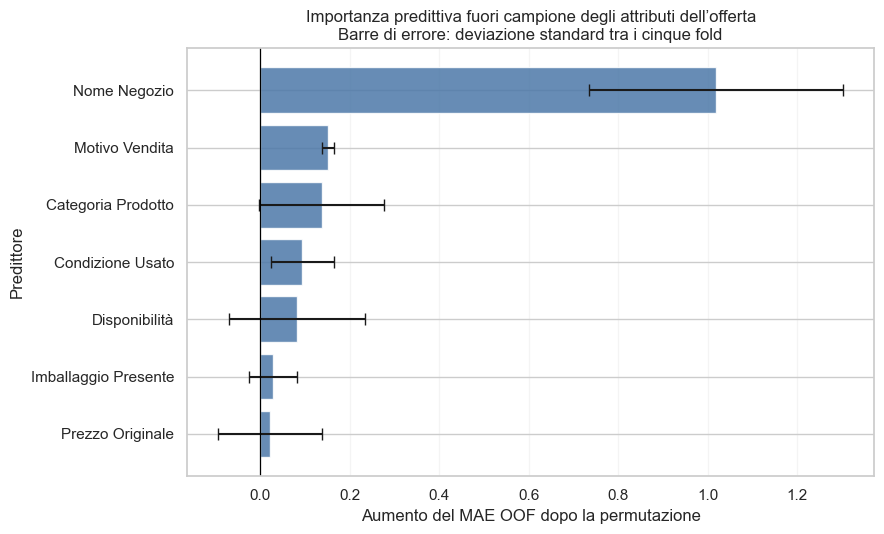

In [85]:
# ---------------------------------------------------------------
# Rappresentazione delle importanze principali

dati_grafico = (sintesi_importanza.sort_values('Aumento medio MAE OOF',ascending=True))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(dati_grafico.index,dati_grafico['Aumento medio MAE OOF'],xerr=dati_grafico['Dev.std tra fold'],color='#4C78A8',alpha=0.85,capsize=4)
ax.axvline(0,color='black',linewidth=0.9)
ax.set_xlabel('Aumento del MAE OOF dopo la permutazione')
ax.set_ylabel('Predittore')
ax.set_title('Importanza predittiva fuori campione degli attributi dell’offerta\nBarre di errore: deviazione standard tra i cinque fold')
ax.grid(axis='x',alpha=0.20)

plt.tight_layout()
plt.show()
# ---------------------------------------------------------------

In [ ]:
# ---------------------------------------------------------------
# Articoli con più prezzi originali
VARIABILE_PREZZO = 'Prezzo Originale'

controllo_prezzo = pd.DataFrame({'Articolo': gruppi.to_numpy(),VARIABILE_PREZZO:X_A[VARIABILE_PREZZO].to_numpy()})
articoli_prezzo_variabile = (controllo_prezzo.groupby('Articolo',observed=True)[VARIABILE_PREZZO].agg(N_pezzi='size',N_prezzi=lambda valori:valori.nunique(dropna=False),Prezzo_minimo='min',Prezzo_massimo='max',
                                                        Prezzi_osservati=lambda valori:tuple(sorted(pd.unique(valori.dropna())))))
articoli_prezzo_variabile = (articoli_prezzo_variabile[articoli_prezzo_variabile['N_prezzi'] > 1].copy())
articoli_prezzo_variabile['Differenza massimo-minimo'] = (articoli_prezzo_variabile['Prezzo_massimo']- articoli_prezzo_variabile['Prezzo_minimo'])

display(HTML('<h4>Articoli con più prezzi originali</h4>'))
display(articoli_prezzo_variabile.sort_values('Differenza massimo-minimo',ascending=False).round(2))
print('Articoli con prezzo variabile:',len(articoli_prezzo_variabile))
# ---------------------------------------------------------------

,N_pezzi,N_prezzi,Prezzo_minimo,Prezzo_massimo,Prezzi_osservati,Differenza massimo-minimo
Articolo,,,,,,
00417621,2,2,300.00,800.00,"(300.0, 800.0)",500.00
20341692,3,2,149.00,209.00,"(149.0, 209.0)",60.00
60473572,16,2,60.00,120.00,"(60.0, 120.0)",60.00
10496203,5,2,10.00,40.00,"(10.0, 40.0)",30.00
70277354,2,2,33.00,55.00,"(33.0, 55.0)",22.00
80535116,2,2,269.00,289.00,"(269.0, 289.0)",20.00
50407097,5,2,59.95,79.95,"(59.95, 79.95)",20.00
40341101,2,2,27.00,45.00,"(27.0, 45.0)",18.00
20535082,2,2,139.00,149.00,"(139.0, 149.0)",10.00


Articoli con prezzo variabile: 24


In [ ]:
# ---------------------------------------------------------------
# Controllo di sensibilità: componente tra articoli di Prezzo Originale
righe_importanza_prezzo_tra = []

for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni,start=1):
    X_verifica = X_A.iloc[idx_verifica]
    y_verifica = y.iloc[idx_verifica]

    gruppi_verifica = gruppi.iloc[idx_verifica]
    pesi_verifica = pesi_articolo.iloc[idx_verifica]

    n_verifica = len(idx_verifica)
    somma_pesi_verifica = pesi_verifica.sum()

    modello_A_blocco = (modelli_A_per_fold[blocco])
    predizioni_originali = (modello_A_blocco.predict(X_verifica))
    mae_originale = mean_absolute_error(y_verifica,predizioni_originali)
    mae_originale_pesato = (mean_absolute_error(y_verifica,predizioni_originali,sample_weight=pesi_verifica))

    for ripetizione in range(1,N_PERMUTAZIONI + 1):
        # Il numero 999 identifica esclusivamente il controllo sulla componente tra articoli.
        sequenza_seme = np.random.SeedSequence([SEME_PERMUTAZIONE,999,blocco,ripetizione])
        generatore = np.random.default_rng(sequenza_seme)
        X_permutato = (permuta_componente_tra_articoli(X_verifica=X_verifica,gruppi_verifica=gruppi_verifica,variabile=VARIABILE_PREZZO,generatore=generatore))
        predizioni_permutate = (modello_A_blocco.predict(X_permutato))
        mae_permutato = mean_absolute_error(y_verifica,predizioni_permutate)
        mae_permutato_pesato = (mean_absolute_error(y_verifica,predizioni_permutate,sample_weight=pesi_verifica))

        righe_importanza_prezzo_tra.append({'Blocco': blocco,'Ripetizione': ripetizione,'N verifica': n_verifica,'Somma pesi verifica': somma_pesi_verifica,'Aumento MAE': mae_permutato - mae_originale,'Aumento MAE ponderato': mae_permutato_pesato - mae_originale_pesato})

importanza_prezzo_tra = pd.DataFrame(righe_importanza_prezzo_tra)
importanza_prezzo_tra_fold = (importanza_prezzo_tra.groupby('Blocco').agg(aumento_mae=('Aumento MAE','mean'),sd_permutazioni=('Aumento MAE','std'),aumento_mae_pesato=('Aumento MAE ponderato','mean'),
                                                                          sd_permutazioni_pesato=('Aumento MAE ponderato','std'), n_verifica=('N verifica','first'), somma_pesi_verifica=('Somma pesi verifica','first')))

display(HTML('<h4>Componente tra articoli del prezzo: risultati per fold</h4>'))
display(importanza_prezzo_tra_fold.round(4))
# ---------------------------------------------------------------

,aumento_mae,sd_permutazioni,aumento_mae_pesato,sd_permutazioni_pesato,n_verifica,somma_pesi_verifica
Blocco,,,,,,
1,0.1825,0.0810,0.1381,0.0645,534,207.0
2,0.1120,0.0743,0.2486,0.0672,510,207.0
3,0.0625,0.1176,-0.0435,0.1105,518,207.0
4,0.1792,0.0919,0.1155,0.0857,439,207.0
5,-0.1541,0.1668,0.0909,0.0967,591,206.0


In [88]:
# ---------------------------------------------------------------
# Struttura e copertura della variabile Nome Negozio

negozio = (X_A['Nome Negozio'].astype('object').fillna('Non specificato'))

profilo_negozi = pd.DataFrame({'Nome Negozio': negozio.to_numpy(), 'Sconto': y.to_numpy()})
profilo_negozi = (profilo_negozi.groupby('Nome Negozio',observed=True)['Sconto'].agg(N_esemplari='size',Sconto_medio='mean',Dev_std_sconto='std').sort_values('N_esemplari',ascending=False))

print(f'Numero di negozi distinti: {len(profilo_negozi):,}')
display(HTML('<h4>Numerosità e sconto per negozio</h4>'))
display(profilo_negozi.head(15).round(2))

righe_copertura_negozi = []

for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni, start=1):
    negozi_stima = set(negozio.iloc[idx_stima])
    negozi_verifica = (negozio.iloc[idx_verifica])
    maschera_sconosciuti = (~negozi_verifica.isin(negozi_stima))

    righe_copertura_negozi.append({'Blocco': blocco, 'N negozi training': len(negozi_stima), 'N negozi verifica': negozi_verifica.nunique(),
                                   'N negozi nuovi': negozi_verifica[maschera_sconosciuti ].nunique(),
                                   'Esemplari di negozi nuovi': maschera_sconosciuti.sum(),        
                                   'Quota esemplari negozi nuovi (%)': 100 * maschera_sconosciuti.mean()})

tabella_copertura_negozi = (pd.DataFrame(righe_copertura_negozi).set_index('Blocco'))

display(HTML('<h4>Copertura dei negozi nei fold esterni</h4>'))
display(tabella_copertura_negozi.round(2))
# ---------------------------------------------------------------

Numero di negozi distinti: 23


,N_esemplari,Sconto_medio,Dev_std_sconto
Nome Negozio,,,
Bari,340,40.24,12.76
Napoli,209,41.45,11.46
Catania,184,33.48,9.70
Milano - Carugate,180,38.09,6.19
Milano - San Giuliano,138,37.17,6.95
Padova,126,39.37,7.84
Rome - Porta di Roma,124,38.84,4.34
Rome - Anagnina,123,40.15,9.08
Milano - Corsico,121,36.59,4.57


,N negozi training,N negozi verifica,N negozi nuovi,Esemplari di negozi nuovi,Quota esemplari negozi nuovi (%)
Blocco,,,,,
1,23,23,0,0,0.0
2,23,23,0,0,0.0
3,23,23,0,0,0.0
4,23,23,0,0,0.0
5,23,23,0,0,0.0


In [89]:
# ---------------------------------------------------------------
# Prestazioni fuori campione per negozio

prestazioni_negozi = (previsioni_oof.copy())
prestazioni_negozi['Nome Negozio'] = (X_A['Nome Negozio'].astype('object').fillna('Non specificato').to_numpy())
prestazioni_negozi['Errore Modello A'] = (prestazioni_negozi['Sconto osservato'] - prestazioni_negozi['Predizione Modello A'])
prestazioni_negozi['Errore Modello B'] = (prestazioni_negozi['Sconto osservato'] - prestazioni_negozi['Predizione Modello B'])
prestazioni_negozi['Errore assoluto Modello A'] = (prestazioni_negozi['Errore Modello A'].abs())
prestazioni_negozi['Errore assoluto Modello B'] = (prestazioni_negozi['Errore Modello B'].abs())

profilo_predittivo_negozi = (prestazioni_negozi.groupby('Nome Negozio',observed=True).agg(N_esemplari=('Sconto osservato','size'), Sconto_osservato=('Sconto osservato', 'mean'),      
                                    Sconto_previsto_A=('Predizione Modello A','mean'), Sconto_previsto_B=('Predizione Modello B','mean'),
                                    MAE_A=('Errore assoluto Modello A','mean'), MAE_B=('Errore assoluto Modello B','mean'),
                                    Errore_medio_A=('Errore Modello A','mean'), Errore_medio_B=('Errore Modello B','mean')))

profilo_predittivo_negozi['Delta MAE A-B'] = (profilo_predittivo_negozi['MAE_A'] - profilo_predittivo_negozi['MAE_B'])
profilo_predittivo_negozi = (profilo_predittivo_negozi.sort_values('Sconto_osservato',ascending=False))

display(HTML('<h4>Sconti osservati e prestazioni fuori campione per negozio</h4>'))
display(profilo_predittivo_negozi.round(3))
# ---------------------------------------------------------------

,N_esemplari,Sconto_osservato,Sconto_previsto_A,Sconto_previsto_B,MAE_A,MAE_B,Errore_medio_A,Errore_medio_B,Delta MAE A-B
Nome Negozio,,,,,,,,,
Pescara,51,49.039,41.197,40.679,11.714,11.496,7.843,8.360,0.218
Parma,16,46.875,40.815,39.797,9.410,9.783,6.060,7.078,-0.373
Villesse,87,45.690,43.976,43.065,5.996,6.270,1.714,2.624,-0.274
Ancona,35,45.257,41.681,40.649,6.638,7.392,3.576,4.608,-0.754
Genova,57,44.368,41.789,40.801,7.456,7.087,2.579,3.567,0.370
Brescia - Roncadelle,45,43.933,40.985,40.010,6.680,6.110,2.948,3.923,0.570
Napoli,209,41.455,39.827,39.392,8.604,7.953,1.628,2.062,0.650
Rimini,90,41.444,39.341,39.265,6.571,6.584,2.103,2.179,-0.013
Rome - Fiumicino,118,41.280,40.706,39.532,9.773,10.931,0.574,1.748,-1.159


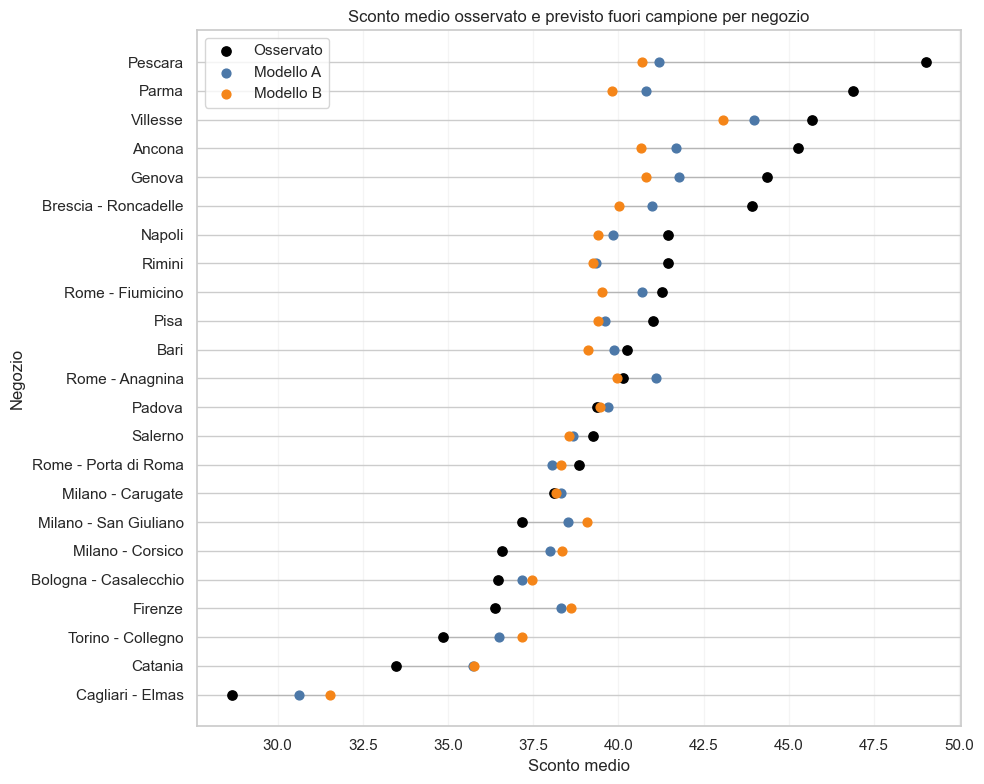

In [90]:
# ---------------------------------------------------------------
# Sconto osservato e previsto per negozio

dati_grafico_negozi = (profilo_predittivo_negozi.sort_values('Sconto_osservato'))
posizioni = np.arange(len(dati_grafico_negozi))

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(dati_grafico_negozi['Sconto_osservato'],posizioni,label='Osservato',color='black',s=45,zorder=3)
ax.scatter(dati_grafico_negozi['Sconto_previsto_A'],posizioni,label='Modello A',color='#4C78A8',s=40,zorder=3)
ax.scatter(dati_grafico_negozi['Sconto_previsto_B'],posizioni,label='Modello B',color='#F58518',s=40,zorder=3)

for posizione, (_, riga) in enumerate(dati_grafico_negozi.iterrows()):
    valori = [riga['Sconto_osservato'],riga['Sconto_previsto_A'],riga['Sconto_previsto_B']]
    ax.plot([min(valori),max(valori)], [posizione,posizione], color='grey', alpha=0.30, linewidth=1)

ax.set_yticks(posizioni)
ax.set_yticklabels(dati_grafico_negozi.index)
ax.set_xlabel('Sconto medio')
ax.set_ylabel('Negozio')
ax.set_title('Sconto medio osservato e previsto ''fuori campione per negozio')
ax.legend()
ax.grid(axis='x', alpha=0.20)

plt.tight_layout()
plt.show()
# ---------------------------------------------------------------

In [91]:
# ---------------------------------------------------------------
# Dispersione e prevedibilità per punto vendita

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import r2_score
from IPython.display import display, HTML


# Soglia utilizzata esclusivamente per la rappresentazione grafica. Le statistiche vengono comunque calcolate per tutti i negozi.
N_MIN_MAPPA = 50
VAR_NEGOZIO = 'Nome Negozio'

# Controlli preliminari

if VAR_NEGOZIO not in X_A.columns:
    raise KeyError(f'La variabile "{VAR_NEGOZIO}" non è presente in X_A.')

if len(X_A) != len(y) or len(y) != len(pred_oof_A):
    raise ValueError('X_A, y e pred_oof_A non hanno la stessa lunghezza.')

if np.isnan(np.asarray(pred_oof_A, dtype=float)).any():
    raise ValueError('Le previsioni OOF del Modello A contengono valori mancanti.')

if not np.isfinite(np.asarray(pred_oof_A, dtype=float)).all():
    raise ValueError('Le previsioni OOF del Modello A contengono valori non finiti.')


# Dataset utilizzato per l'analisi per negozio
dati_mappa_negozi = pd.DataFrame({'Nome Negozio': (X_A[VAR_NEGOZIO].astype('string').fillna('Negozio mancante').to_numpy()),'Sconto osservato': np.asarray(y, dtype=float),'Predizione OOF Modello A': np.asarray(pred_oof_A,dtype=float)})

# Calcola le statistiche descrittive e predittive del negozio
def riassumi_negozio(gruppo):

    osservato = gruppo['Sconto osservato'].to_numpy()
    previsto = gruppo['Predizione OOF Modello A'].to_numpy()
    errore = osservato - previsto

    # R² non è definito se lo sconto è costante nel negozio.
    if len(gruppo) >= 2 and np.var(osservato) > 0:
        r2_negozio = r2_score(osservato, previsto)
    else:
        r2_negozio = np.nan

    return pd.Series({'N esemplari': len(gruppo), 'Sconto medio': np.mean(osservato), 'Sconto mediano': np.median(osservato), 'Dev.std sconto': np.std(osservato, ddof=1), 
                      'MAE OOF Modello A': np.mean(np.abs(errore)), 'RMSE OOF Modello A': np.sqrt(np.mean(errore ** 2)), 'R2 OOF Modello A': r2_negozio, 'Errore medio Modello A': np.mean(errore) })

profilo_negozi_mappa = (dati_mappa_negozi.groupby('Nome Negozio', observed=True, sort=False).apply(riassumi_negozio).sort_values('N esemplari', ascending=False))

# Negozi compresi nella rappresentazione
negozi_mappa = (profilo_negozi_mappa[profilo_negozi_mappa['N esemplari'] >= N_MIN_MAPPA].dropna(subset=['Dev.std sconto', 'R2 OOF Modello A']).copy())

# Negozi non rappresentati, ma non eliminati dall'analisi generale
negozi_esclusi_mappa = (profilo_negozi_mappa[profilo_negozi_mappa['N esemplari'] < N_MIN_MAPPA].copy())

if len(negozi_mappa) < 4:
    raise ValueError('La soglia scelta lascia meno di quattro negozi nella mappa.')

display(HTML('<h4>Statistiche utilizzate nella mappa dei negozi</h4>'))
display(negozi_mappa[['N esemplari','Sconto medio','Dev.std sconto','MAE OOF Modello A','R2 OOF Modello A']].sort_values('R2 OOF Modello A', ascending=False).round(3))

print(f'Negozi complessivi: {len(profilo_negozi_mappa)}')
print(f'Negozi rappresentati nella mappa (N ≥ {N_MIN_MAPPA}): {len(negozi_mappa)}')
print(f'Negozi non rappresentati: {len(negozi_esclusi_mappa)}')

if len(negozi_esclusi_mappa) > 0:
    display(HTML('<h4>Negozi non rappresentati per numerosità ridotta</h4>'))
    display(negozi_esclusi_mappa[['N esemplari', 'Sconto medio', 'Dev.std sconto']].round(3))
# ---------------------------------------------------------------

,N esemplari,Sconto medio,Dev.std sconto,MAE OOF Modello A,R2 OOF Modello A
Nome Negozio,,,,,
Milano - Carugate,180.0,38.094,6.191,3.925,0.223
Bari,340.0,40.238,12.765,8.867,0.182
Salerno,107.0,39.262,6.150,4.071,0.080
Rome - Fiumicino,118.0,41.280,13.493,9.773,0.038
Bologna - Casalecchio,90.0,36.467,5.364,4.042,0.036
Pisa,69.0,41.014,8.362,5.340,0.002
Villesse,87.0,45.690,7.797,5.996,-0.001
Rome - Porta di Roma,124.0,38.839,4.344,2.832,-0.003
Torino - Collegno,92.0,34.848,4.263,3.575,-0.052


Negozi complessivi: 23
Negozi rappresentati nella mappa (N ≥ 50): 20
Negozi non rappresentati: 3


,N esemplari,Sconto medio,Dev.std sconto
Nome Negozio,,,
Brescia - Roncadelle,45.0,43.933,8.701
Ancona,35.0,45.257,8.800
Parma,16.0,46.875,10.984


Mediana della dispersione: 7.819
Mediana del R² per negozio: -0.075


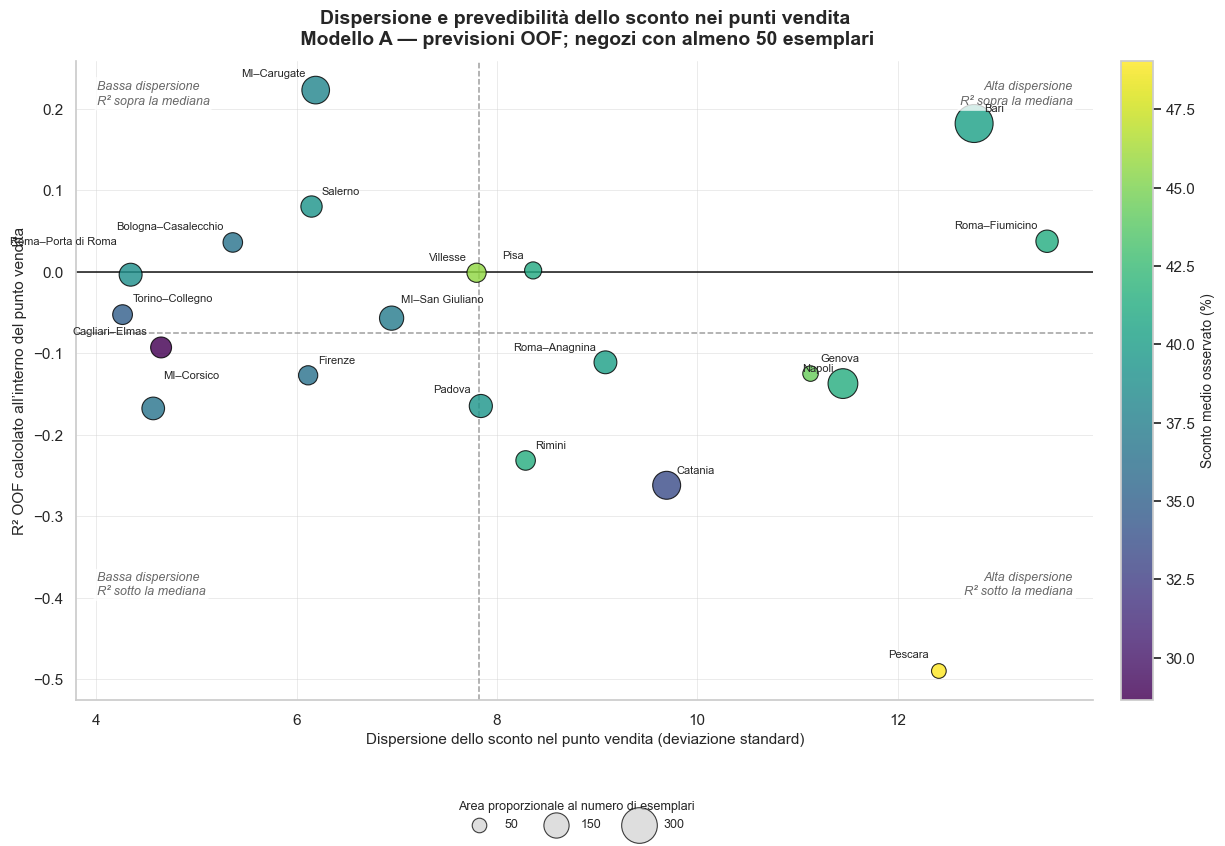

In [92]:
# ---------------------------------------------------------------
# Soglie e aree descrittive della mappa

soglia_dispersione = (negozi_mappa['Dev.std sconto'].median())
soglia_r2 = (negozi_mappa['R2 OOF Modello A'].median())

condizioni_aree = [((negozi_mappa['Dev.std sconto'] <= soglia_dispersione) & (negozi_mappa['R2 OOF Modello A'] >= soglia_r2)),
    ((negozi_mappa['Dev.std sconto'] > soglia_dispersione) & (negozi_mappa['R2 OOF Modello A'] >= soglia_r2)),
    ((negozi_mappa['Dev.std sconto'] <= soglia_dispersione) & (negozi_mappa['R2 OOF Modello A'] < soglia_r2)),
    ((negozi_mappa['Dev.std sconto'] > soglia_dispersione) & (negozi_mappa['R2 OOF Modello A'] < soglia_r2))]

nomi_aree = ['Bassa dispersione — R2 sopra la mediana','Alta dispersione — R2 sopra la mediana','Bassa dispersione — R2 sotto la mediana','Alta dispersione — R2 sotto la mediana']
negozi_mappa['Area descrittiva'] = np.select(condizioni_aree,nomi_aree,default='Non classificato')

print(f'Mediana della dispersione: {soglia_dispersione:.3f}')
print(f'Mediana del R² per negozio: {soglia_r2:.3f}')
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Mappa definitiva: dispersione e prevedibilità per negozio

import matplotlib.pyplot as plt

SCALA_AREA = 2.2

# Abbrevia soltanto le etichette mostrate nel grafico
def abbrevia_nome_negozio(nome):
    return (str(nome).replace('Milano - ', 'MI–').replace('Rome - ', 'Roma–').replace('Bologna - ', 'Bologna–').replace('Brescia - ', 'Brescia–').replace('Cagliari - ', 'Cagliari–').replace('Torino - ', 'Torino–'))

# Spostamenti manuali per evitare le principali sovrapposizioni. I valori sono espressi in punti grafici.
spostamenti_etichette = {'Cagliari - Elmas': (-10, 8),'Rome - Porta di Roma': (-10, 20),'Torino - Collegno': (7, 8),'Milano - Corsico': (7, 20),'Bologna - Casalecchio': (-7, 8),'Milano - Carugate': (-7, 8),'Milano - San Giuliano': (7, 10),'Padova': (-7, 8),'Rome - Fiumicino': (-7, 8),'Pescara': (-7, 8)}

fig, ax = plt.subplots(figsize=(13.5, 9))

# In Matplotlib s rappresenta l'area del punto. L'area è quindi direttamente proporzionale a N.
grafico = ax.scatter(negozi_mappa['Dev.std sconto'],negozi_mappa['R2 OOF Modello A'],s=SCALA_AREA * negozi_mappa['N esemplari'],c=negozi_mappa['Sconto medio'],cmap='viridis',alpha=0.82,edgecolor='black',linewidth=0.8,zorder=3)

# Linee di riferimento
# Mediane dei negozi visualizzati: funzione descrittiva
ax.axvline(soglia_dispersione,color='grey',linestyle='--',linewidth=1.1,alpha=0.75,zorder=1)
ax.axhline(soglia_r2,color='grey',linestyle='--',linewidth=1.1,alpha=0.75,zorder=1)

# Soglia predittiva sostantiva
ax.axhline(0,color='black',linestyle='-',linewidth=1.2,alpha=0.85,zorder=2)

# Etichette dei negozi
for posizione, (negozio, riga) in enumerate(negozi_mappa.iterrows()):
    if negozio in spostamenti_etichette:
        dx, dy = spostamenti_etichette[negozio]
    else:
        dx = 7 if posizione % 2 == 0 else -7
        dy = 7

    allineamento = 'left' if dx >= 0 else 'right'

    ax.annotate(abbrevia_nome_negozio(negozio),xy=(riga['Dev.std sconto'],riga['R2 OOF Modello A']),xytext=(dx, dy),textcoords='offset points',fontsize=8,ha=allineamento,va='bottom',zorder=4)

# Barra cromatica
barra_colore = fig.colorbar(grafico,ax=ax,pad=0.025,fraction=0.045)
barra_colore.set_label('Sconto medio osservato (%)',fontsize=10)

# Legenda della numerosità sotto il grafico
valori_legenda = [valore for valore in [50, 150, 300] if valore <= profilo_negozi_mappa['N esemplari'].max()]
maniglie_dimensione = [ax.scatter([],[],s=SCALA_AREA * valore,facecolor='lightgrey',edgecolor='black',linewidth=0.8,alpha=0.75,label=f'{valore}') for valore in valori_legenda]

fig.legend(handles=maniglie_dimensione,title='Area proporzionale al numero di esemplari',loc='lower center',bbox_to_anchor=(0.45, 0.012),ncol=len(valori_legenda),frameon=False,fontsize=9,title_fontsize=9,handletextpad=1.0,columnspacing=2.0)

# Indicazioni delle quattro aree
stile_area = {'fontsize': 9,'color': 'dimgray','fontstyle': 'italic','bbox': {'boxstyle': 'round,pad=0.25','facecolor': 'white','edgecolor': 'none','alpha': 0.78}}
ax.text(0.02,0.97,'Bassa dispersione\nR² sopra la mediana',transform=ax.transAxes,ha='left',va='top',**stile_area)
ax.text(0.98,0.97,'Alta dispersione\nR² sopra la mediana',transform=ax.transAxes,ha='right',va='top',**stile_area)

# Le indicazioni inferiori vengono alzate per non sovrapporsi ai punti di Pescara e Catania.
ax.text(0.02,0.16,'Bassa dispersione\nR² sotto la mediana',transform=ax.transAxes,ha='left',va='bottom',**stile_area)
ax.text(0.98,0.16,'Alta dispersione\nR² sotto la mediana',transform=ax.transAxes,ha='right',va='bottom',**stile_area)

# Titoli e formattazione
ax.set_title(f'Dispersione e prevedibilità dello sconto nei punti vendita\n Modello A — previsioni OOF; negozi con almeno {N_MIN_MAPPA} esemplari',fontsize=14,fontweight='bold',pad=12)
ax.set_xlabel('Dispersione dello sconto nel punto vendita (deviazione standard)',fontsize=11)
ax.set_ylabel('R² OOF calcolato all’interno del punto vendita',fontsize=11)
ax.grid(True,color='lightgrey',linestyle='-',linewidth=0.7,alpha=0.45,zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Spazio aggiuntivo sotto la figura per la legenda
fig.subplots_adjust(left=0.08,right=0.89,top=0.88,bottom=0.17)

plt.show()
# ---------------------------------------------------------------

In [93]:
# ---------------------------------------------------------------
# Sintesi delle quattro aree descrittive

ordine_aree = ['Bassa dispersione — R2 sopra la mediana','Alta dispersione — R2 sopra la mediana','Bassa dispersione — R2 sotto la mediana','Alta dispersione — R2 sotto la mediana']

negozi_mappa['Area descrittiva'] = pd.Categorical(negozi_mappa['Area descrittiva'],categories=ordine_aree,ordered=True)

sintesi_aree = (negozi_mappa.groupby('Area descrittiva', observed=True).agg(N_negozi=('N esemplari', 'size'),N_esemplari=('N esemplari', 'sum'),
                                                                             Dispersione_media=('Dev.std sconto', 'mean'), R2_medio=('R2 OOF Modello A', 'mean'),
                                                                             MAE_medio=('MAE OOF Modello A', 'mean'), Sconto_medio=('Sconto medio', 'mean')))

negozi_per_area = (negozi_mappa.groupby('Area descrittiva', observed=True).apply(lambda gruppo: ', '.join(sorted(gruppo.index.astype(str)))))

sintesi_aree['Negozi'] = negozi_per_area

display(HTML('<h4>Sintesi descrittiva delle aree della mappa</h4>'))
display(sintesi_aree.round(3))
# ---------------------------------------------------------------

# ---------------------------------------------------------------
# Controlli e indicazioni utili per il commento

r2_piu_alti = (negozi_mappa.nlargest(3, 'R2 OOF Modello A'))
r2_piu_bassi = (negozi_mappa.nsmallest(3, 'R2 OOF Modello A'))
dispersione_piu_alta = (negozi_mappa.nlargest(3, 'Dev.std sconto'))
r2_negativi = negozi_mappa[negozi_mappa['R2 OOF Modello A'] < 0]

print('R² più elevato: '+ ', '.join(r2_piu_alti.index.astype(str)))
print('R² più basso: '+ ', '.join(r2_piu_bassi.index.astype(str)))
print('Maggiore dispersione dello sconto: '+ ', '.join(dispersione_piu_alta.index.astype(str)))
print(f'Negozi con R² negativo: {len(r2_negativi)}')

if len(r2_negativi) > 0:
    print(', '.join(r2_negativi.index.astype(str)))
# ---------------------------------------------------------------

,N_negozi,N_esemplari,Dispersione_media,R2_medio,MAE_medio,Sconto_medio,Negozi
Area descrittiva,,,,,,,
Bassa dispersione — R2 sopra la mediana,7,818.0,5.865,0.032,4.326,38.625,"Bologna - Casalecchio, Milano - Carugate, Mila..."
Alta dispersione — R2 sopra la mediana,3,527.0,11.540,0.074,7.993,40.844,"Bari, Pisa, Rome - Fiumicino"
Bassa dispersione — R2 sotto la mediana,3,311.0,5.111,-0.129,3.611,33.876,"Cagliari - Elmas, Firenze, Milano - Corsico"
Alta dispersione — R2 sotto la mediana,7,840.0,9.987,-0.217,7.951,41.328,"Catania, Genova, Napoli, Padova, Pescara, Rimi..."


R² più elevato: Milano - Carugate, Bari, Salerno
R² più basso: Pescara, Catania, Rimini
Maggiore dispersione dello sconto: Rome - Fiumicino, Bari, Pescara
Negozi con R² negativo: 14
Napoli, Catania, Milano - San Giuliano, Padova, Rome - Porta di Roma, Rome - Anagnina, Milano - Corsico, Cagliari - Elmas, Torino - Collegno, Rimini, Villesse, Firenze, Genova, Pescara


In [ ]:
## Analisi dell'esclusione di Nome Negozio

# ---------------------------------------------------------------
# Pipeline prive di Nome Negozio

if 'Nome Negozio' not in CAT_A:
    raise ValueError('Nome Negozio non è presente tra i predittori categoriali del Modello A.')

CAT_A_SENZA_NEGOZIO = [variabile for variabile in CAT_A if variabile != 'Nome Negozio']
X_A_SENZA_NEGOZIO = (X_A.drop(columns=['Nome Negozio']))
X_B_SENZA_NEGOZIO = (X_B.drop(columns=['Nome Negozio']))

# Costruisce il pre-processing usando tutti i predittori previsti, tranne Nome Negozio.
def crea_preprocessore_senza_negozio(includi_reputazione=False, indicatori_reputazione=True):
    trasformazioni = [('numeriche_offerta','passthrough',NUM_A),('categoriali_offerta', Pipeline([('imputazione', SimpleImputer(strategy='constant',fill_value='Non specificato')), 
                                                                ('codifica', OneHotEncoder(handle_unknown='ignore',sparse_output=True))]), CAT_A_SENZA_NEGOZIO)]

    if includi_reputazione:
        trasformazioni.append(('reputazione', SimpleImputer(strategy='median', add_indicator= indicatori_reputazione),REP))

    return ColumnTransformer(transformers=trasformazioni,remainder='drop',verbose_feature_names_out=False)

# Costruisce A o B escludendo Nome Negozio.
def crea_modello_senza_negozio(includi_reputazione=False,indicatori_reputazione=True,random_state=42,n_estimators=N_ALBERI_RICERCA):
    foresta = RandomForestRegressor(n_estimators=n_estimators, criterion='squared_error', bootstrap=True, random_state=random_state, n_jobs=1)

    return Pipeline([('preprocessing', crea_preprocessore_senza_negozio(includi_reputazione= includi_reputazione, indicatori_reputazione= indicatori_reputazione)),('random_forest', foresta)])

modello_A_senza_base = (crea_modello_senza_negozio(includi_reputazione=False,n_estimators=N_ALBERI_RICERCA))
modello_B_senza_base = (crea_modello_senza_negozio(includi_reputazione=True,n_estimators=N_ALBERI_RICERCA))

print(f'Predittori categoriali mantenuti: {CAT_A_SENZA_NEGOZIO}')
print('Pipeline senza negozio costruite correttamente.')
# ---------------------------------------------------------------

Predittori categoriali mantenuti: ['Categoria Prodotto', 'Condizione Usato', 'Motivo Vendita', 'Imballaggio Presente']
Pipeline senza negozio costruite correttamente.


In [95]:
# ---------------------------------------------------------------
# Validazione annidata senza Nome Negozio

pred_oof_A_senza_negozio = np.full(len(y),np.nan)
pred_oof_B_senza_negozio = np.full(len(y),np.nan)

risultati_blocchi_senza_negozio = []
selezioni_senza_negozio = []
migliori_parametri_senza_negozio = {}

specifiche_senza_negozio = [('Modello A senza negozio',X_A_SENZA_NEGOZIO,modello_A_senza_base,False,pred_oof_A_senza_negozio),('Modello B senza negozio',X_B_SENZA_NEGOZIO,modello_B_senza_base,True,pred_oof_B_senza_negozio)]

inizio_sensibilita = perf_counter()

for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni,start=1):
    y_stima = y.iloc[idx_stima]
    y_verifica = y.iloc[idx_verifica]
    gruppi_stima = gruppi.iloc[idx_stima]

    seme_blocco = (SEME_PARTIZIONE + blocco)

    for (nome_modello,X_completo,modello_base,includi_reputazione,vettore_oof) in specifiche_senza_negozio:

        print(f'Blocco {blocco}/{N_BLOCCHI_ESTERNI} — {nome_modello}: ricerca interna...',flush=True)

        X_stima = X_completo.iloc[idx_stima]
        X_verifica = X_completo.iloc[idx_verifica]
        modello_ricerca = clone(modello_base).set_params(random_forest__random_state=seme_blocco)
        ricerca = crea_ricerca_interna(modello_base=modello_ricerca,random_state=seme_blocco)
        ricerca.fit(X_stima,y_stima,groups=gruppi_stima)

        parametri_migliori = (ricerca.best_params_.copy())
        migliori_parametri_senza_negozio[(nome_modello, blocco)] = parametri_migliori
        parametri_brevi = {nome.replace('random_forest__',''): valore for nome, valore in parametri_migliori.items()}

        selezioni_senza_negozio.append({'Blocco': blocco, 'Modello': nome_modello, 'MAE interno': -ricerca.best_score_,
            'Dev.std MAE interno': ricerca.cv_results_['std_test_score' ][ricerca.best_index_], **parametri_brevi})

        fit_finale = (crea_modello_senza_negozio( includi_reputazione=includi_reputazione, indicatori_reputazione=True, random_state=seme_blocco, n_estimators=N_ALBERI_FINALE))
        fit_finale.set_params(**parametri_migliori)
        fit_finale.set_params(random_forest__n_jobs=-1)
        fit_finale.fit(X_stima, y_stima)
        predizioni = fit_finale.predict(X_verifica)
        vettore_oof[idx_verifica] = predizioni

        risultati_blocchi_senza_negozio.append({'Blocco': blocco, 'Modello': nome_modello,'N verifica': len(idx_verifica), **calcola_metriche(y_verifica,predizioni)})

    print(f'Blocco {blocco}/ {N_BLOCCHI_ESTERNI} completato.\n', flush=True)

for nome_modello, predizioni in {'Modello A senza negozio': pred_oof_A_senza_negozio, 'Modello B senza negozio': pred_oof_B_senza_negozio}.items():
    if not np.isfinite(predizioni).all():
        raise ValueError(f'Previsioni non valide per {nome_modello}.')

risultati_cv_senza_negozio = pd.DataFrame(risultati_blocchi_senza_negozio)
selezioni_cv_senza_negozio = pd.DataFrame(selezioni_senza_negozio)

durata_sensibilita = (perf_counter() - inizio_sensibilita) / 60
print('Validazione senza negozio completata.')
print(f'Tempo totale: {durata_sensibilita:.1f} minuti.')
# ---------------------------------------------------------------

Blocco 1/5 — Modello A senza negozio: ricerca interna...
Blocco 1/5 — Modello B senza negozio: ricerca interna...
Blocco 1/ 5 completato.

Blocco 2/5 — Modello A senza negozio: ricerca interna...
Blocco 2/5 — Modello B senza negozio: ricerca interna...
Blocco 2/ 5 completato.

Blocco 3/5 — Modello A senza negozio: ricerca interna...
Blocco 3/5 — Modello B senza negozio: ricerca interna...
Blocco 3/ 5 completato.

Blocco 4/5 — Modello A senza negozio: ricerca interna...
Blocco 4/5 — Modello B senza negozio: ricerca interna...
Blocco 4/ 5 completato.

Blocco 5/5 — Modello A senza negozio: ricerca interna...
Blocco 5/5 — Modello B senza negozio: ricerca interna...
Blocco 5/ 5 completato.

Validazione senza negozio completata.
Tempo totale: 34.4 minuti.


In [96]:
# ---------------------------------------------------------------
# Confronto delle specificazioni complessivo

predizioni_confronto = {'Baseline': pred_oof_baseline, 'Modello A completo': pred_oof_A, 'Modello B completo': pred_oof_B,
                        'Modello A senza negozio': pred_oof_A_senza_negozio, 'Modello B senza negozio': pred_oof_B_senza_negozio}

metriche_confronto = pd.DataFrame({nome_modello: calcola_metriche( y, predizioni) for nome_modello, predizioni in predizioni_confronto.items()}).T
metriche_confronto['Riduzione MAE vs baseline (%)'] = (1 - metriche_confronto['MAE'] / metriche_confronto.loc['Baseline', 'MAE']) * 100
metriche_confronto['Riduzione RMSE vs baseline (%)'] = (1 - metriche_confronto['RMSE'] / metriche_confronto.loc['Baseline', 'RMSE']) * 100

display(HTML('<h4>Prestazioni complessive con e senza Nome Negozio</h4>'))
display(metriche_confronto.round(3))
# ---------------------------------------------------------------

,MAE,RMSE,R2,Riduzione MAE vs baseline (%),Riduzione RMSE vs baseline (%)
Baseline,6.848,9.796,-0.005,0.000,0.000
Modello A completo,6.318,9.147,0.124,7.740,6.632
Modello B completo,6.219,8.985,0.155,9.190,8.284
Modello A senza negozio,6.857,9.681,0.018,-0.126,1.172
Modello B senza negozio,6.762,9.573,0.040,1.264,2.284


In [97]:
# ---------------------------------------------------------------
# Confronto ponderato per articolo

numerosita_articoli_sensibilita = (gruppi.value_counts())
pesi_sensibilita = (1 / gruppi.map(numerosita_articoli_sensibilita))
metriche_confronto_pesate = pd.DataFrame({nome_modello: calcola_metriche_pesate(y_vero=y,y_predetto=predizioni,pesi=pesi_sensibilita) for nome_modello, predizioni in predizioni_confronto.items()}).T
metriche_confronto_pesate[ 'Riduzione MAE vs baseline (%)'] = (1 - metriche_confronto_pesate['MAE'] / metriche_confronto_pesate.loc['Baseline', 'MAE']) * 100
metriche_confronto_pesate[ 'Riduzione RMSE vs baseline (%)'] = (1 - metriche_confronto_pesate['RMSE'] / metriche_confronto_pesate.loc['Baseline', 'RMSE']) * 100

display(HTML('<h4>Prestazioni ponderate con e senza Nome Negozio</h4>'))
display(metriche_confronto_pesate.round(3))
# ---------------------------------------------------------------

,MAE,RMSE,R2,Riduzione MAE vs baseline (%),Riduzione RMSE vs baseline (%)
Baseline,6.207,9.016,-0.009,0.000,0.000
Modello A completo,5.572,8.219,0.162,10.230,8.839
Modello B completo,5.524,8.142,0.177,10.994,9.695
Modello A senza negozio,6.156,8.826,0.033,0.823,2.106
Modello B senza negozio,6.087,8.748,0.050,1.922,2.978


In [98]:
# ---------------------------------------------------------------
# Contributo del negozio e della reputazione

def calcola_delta_reputazione(tabella,nome_A,nome_B):
    return {'Delta MAE': tabella.loc[nome_A, 'MAE'] - tabella.loc[nome_B, 'MAE'], 'Delta RMSE': tabella.loc[nome_A, 'RMSE'] - tabella.loc[nome_B, 'RMSE'], 'Delta R2': tabella.loc[nome_B, 'R2'] - tabella.loc[nome_A, 'R2']}

# Valori positivi indicano un peggioramento dovuto all'esclusione del negozio
def calcola_perdita_esclusione(tabella,nome_completo,nome_senza):

    return {'Perdita MAE': tabella.loc[nome_senza, 'MAE'] - tabella.loc[nome_completo, 'MAE'],
            'Perdita RMSE': tabella.loc[nome_senza, 'RMSE'] - tabella.loc[nome_completo, 'RMSE'],
            'Perdita R2': tabella.loc[nome_completo, 'R2'] - tabella.loc[nome_senza, 'R2']}

delta_reputazione_sensibilita = pd.DataFrame({'Modelli completi': calcola_delta_reputazione(metriche_confronto,'Modello A completo','Modello B completo'),
                                              'Modelli senza negozio':calcola_delta_reputazione(metriche_confronto,'Modello A senza negozio','Modello B senza negozio'),
                                              'Completi — ponderato':calcola_delta_reputazione(metriche_confronto_pesate,'Modello A completo','Modello B completo'),
                                              'Senza negozio — ponderato':calcola_delta_reputazione(metriche_confronto_pesate,'Modello A senza negozio','Modello B senza negozio')}).T

display(HTML('<h4>Contributo della reputazione con e senza negozio</h4>'))
display(delta_reputazione_sensibilita.round(4))

perdita_esclusione_negozio = pd.DataFrame({'Modello A': calcola_perdita_esclusione(metriche_confronto,'Modello A completo','Modello A senza negozio'),
                                           'Modello B': calcola_perdita_esclusione(metriche_confronto,'Modello B completo','Modello B senza negozio'),
                                           'Modello A — ponderato': calcola_perdita_esclusione(metriche_confronto_pesate,'Modello A completo','Modello A senza negozio'),
                                           'Modello B — ponderato': calcola_perdita_esclusione(metriche_confronto_pesate,'Modello B completo','Modello B senza negozio')}).T

display(HTML('<h4>Perdita predittiva dovuta all’esclusione del negozio</h4>'))
display(perdita_esclusione_negozio.round(4))
# ---------------------------------------------------------------

,Delta MAE,Delta RMSE,Delta R2
Modelli completi,0.0993,0.1619,0.0307
Modelli senza negozio,0.0952,0.1089,0.0220
Completi — ponderato,0.0474,0.0772,0.0157
Senza negozio — ponderato,0.0682,0.0786,0.0172


,Perdita MAE,Perdita RMSE,Perdita R2
Modello A,0.5387,0.5349,0.1055
Modello B,0.5428,0.5878,0.1142
Modello A — ponderato,0.5838,0.6070,0.1284
Modello B — ponderato,0.5631,0.6056,0.1269


In [99]:
# ---------------------------------------------------------------
# Riepilogo della stabilità tra i fold

A_completo_fold = (risultati_cv[risultati_cv['Modello']== 'Modello A'].set_index('Blocco').sort_index())
B_completo_fold = (risultati_cv[risultati_cv['Modello']== 'Modello B'].set_index('Blocco').sort_index())
A_senza_fold = (risultati_cv_senza_negozio[risultati_cv_senza_negozio['Modello']== 'Modello A senza negozio'].set_index('Blocco').sort_index())
B_senza_fold = (risultati_cv_senza_negozio[risultati_cv_senza_negozio['Modello']== 'Modello B senza negozio'].set_index('Blocco').sort_index())

perdita_negozio_fold = pd.DataFrame({'Perdita MAE A': A_senza_fold['MAE'] - A_completo_fold['MAE'],
                                      'Perdita RMSE A': A_senza_fold['RMSE'] - A_completo_fold['RMSE'],
                                      'Perdita R2 A': A_completo_fold['R2'] - A_senza_fold['R2'],
                                      'Perdita MAE B': B_senza_fold['MAE'] - B_completo_fold['MAE'],
                                      'Perdita RMSE B': B_senza_fold['RMSE'] - B_completo_fold['RMSE'],
                                      'Perdita R2 B': B_completo_fold['R2'] - B_senza_fold['R2']})

delta_reputazione_senza_fold = pd.DataFrame({ 'Delta MAE': A_senza_fold['MAE'] - B_senza_fold['MAE'], 'Delta RMSE': A_senza_fold['RMSE'] - B_senza_fold['RMSE'], 'Delta R2': B_senza_fold['R2'] - A_senza_fold['R2']})

riepilogo_stabilita_senza_negozio = pd.DataFrame({'Controllo': ['Peggioramento di A senza negozio','Peggioramento di B senza negozio','Miglioramento di B su A senza negozio'],
                                    'Fold coerenti — MAE': [(perdita_negozio_fold['Perdita MAE A'] > 0).sum(), (perdita_negozio_fold['Perdita MAE B'] > 0).sum(), (delta_reputazione_senza_fold['Delta MAE'] > 0).sum()],
                                    'Fold coerenti — RMSE': [(perdita_negozio_fold['Perdita RMSE A'] > 0).sum(), (perdita_negozio_fold['Perdita RMSE B'] > 0).sum(), (delta_reputazione_senza_fold['Delta RMSE'] > 0).sum()],
                                    'Fold coerenti — R2': [(perdita_negozio_fold['Perdita R2 A'] > 0).sum(),(perdita_negozio_fold['Perdita R2 B'] > 0).sum(), (delta_reputazione_senza_fold['Delta R2'] > 0).sum()]})

riepilogo_stabilita_senza_negozio = (riepilogo_stabilita_senza_negozio.set_index('Controllo'))
display(HTML('<h4>Coerenza della sensibilità nei cinque fold</h4>'))
display(riepilogo_stabilita_senza_negozio)
# ---------------------------------------------------------------

,Fold coerenti — MAE,Fold coerenti — RMSE,Fold coerenti — R2
Controllo,,,
Peggioramento di A senza negozio,4,4,4
Peggioramento di B senza negozio,5,5,5
Miglioramento di B su A senza negozio,3,4,4


In [ ]:
## Sensibilità al trattamento delle dimensioni reputazionali

# ---------------------------------------------------------------
# Varianti del Modello B

if 'Montaggio' not in REP:
    raise ValueError('Montaggio non è presente nella lista REP.')

REP_SENZA_MONTAGGIO = [variabile for variabile in REP if variabile != 'Montaggio']

# Costruisce il pre-processing di una variante di B
def crea_preprocessore_sensibilita_rep(variabili_reputazionali, indicatori_reputazione):
    trasformazioni = [('numeriche_offerta','passthrough',NUM_A), ('categoriali_offerta', 
                        Pipeline([('imputazione',SimpleImputer(strategy='constant', fill_value='Non specificato')), ('codifica', OneHotEncoder(handle_unknown='ignore', sparse_output=True))]), CAT_A), ('reputazione', SimpleImputer(strategy='median',add_indicator=indicatori_reputazione), variabili_reputazionali)]

    return ColumnTransformer(transformers=trasformazioni,remainder='drop',verbose_feature_names_out=False)

def crea_modello_sensibilita_rep(variabili_reputazionali,indicatori_reputazione,random_state=42,n_estimators=N_ALBERI_RICERCA):
    foresta = RandomForestRegressor(n_estimators=n_estimators,criterion='squared_error',bootstrap=True,random_state=random_state,n_jobs=1)

    return Pipeline([('preprocessing',crea_preprocessore_sensibilita_rep(variabili_reputazionali=variabili_reputazionali,indicatori_reputazione=indicatori_reputazione)),('random_forest',foresta)])

specifiche_sensibilita_rep = {'Modello B senza Montaggio': {'variabili_reputazionali': REP_SENZA_MONTAGGIO,'indicatori_reputazione': True}, 'Modello B senza indicatori': {'variabili_reputazionali': REP,'indicatori_reputazione': False}}
modelli_base_sensibilita_rep = {nome_modello: crea_modello_sensibilita_rep(variabili_reputazionali=specifica['variabili_reputazionali'], indicatori_reputazione=specifica['indicatori_reputazione'], n_estimators=N_ALBERI_RICERCA) for nome_modello, specifica in specifiche_sensibilita_rep.items()}

print(F'Dimensioni mantenute senza Montaggio: {REP_SENZA_MONTAGGIO}')
print('Varianti reputazionali costruite correttamente.')
# ---------------------------------------------------------------

Dimensioni mantenute senza Montaggio: ['Voto Generale', 'Qualità/Prezzo', 'Estetica']
Varianti reputazionali costruite correttamente.


In [101]:
# ---------------------------------------------------------------
# Validazione delle varianti reputazionali

predizioni_sensibilita_rep = {nome_modello: np.full(len(y), np.nan) for nome_modello in specifiche_sensibilita_rep}
risultati_blocchi_sensibilita_rep = []
selezioni_sensibilita_rep = []
migliori_parametri_sensibilita_rep = {}

inizio_sensibilita_rep = perf_counter()

for blocco, (idx_stima, idx_verifica) in enumerate(splits_esterni,start=1):
    X_stima = X_B.iloc[idx_stima]
    X_verifica = X_B.iloc[idx_verifica]
    y_stima = y.iloc[idx_stima]
    y_verifica = y.iloc[idx_verifica]

    gruppi_stima = gruppi.iloc[idx_stima]
    seme_blocco = (SEME_PARTIZIONE + blocco)

    for nome_modello, specifica in (specifiche_sensibilita_rep.items()):
        print(f'Blocco {blocco}/{N_BLOCCHI_ESTERNI} — {nome_modello}: ricerca interna...',flush=True)

        modello_ricerca = clone(modelli_base_sensibilita_rep[nome_modello]).set_params(random_forest__random_state=seme_blocco)
        ricerca = crea_ricerca_interna(modello_base=modello_ricerca, random_state=seme_blocco)
        ricerca.fit(X_stima, y_stima, groups=gruppi_stima)

        parametri_migliori = (ricerca.best_params_.copy())
        migliori_parametri_sensibilita_rep[(nome_modello, blocco)] = parametri_migliori

        selezioni_sensibilita_rep.append({'Blocco': blocco, 'Modello': nome_modello, 'MAE interno': -ricerca.best_score_,**{nome.replace('random_forest__',''): valore for nome, valore in parametri_migliori.items()}})

        fit_finale = (crea_modello_sensibilita_rep(variabili_reputazionali=specifica['variabili_reputazionali'],indicatori_reputazione=specifica['indicatori_reputazione'],random_state=seme_blocco,n_estimators=N_ALBERI_FINALE))
        fit_finale.set_params(**parametri_migliori)
        fit_finale.set_params(random_forest__n_jobs=-1)
        fit_finale.fit(X_stima,y_stima)

        predizioni = fit_finale.predict(X_verifica)
        predizioni_sensibilita_rep[nome_modello][idx_verifica] = predizioni

        risultati_blocchi_sensibilita_rep.append({'Blocco': blocco, 'Modello': nome_modello,**calcola_metriche(y_verifica,predizioni)})

    print(f'Blocco {blocco}/{N_BLOCCHI_ESTERNI} completato.\n', flush=True)

for nome_modello, predizioni in (predizioni_sensibilita_rep.items()):
    if not np.isfinite(predizioni).all():
        raise ValueError(f'Previsioni non valide per {nome_modello}.')

risultati_cv_sensibilita_rep = pd.DataFrame(risultati_blocchi_sensibilita_rep)
selezioni_cv_sensibilita_rep = pd.DataFrame(selezioni_sensibilita_rep)

durata_sensibilita_rep = (perf_counter() - inizio_sensibilita_rep) / 60
print('Sensibilità reputazionale completata.')
print(f'Tempo totale: {durata_sensibilita_rep:.1f} minuti.')
# ---------------------------------------------------------------

Blocco 1/5 — Modello B senza Montaggio: ricerca interna...


Blocco 1/5 — Modello B senza indicatori: ricerca interna...
Blocco 1/5 completato.

Blocco 2/5 — Modello B senza Montaggio: ricerca interna...
Blocco 2/5 — Modello B senza indicatori: ricerca interna...
Blocco 2/5 completato.

Blocco 3/5 — Modello B senza Montaggio: ricerca interna...
Blocco 3/5 — Modello B senza indicatori: ricerca interna...
Blocco 3/5 completato.

Blocco 4/5 — Modello B senza Montaggio: ricerca interna...
Blocco 4/5 — Modello B senza indicatori: ricerca interna...
Blocco 4/5 completato.

Blocco 5/5 — Modello B senza Montaggio: ricerca interna...
Blocco 5/5 — Modello B senza indicatori: ricerca interna...
Blocco 5/5 completato.

Sensibilità reputazionale completata.
Tempo totale: 43.5 minuti.


In [102]:
# ---------------------------------------------------------------
# Risultati delle sensibilità reputazionali

predizioni_varianti_rep = {'Baseline': pred_oof_baseline, 'Modello A': pred_oof_A, 'Modello B principale': pred_oof_B, **predizioni_sensibilita_rep}

metriche_varianti_rep = pd.DataFrame({nome_modello: calcola_metriche(y,predizioni) for nome_modello, predizioni in predizioni_varianti_rep.items()}).T

numerosita_rep = (gruppi.value_counts())

pesi_rep = (1 / gruppi.map(numerosita_rep))

metriche_varianti_rep_pesate = pd.DataFrame({nome_modello: calcola_metriche_pesate(y_vero=y,y_predetto=predizioni,pesi=pesi_rep) for nome_modello, predizioni in predizioni_varianti_rep.items()}).T

display(HTML('<h4>Prestazioni delle varianti reputazionali</h4>'))
display(metriche_varianti_rep.round(3))

display(HTML('<h4>Prestazioni ponderate delle varianti reputazionali</h4>'))
display(metriche_varianti_rep_pesate.round(3))
# ---------------------------------------------------------------

,MAE,RMSE,R2
Baseline,6.848,9.796,-0.005
Modello A,6.318,9.147,0.124
Modello B principale,6.219,8.985,0.155
Modello B senza Montaggio,6.251,9.050,0.142
Modello B senza indicatori,6.247,9.031,0.146


,MAE,RMSE,R2
Baseline,6.207,9.016,-0.009
Modello A,5.572,8.219,0.162
Modello B principale,5.524,8.142,0.177
Modello B senza Montaggio,5.533,8.185,0.169
Modello B senza indicatori,5.525,8.175,0.171


In [103]:
# ---------------------------------------------------------------
# Contributo delle varianti rispetto ad A

nomi_varianti_B = ['Modello B principale','Modello B senza Montaggio','Modello B senza indicatori']

righe_confronto_varianti = []

for nome_B in nomi_varianti_B:
    metriche_B = metriche_varianti_rep.loc[nome_B]
    metriche_B_pesate = (metriche_varianti_rep_pesate.loc[nome_B])
    metriche_A = metriche_varianti_rep.loc['Modello A']
    metriche_A_pesate = (metriche_varianti_rep_pesate.loc['Modello A'])

    if nome_B == 'Modello B principale':
        B_fold = (risultati_cv[risultati_cv['Modello'] == 'Modello B'].set_index('Blocco').sort_index())

    else:
        B_fold = (risultati_cv_sensibilita_rep[risultati_cv_sensibilita_rep['Modello'] == nome_B].set_index('Blocco').sort_index())

    A_fold = (risultati_cv[risultati_cv['Modello'] == 'Modello A'].set_index('Blocco').sort_index())

    righe_confronto_varianti.append({'Specifica': nome_B, 'Delta MAE': metriche_A['MAE'] - metriche_B['MAE'], 'Delta RMSE': metriche_A['RMSE'] - metriche_B['RMSE'], 'Delta R2': metriche_B['R2'] - metriche_A['R2'],
                'Delta MAE ponderato': metriche_A_pesate['MAE'] - metriche_B_pesate['MAE'], 'Delta RMSE ponderato': metriche_A_pesate['RMSE'] - metriche_B_pesate['RMSE'], 'Delta R2 ponderato': metriche_B_pesate['R2'] - metriche_A_pesate['R2'],
                'Fold con MAE migliore': (A_fold['MAE'] - B_fold['MAE'] > 0).sum(), 'Fold con RMSE migliore': (A_fold['RMSE'] - B_fold['RMSE'] > 0).sum(), 'Fold con R2 migliore': (B_fold['R2'] - A_fold['R2'] > 0).sum()})

confronto_varianti_rep = (pd.DataFrame(righe_confronto_varianti).set_index('Specifica'))

display(HTML('<h4>Contributo reputazionale ''nelle specificazioni di sensibilità</h4>'))
display(confronto_varianti_rep.round(4))
# ---------------------------------------------------------------

,Delta MAE,Delta RMSE,Delta R2,Delta MAE ponderato,Delta RMSE ponderato,Delta R2 ponderato,Fold con MAE migliore,Fold con RMSE migliore,Fold con R2 migliore
Specifica,,,,,,,,,
Modello B principale,0.0993,0.1619,0.0307,0.0474,0.0772,0.0157,3,3,3
Modello B senza Montaggio,0.0670,0.0969,0.0185,0.0387,0.0340,0.0069,3,3,3
Modello B senza indicatori,0.0716,0.1153,0.0219,0.0468,0.0446,0.0091,4,3,3


*È stata esplorata anche la possibilità di ricavare regole decisionali interpretabili mediante un albero di regressione a bassa complessità. La selezione fuori campione ha tuttavia favorito strutture estremamente semplici, dominate dalla separazione di un singolo punto vendita e dotate di capacità predittiva limitata. Tale analisi non è stata mantenuta tra i risultati principali, poiché non consentiva di ricostruire una regola generale di determinazione dello sconto. L’esito è coerente con l’assenza, nelle fonti disponibili, di variabili probabilmente decisive quali anzianità dell’inserzione, dinamica dello stock, data di determinazione del prezzo e interventi commerciali successivi.*

-----------------------------------------------------------------------------------------------------------
    Si dichiara conclusa l'analisi condotta sui due dataset, approfondita nel Capitolo 5 del lavoro di tesi.

    A dire il vero, si dichiara concluso l'intero lavoro.
-----------------------------------------------------------------------------------------------------------